# リカードの比較優位論をめぐって
## ― 労働の節約・資本財・利子生活者 ―

**文責：JRF**（2026年10月）

本ノートは、JRF と Gemini 3.6 Flash さんとの会話（2026年10月9日。記録：[gemini_conversation-20261009.md](https://github.com/JRF-2018/misc_ipynb/blob/master/gemini_conversation-20261009.md)）をもとに、Claude Opus 5.5 さんが大幅に補筆・再構成し、教科書の形に仕上げたものです。会話で出た論点はすべて取り込んでいますが、会話の形ではなく、初学者が順に読んでいける教科書として書き直しました。数値・史実・文献は可能な範囲で検証し、会話中の主張に誤りや言いすぎがあれば本文で指摘しています。

このノートでは、次の三つの道具を同時に使います。

* **数式（LaTeX）**：モデルを定義し、手で証明する。
* **Lean 4 + Mathlib**：その証明を機械で検証する（定理は `%%writefile` で書き出し、巻末でまとめて検査します）。
* **Python（NumPy / SciPy / SymPy / Matplotlib）**：数値シミュレーションと記号計算で、直観を確かめ、また式だけでは見えない動きを描く。

> **使い方**　上から順に実行してください。Python の部分は数分で終わります。Lean の検証は巻末の「付録 A」で行い、Colab では Lean と Mathlib のキャッシュの取得に 10 分前後かかります。Lean を使わない読者は付録 A を飛ばしてもかまいません。図のラベルは、日本語フォントがない環境でも文字化けしないよう英語にしています。[japanize-matplotlib](https://github.com/uehara1414/japanize-matplotlib) が入っていれば、準備のセルで自動的に読み込みます（Colab では `!pip install japanize-matplotlib`、ローカルでは `pip install japanize-matplotlib`。フォントは同梱されているので apt は不要です。Python 3.12 以降では `distutils` の代わりに `setuptools` が必要になることがあります）。

## 目次

0. 準備
1. 問題の所在 ― 2011年のメモと、2026年の会話
2. リカードのオリジナル ― 『原理』第7章を読む
3. 2国2財モデルの数理
4. Lean による形式化 I ― 比較優位と貿易の利益
5. Python によるシミュレーション I ― 生産可能性・世界均衡・交易条件
6. 多数財への拡張 ― ドーンブッシュ＝フィッシャー＝サミュエルソン・モデル
7. 比較静学の道具立て ― SymPy・Lean・SMT ソルバ（IS-LM を例に）
8. 失業と利子生活者
9. 資本財を入れる (1) ― 利潤率と比較優位の逆転（スラッファ＝リカード型）
10. 資本財を入れる (2) ― ハミルトン＝リスト的保護貿易論
11. 資本財を入れる (3) ― 供給国による優位の付け替えと「減耗のコントロール」
12. 供給国 X は何を得るのか ― 戦略の費用と便益
13. 通貨高・資本取引と比較優位
14. まとめ ― 三つのメモはどこまで言えるか
15. 参考文献
- 付録 A　Lean による一括検証
- 付録 B　記号表

---
# 0. 準備

共通して使うライブラリを読み込み、図の体裁を整え、Lean のソースを書き出すフォルダ `lean_src/` を作ります。

図（mermaid）は、GitHub でも Colab でも表示できるように、[mermaid.ink](https://mermaid.ink/) で PNG 画像に変換してセルの出力として埋め込みます。ネットワークにつながらない環境では、図の代わりに mermaid のソースを表示します。

In [1]:
# 共通の準備
import os, sys, math, base64, urllib.request, textwrap, subprocess, shutil, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, linprog
import sympy as sp

IN_COLAB = 'google.colab' in sys.modules
trapezoid = getattr(np, 'trapezoid', None) or np.trapz   # NumPy 1.x / 2.x 両対応
os.makedirs('lean_src', exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (8, 5),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
# 日本語フォント（任意）。japanize-matplotlib が入っていれば使う。
#   Colab: !pip install japanize-matplotlib   ローカル: pip install japanize-matplotlib
try:
    import japanize_matplotlib  # noqa: F401
    JAPANESE_FONT = True
except Exception:          # 未インストール、または distutils がない環境
    JAPANESE_FONT = False
# 系列の色（色覚多様性に配慮した組み合わせ）
C = {'home': '#1f77b4', 'foreign': '#d62728', 'third': '#2ca02c',
     'gray': '#7f7f7f', 'purple': '#9467bd', 'orange': '#ff7f0e'}

def show_mermaid(src: str):
    """mermaid のソースを mermaid.ink で PNG にして表示する（失敗したらソースを表示）。"""
    from IPython.display import Image, display
    url = ('https://mermaid.ink/img/' +
           base64.urlsafe_b64encode(src.encode('utf-8')).decode('ascii') +
           '?type=png&bgColor=FFFFFF')
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (ricardo-notebook)'})
        data = urllib.request.urlopen(req, timeout=30).read()
        display(Image(data=data))
    except Exception as e:  # オフライン等
        print('(mermaid.ink に接続できなかったため、ソースを表示します:', e, ')')
        print(src)

print('Python', sys.version.split()[0], '/ numpy', np.__version__, '/ sympy', sp.__version__,
      '/ Colab' if IN_COLAB else '/ local', '/ japanize-matplotlib:', 'on' if JAPANESE_FONT else 'off')

Python 3.14.4 / numpy 2.3.5 / sympy 1.14.0 / local / japanize-matplotlib: on


Lean ファイルの冒頭部分（ヘッダ）を書き出しておきます。各章の Lean セルは `lean_src/chNN_*.lean` に書き出され、付録 A でこのヘッダと連結して 1 本のファイルとして検査します。

**`%%writefile` の運用規則**：各章の最初の Lean セルは `%%writefile`（上書き）、同じ章の 2 つ目以降は `%%writefile -a`（追記）です。章の途中から再実行すると追記が重複するので、Lean セルを再実行するときはその章の最初の Lean セルから実行し直してください。

In [2]:
%%writefile lean_src/ch00_header.lean
import Mathlib

/-!
# リカードの比較優位論をめぐって — Lean 4 による定式化

このファイルは ipynb の各章の `%%writefile` セルを連結して作られる。
文責: JRF。Lean コードは Claude Opus 5.5 による（一部は Gemini 3.6 Flash との会話に由来）。
-/

set_option autoImplicit false

open Filter Topology

Overwriting lean_src/ch00_header.lean


---
# 1. 問題の所在 ― 2011年のメモと、2026年の会話

## 1.1 2011年の二つのメモ

このノートの出発点は、文責者 JRF が 2011 年秋に自分のブログ（「JRF のひとこと」）に書いた二つの短いメモです。

**[cocolog:70355275]（2011年10月29日）**

> 両者の経済実態が同じで需要に片寄りがあれば比較優位は自然に形成されうるが、単に過去の生産設備があるため低コストでできるということであれば、その「優位」は生産設備を革新することに優位をもったものに容易にくつがえされる。比較優位は、設備改廃の多い現代においてほぼナンセンスではないか。

**[cocolog:70551613]（2011年11月14日）** <http://jrf.cocolog-nifty.com/statuses/2011/11/post-0ad1.html>

> マメ知識：リカードの比較優位における「失業者」は「利子生活者」という意味に近い。

このメモには次のような補足が続きます（抜粋）。

> 二財モデルですべてが分配されたときのことを考える…ということで、生産されたものが全部消費されるみたいな感じで、このモデルはサプライサイドの典型というか、その古典みたいなもの。労働してない者にも分配されるのが普通というわけだから、上記のような解釈になる。
>
> Wikipedia には「通貨が高いと失業が発生する」とあり、これを「職がないのは通貨高だからだ」と受け取ると腹がたってくるが、「利子生活者がたくさんいるところは通貨も高い」となるとなんだか当り前の話になる。
>
> (…) 設備の革新に優位を持つというのは、設備の生産によって相手の減耗をコントロールできることを意味する。ある意味、輸出によって生産を減らす効果があることになるわけだから、二財モデルだけ見て、貿易をすれば世界で生産される量が増えるという観方はややナイーブにすぎると私なんかは考えてしまう。
>
> (…) だから、「比較優位」のモデルを資本取引がからむような「通貨高」の議論などにつなげるのは、かなり慎重にやらないと間違う。

ここから、このノートで検討する主張を次の四つにまとめておきます。

| 記号 | 主張（2011年のメモ） | 主に扱う章 |
|---|---|---|
| **(M0)** | 過去の設備による「優位」は、設備を革新する力をもつ者に容易にくつがえされる。 | 9, 10, 11 |
| **(M1)** | リカードの比較優位における「失業者」は「利子生活者」に近い。 | 2, 3, 8, 13 |
| **(M2)** | 設備の革新に優位をもつとは、設備の生産（供給）によって相手の減耗をコントロールできるということである。 | 11, 12 |
| **(M3)** | 比較優位のモデルを、資本取引がからむ「通貨高」の議論につなげるのは慎重にしないと間違う。 | 13 |

## 1.2 記憶の出どころ ― 2011年当時のウィキペディア

2026 年の会話の中で JRF は、「比較優位論では、劣位にある側にむしろ雇用が確保され、優位にある側に失業が生じるので、バランスが取れていて正しい ― という議論があったが、その失業者は利子生活者だから正しくない、と感じた」と記憶を語りました。Gemini さんは「それはリカード自身の議論ではなく、後世の新古典派やサプライサイダーによる正当化だろう」と答えています。

本ノートの作成にあたり、JRF が 2011 年 11 月に参照したはずの日本語版ウィキペディア「比較優位」の当時の版（2011年11月7日版, oldid=39922914）を確認しました。そこには次の記述がありました（出典の記載はありません）。

> ただし、この説は「失業者の存在を考慮していない」「価格優位国は完全雇用になり、価格劣位国は失業が大幅に増加する」という欠点が、現代では指摘されている
>
> **１．失業の問題**　上記の例でいえば大国、小国とも200人の人口があるが、両国とも100人が失業している状態で、自由貿易を行えば、比較優位の大国は完全雇用を達成し、比較劣位の小国は全員に近い人数が失業してしまう。特に通貨が高い国に、失業が集中する。

同じ版の「変動相場制下での特化」の節には、中央銀行が通貨を絞って通貨が異常に高騰すると、産業が空洞化して失業が増え、「金融業と年金生活者だけが自国通貨高で利得を得る」という記述もあります。

つまり、JRF の 2011 年のメモは、**「通貨の高い国に失業が集中する」というウィキペディアの記述に対して、「通貨の高い国とは利子生活者の多い国であり、その『失業者』とは実は利子生活者に近い」と読み替えた**ものだったと考えられます。2026 年の記憶では、優位と劣位の向きが入れ替わって想起されていますが、核心（「失業」と呼ばれているものの中身は何か、という問い）は同じです。

この確認から、次の二点が言えます。

1. **この失業論はリカード自身のものではない**。この点では Gemini さんの結論は正しい。リカードの第7章の議論は、後で見るように、完全雇用（あるいは少なくとも雇用量の変化を問題にしない）を前提に、「同じ消費をより少ない労働で得られる」ことを示すものです。
2. ただし「後世のサプライサイダーの議論」という Gemini さんの推定には、確認できる典拠がありません。少なくとも JRF が読んだ記述は、出典のない百科事典の記述でした。後で見るように、**需要が増えない限り貿易自由化が短期的に失業と廃業を生む**という指摘自体は、塩沢由典（Shiozawa 2007）などの研究に典拠があり、現在のウィキペディアもそれを引いています。本ノート第8章では、この「失業」をモデルの中で正確に定義し直します。

## 1.3 2026年の会話の流れと本ノートの構成

Gemini さんとの会話は、次のような順序で進みました。

1. IS-LM 分析のような「曖昧な式のまま」の分析に使える道具（Lean, SymPy, SMT ソルバ, 定性経済学）→ **第7章**
2. リカードの比較優位に資本財を入れると別の結論が出るのではないか → 利潤率による比較優位の逆転（スラッファ＝リカード型）→ **第9章**
3. JRF が「やりたかったのはこれ」と言ったハミルトン＝リスト的保護貿易論の定式化と Lean による骨組み → **第10章**
4. 資本財の輸出国は輸出先を変えることで他国に優位・劣位を与えられるのではないか → 地政学的スイッチング・モデル → **第11章**
5. そのスイッチングで供給国 X は何を得るのか、戦略の費用を入れて比較するとどうか、X 自身の成長は、核抑止は → **第12章**
6. Gemini さんの道具立てでリカードの比較優位論そのものを書くと → **第3〜5章**
7. 失業と利子生活者（『原理』第31章「機械について」、第19章「商業の流路の突然の変化について」、ブレッカー、ヘクシャー＝オリーン、ホブソン）→ **第8章**
8. 2011 年のメモの整理（減耗のコントロール、通貨高）→ **第11章・第13章**

本ノートでは、教科書としての順序を優先し、まずリカードのオリジナルを読み（第2章）、それを数式・Lean・Python で再構成してから（第3〜6章）、会話の論点へ進みます。全体の見取り図は次のとおりです。

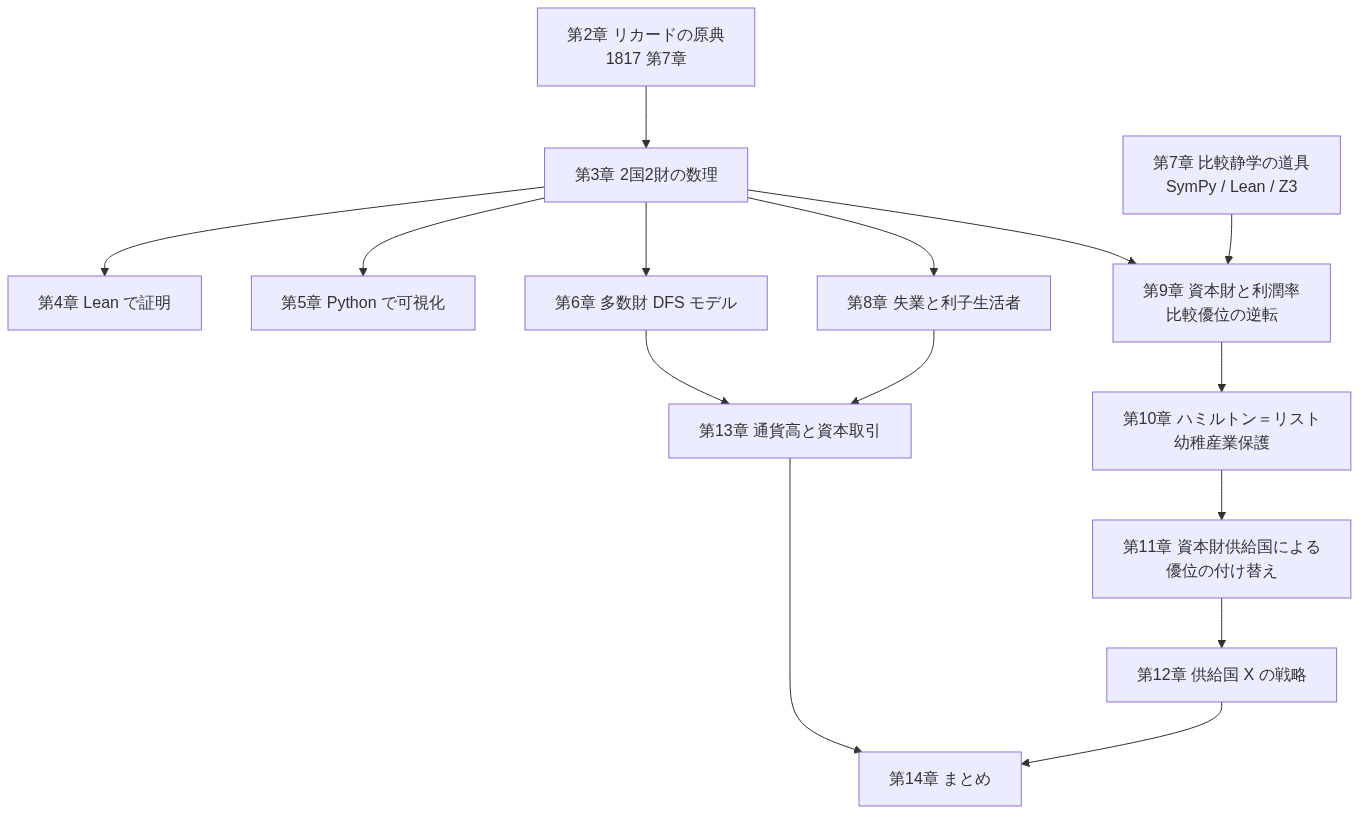

In [3]:
show_mermaid('''
graph TD
  R["第2章 リカードの原典<br/>1817 第7章"] --> M["第3章 2国2財の数理"]
  M --> L1["第4章 Lean で証明"]
  M --> P1["第5章 Python で可視化"]
  M --> D["第6章 多数財 DFS モデル"]
  T["第7章 比較静学の道具<br/>SymPy / Lean / Z3"] --> K1
  M --> U["第8章 失業と利子生活者"]
  M --> K1["第9章 資本財と利潤率<br/>比較優位の逆転"]
  K1 --> K2["第10章 ハミルトン＝リスト<br/>幼稚産業保護"]
  K2 --> K3["第11章 資本財供給国による<br/>優位の付け替え"]
  K3 --> X["第12章 供給国 X の戦略"]
  U --> F["第13章 通貨高と資本取引"]
  D --> F
  X --> S["第14章 まとめ"]
  F --> S
''')

---
# 2. リカードのオリジナル ― 『原理』第7章を読む

## 2.1 時代背景

デイヴィッド・リカード（David Ricardo, 1772–1823）は、ロンドンの証券仲買人として財をなした後、経済学に転じた人物です。主著『経済学および課税の原理』（*On the Principles of Political Economy and Taxation*）は 1817 年に初版、1819 年に第2版、1821 年に第3版が出ました。比較優位の議論は第7章「外国貿易について」（On Foreign Trade）にあります。

背景には、ナポレオン戦争（1803–1815）の終結と **穀物法**（Corn Laws, 1815）をめぐる論争がありました。穀物の輸入を制限すれば、劣等地まで耕作が進み、地代が上がり、賃金（穀物価格に連動）が上がり、利潤が圧迫される ― というのがリカードの診断で、彼は 1815 年の『穀物の低価格が資本の利潤に及ぼす影響についての試論』以来、穀物の自由な輸入を主張していました。比較優位論はこの文脈の中で生まれています。

比較優位の考え方の発見者については論争があります。ロバート・トレンズ（R. Torrens）が 1815 年の『穀物の外国貿易に関する試論』で同様の考えを述べていること、ジェームズ・ミル（James Mill）の関与などが論じられてきました（Ruffin 2002; Maneschi 1998; Gehrke 2015）。本ノートでは立ち入りませんが、「比較優位＝リカード」という等式は教科書的な単純化であることを覚えておきましょう。

アダム・スミス（1776）の『国富論』は、各国が他国より安く作れるもの（**絶対優位**）を作って交換すればよいと説きました。リカードの新しさは、**一方の国がすべての財で絶対優位をもっていても、なお交換が双方に有利になりうる**ことを示した点にあります。

なお、例に毛織物とワイン、イングランドとポルトガルが選ばれたのは偶然ではなく、両国間には 1703 年のメシュエン条約以来、イングランドの毛織物とポルトガルのワインを優遇しあう通商関係がありました。

## 2.2 四つの数字

リカードは次のように書いています（第3版、第7章。訳は本ノートによる）。

> England may be so circumstanced, that to produce the cloth may require the labour of 100 men for one year; and if she attempted to make the wine, it might require the labour of 120 men for the same time. England would therefore find it her interest to import wine, and to purchase it by the exportation of cloth.
>
> イングランドは、毛織物を生産するのに 1 年間に 100 人の労働を要し、もしワインを作ろうとすれば同じ期間に 120 人の労働を要するような状況にあるかもしれない。そうであればイングランドは、ワインを輸入し、それを毛織物の輸出によって購入するのが自国の利益であると気づくだろう。

> To produce the wine in Portugal, might require only the labour of 80 men for one year, and to produce the cloth in the same country, might require the labour of 90 men for the same time. It would therefore be advantageous for her to export wine in exchange for cloth. This exchange might even take place, notwithstanding that the commodity imported by Portugal could be produced there with less labour than in England.
>
> ポルトガルでワインを生産するには 1 年間に 80 人の労働しか要しないかもしれず、同じ国で毛織物を生産するには同じ期間に 90 人の労働を要するかもしれない。それゆえポルトガルにとっては、ワインを輸出して毛織物と交換するのが有利だろう。この交換は、ポルトガルが輸入する商品が、イングランドより少ない労働でポルトガル国内で生産できる場合でさえ、行われうるのである。

表にすると次のとおりです（単位：「その量」を 1 年で生産するのに要する人数）。

| | 毛織物 (cloth) | ワイン (wine) | 毛織物の機会費用（ワイン建て） |
|---|---:|---:|---:|
| イングランド | 100 | 120 | 100/120 ≈ 0.833 |
| ポルトガル | 90 | 80 | 90/80 = 1.125 |

ポルトガルは両方で少ない労働で済む（**両財に絶対優位**）のに、毛織物の機会費用はイングランドのほうが低い（**イングランドは毛織物に比較優位**）。

## 2.3 リカードは何を主張したのか

第7章の議論の要点を、本ノートの関心に沿って五つに整理します。

**(1) 貿易は「価値」を増やさないが、「享楽の総量」を増やす。** 章の冒頭でリカードはこう述べます。

> No extension of foreign trade will immediately increase the amount of value in a country, although it will very powerfully contribute to increase the mass of commodities, and therefore the sum of enjoyments.
>
> 外国貿易の拡大は、一国の価値の総額を直ちに増やすことはないが、商品の量を、したがって享楽の総和を増やすことに非常に強力に寄与する。

労働価値説に立つリカードにとって、一国の「価値」は投下労働で決まるので、貿易で価値総額は変わりません。変わるのは、同じ労働で手に入る**使用価値の量**です。

**(2) 利益は「節約された労働」として測られている。** イングランドは 100 人の労働の生産物（毛織物）で、自国なら 120 人を要したワインを手に入れます。ポルトガルは 80 人の労働の生産物（ワイン）で、自国なら 90 人を要した毛織物を手に入れます。

> Thus England would give the produce of the labour of 100 men, for the produce of the labour of 80.
>
> こうしてイングランドは、100 人の労働の生産物を、80 人の労働の生産物と交換するだろう。

両国が毛織物 1 単位・ワイン 1 単位ずつを消費し続けるとすれば、貿易によってイングランドは 20 人分、ポルトガルは 10 人分の労働が**不要になります**。リカードの数値例において「貿易の利益」とは、文字どおり**浮いた労働**のことなのです。この「浮いた労働」が何になるのか ― 追加の消費を作るのか、余暇か、失業か、それとも働かずに受け取る者の取り分になるのか ― が、JRF のメモ (M1) の核心に関わります（第3章・第8章）。

**(3) 国際間では労働価値説がそのまま成り立たない。**

> The same rule which regulates the relative value of commodities in one country, does not regulate the relative value of the commodities exchanged between two or more countries.
>
> 一国のなかで商品の相対価値を規定するのと同じ規則が、二国以上のあいだで交換される商品の相対価値を規定するわけではない。

**(4) その理由は、資本（と労働）が国境を越えて動かないことにある。** これは見落とされがちですが、本ノートにとって決定的に重要な点です。リカードははっきり書いています。

> It would undoubtedly be advantageous to the capitalists of England, and to the consumers in both countries, that under such circumstances, the wine and the cloth should both be made in Portugal, and therefore that the capital and labour of England employed in making cloth, should be removed to Portugal for that purpose.
>
> このような状況のもとでは、ワインも毛織物もポルトガルで作られ、そのためにイングランドで毛織物製造に使われている資本と労働がポルトガルへ移されることが、イングランドの資本家にとっても両国の消費者にとっても疑いなく有利であろう。

それが起きないのは、自分の目の届かない資本の不安と、生まれた国を離れたがらない人々の自然な気持ちが「資本の移出を抑える」からだ、とリカードは続けます。

つまり **比較優位論は「資本が国際的に移動しない」ことを前提にした理論**です。資本が自由に動くなら、生産は絶対優位をもつ国に集まり、イングランドの資本家はポルトガルで利潤を得る ― すなわち**外国からの利潤で暮らす者（利子生活者・不在資本家）**になり、イングランドの労働者は職を失う（移住しない限り）。JRF のメモ (M3)「比較優位を資本取引のからむ議論につなげるのは慎重に」は、リカード自身の前提から直接に支持されるのです（第13章）。

**(5) 貨幣は、物々交換の結果を再現するように配分される。**

> Gold and silver having been chosen for the general medium of circulation, they are, by the competition of commerce, distributed in such proportions amongst the different countries of the world, as to accommodate themselves to the natural traffic which would take place if no such metals existed, and the trade between countries were purely a trade of barter.
>
> 金と銀が一般的な流通手段として選ばれているので、それらは商業の競争によって世界の諸国のあいだに、そうした金属が存在せず国家間の貿易が純粋に物々交換であった場合に生じるであろう自然な取引に適合するような割合で配分される。

リカードのモデルは**実物（物々交換）モデル**で、貨幣（為替・通貨高）は長期的には実物の比較優位に従属する、という立場です。逆にいえば、資本収支が実物取引から独立に動く世界（現代の国際金融）では、この前提が崩れます。

## 2.4 技術の変化は比較優位を変える ― リカード自身の注意

同じ第7章でリカードは、イングランドがワインを作る新しい方法を発見して、ワインを輸入するより自分で作るほうが得になった場合を考察しています（趣旨）。そのときイングランドは資本の一部を外国貿易から国内向けに振り向け、輸出用の毛織物の製造をやめ、ワインを自給するようになり、貨幣（金）の移動を通じて新しい取引パターンへ調整が起こる、というのです。

つまり**比較優位は技術の関数であり、技術が変われば変わる**ことをリカード自身が認めています。JRF の 2011 年のメモ (M0)「過去の設備による優位は、設備を革新する者に容易にくつがえされる」は、この点を、技術変化を**誰が起こし、誰が制御するのか**という問題として先鋭化させたものと読めます。第10〜12章では、技術（生産性）を時間とともに動く状態変数として扱い、この問題をモデル化します。

## 2.5 「数字の読み方」の論争

教科書は通常、100・120・90・80 を「1 単位あたりの労働投入係数」と読みます。しかしリカードの文章は「the cloth」「the wine」と特定の量を指しており、ラフィン（Ruffin 2002）らは、これは**実際に交換される量**を生産するのに要する労働であって、交換比率は 1 対 1 に固定されている、と読みます。この読み方では、リカードは交易条件の決定（相互需要）の問題を扱っておらず、それは後に J. S. ミル（1848）が補った、ということになります。

本ノートでは、両方の読み方に対応できるよう、第3章で

* 労働投入係数 $a_{ij}$ による標準的な定式化と、
* 消費量を固定して「節約される労働」を測る定式化（リカードの原文に近い）

の両方を扱います。後者で交易条件を 1 対 1 から動かすと、「浮いた労働」が**どちらの国にどれだけ生じるか**が交易条件しだいで変わることがわかります（第3.6節）。

## 2.6 「論理的に正しく、しかも自明でない」

数学者スタニスワフ・ウラムがポール・サミュエルソンに「社会科学の命題で、真であってかつ自明でないものを一つ挙げてみよ」と問うたとき、サミュエルソンは比較優位の原理を挙げた、という逸話はよく知られています（Samuelson 1969）。

> That it is logically true need not be argued before a mathematician; that it is not trivial is attested by the thousands of important and intelligent men who have never been able to grasp the doctrine for themselves or to believe it after it was explained to them.

「論理的に真であること」は、まさに Lean で検証できる種類の性質です（第4章）。しかし「自明でない」ことの裏には、**前提（完全雇用、資本の国際的不動性、実物交換、技術の固定）がどれほど効いているか**が見えにくい、という事情もあります。本ノートの後半は、その前提を一つずつ外していく作業です。

---
# 3. 2国2財モデルの数理

## 3.1 設定

* 国：自国 H と外国 F（外国の変数には $^{\ast}$ を付ける）。
* 財：財1（毛織物）と財2（ワイン）。
* 生産要素：労働のみ。自国の労働量 $L$、外国の労働量 $L^{\ast}$。国内では産業間を自由に移動し、国境は越えない。
* 技術：財 $i$ を 1 単位生産するのに要する労働（**労働投入係数**）を自国 $a_i$、外国 $a_i^{\ast}$ とする（すべて正）。収穫一定。
* 市場：完全競争。

自国の**生産可能性フロンティア**（PPF）は

$$
a_1 Q_1 + a_2 Q_2 = L, \qquad Q_1, Q_2 \ge 0
$$

という直線です。ここで $Q_1, Q_2$ は自国の財1・財2の**生産量**です（外国の生産量は $Q_1^{\ast}, Q_2^{\ast}$）。その傾き（の絶対値）$a_1/a_2$ は「財1を 1 単位増やすために諦めなければならない財2の量」、すなわち**財1の機会費用**です。

## 3.2 自給自足（アウタルキー）の価格

労働 1 単位あたりの賃金を $w$、財 $i$ の価格を $p_i$ とすると、完全競争のもとで、生産される財の価格は単位費用に等しくなります：$p_i = w\,a_i$（外国では $w^{\ast}$, $p_i^{\ast}$）。両財が生産されていれば、

$$
\left(\frac{p_1}{p_2}\right)^{\mathrm{aut}} = \frac{a_1}{a_2}, \qquad
\left(\frac{p_1}{p_2}\right)^{\mathrm{aut}\ast} = \frac{a_1^{\ast}}{a_2^{\ast}} .
$$

相対価格は**技術だけで決まり、需要に依存しません**（労働しか要素がなく収穫一定だから）。これは労働価値説の最も単純な形です。

## 3.3 絶対優位と比較優位

**定義 3.1**　自国は財1に**絶対優位**をもつ ⇔ $a_1 < a_1^{\ast}$。

**定義 3.2**　自国は財1に**比較優位**をもつ ⇔
$$\frac{a_1}{a_2} < \frac{a_1^{\ast}}{a_2^{\ast}} \quad\Longleftrightarrow\quad a_1 a_2^{\ast} < a_1^{\ast} a_2 .$$

右側の「分母を払った形」は、Lean で扱うときに割り算を避けられるので便利です（第4章ではこちらを定義に採用し、左側との同値性を定理として証明します）。

**命題 3.3（比較優位の相互性と排他性）**
1. 自国が財1に比較優位をもつ ⇔ 外国が財2に比較優位をもつ。
2. 一国が両財に同時に比較優位をもつことはない。

*証明*　1. 外国が財2に比較優位をもつとは $a_2^{\ast} a_1 < a_2 a_1^{\ast}$ のことで、積の交換法則によりこれは $a_1 a_2^{\ast} < a_1^{\ast} a_2$ と同じ不等式である。 2. 自国が財2に比較優位をもつとは $a_2 a_1^{\ast} < a_2^{\ast} a_1$、すなわち $a_1^{\ast} a_2 < a_1 a_2^{\ast}$ であり、定義 3.2 の不等式と両立しない。∎

絶対優位は両財で同時にもてますが、比較優位はもてません。**比較優位は「相対的な得意・不得意」の概念なので、誰でも必ず何かに比較優位をもつ**（両国の機会費用がちょうど等しい場合を除く）のです。

## 3.4 貿易均衡

貿易が始まると、両国は共通の国際相対価格 $p = p_1/p_2$ に直面します（財2を価値尺度財とし、$p_2 = 1$）。自国で財 $i$ を作る労働者が得られる賃金は $p_i / a_i$ なので、

* $p/a_1 > 1/a_2$、すなわち $p > a_1/a_2$ なら、自国の労働者は全員が財1を作る（**財1に完全特化**）。
* $p < a_1/a_2$ なら財2に完全特化。
* $p = a_1/a_2$ なら、どちらを作っても同じ（不完全特化もありうる）。

外国も同様です。自国が財1に比較優位をもつ（$a_1/a_2 < a_1^{\ast}/a_2^{\ast}$）とすると、世界の**相対供給曲線**（Relative Supply；世界の財1の生産量と財2の生産量の比を価格 $p$ の関数として見たもの）$RS(p) = (Q_1 + Q_1^{\ast})/(Q_2+Q_2^{\ast})$ は次の階段状になります。

$$
RS(p) =
\begin{cases}
0 & (p < a_1/a_2) \\
[\,0,\; \dfrac{L/a_1}{L^{\ast}/a_2^{\ast}}\,] & (p = a_1/a_2) \\
\dfrac{L/a_1}{L^{\ast}/a_2^{\ast}} & (a_1/a_2 < p < a_1^{\ast}/a_2^{\ast}) \\
[\,\dfrac{L/a_1}{L^{\ast}/a_2^{\ast}},\; \infty\,) & (p = a_1^{\ast}/a_2^{\ast}) \\
\infty & (p > a_1^{\ast}/a_2^{\ast})
\end{cases}
$$

需要の側は、両国の消費者が所得の一定割合 $\beta$（$0<\beta<1$）を財1に、残り $1-\beta$ を財2に支出するとします。これは効用関数（消費から得られる満足の度合い）
$$
U = C_1^{\beta} C_2^{1-\beta}
$$
をもつ消費者の行動で、**コブ＝ダグラス型効用**と呼ばれます。$C_1, C_2$ は自国の財1・財2の**消費量**（外国は $C_1^{\ast}, C_2^{\ast}$）、$U$ は効用です。この型の効用では、価格がどう変わっても支出の割合が一定（$p_1C_1 = \beta \times \text{所得}$）になるので計算が簡単になります。このとき世界の**相対需要**は

$$
RD(p) = \frac{C_1 + C_1^{\ast}}{C_2 + C_2^{\ast}} = \frac{\beta}{1-\beta}\cdot\frac{1}{p}
$$

です。均衡価格 $p^{e}$ は $RS(p) = RD(p)$ で決まり、次の三つの場合があります。

1. **両国が完全特化**：$p^{e} = \dfrac{\beta}{1-\beta}\cdot\dfrac{L^{\ast}/a_2^{\ast}}{L/a_1}$ が開区間 $(a_1/a_2,\; a_1^{\ast}/a_2^{\ast})$ に入るとき。
2. **自国（財1の国）が不完全特化**：自国が「大国」で財1を作りすぎる場合、$p^{e} = a_1/a_2$。このとき自国は貿易の利益を得られず、利益は全部外国へ行く。
3. **外国が不完全特化**：$p^{e} = a_1^{\ast}/a_2^{\ast}$。利益は全部自国へ。

「小国は大国との貿易で得をしやすい」という性質（**小国の利益**）はここから出てきます。

## 3.5 貿易の利益の定理

自国が財1に完全特化し、国際価格 $p$ で交換するとき、自国の消費可能集合（**消費可能性フロンティア** CPF の内側）は

$$
\mathcal{T}_1(p) = \{(q_1, q_2) \ge 0 \;:\; p\,q_1 + q_2 \le p\,L/a_1\}
$$

です（$q_1, q_2$ は財1・財2の消費量。$\mathcal{T}_1(p)$ の不等式は、財2を単位として測った**予算制約**：消費の価値 $p\,q_1 + q_2$ が、財1に特化して得る所得 $p\,L/a_1$ を超えない）。自給自足の消費可能集合は $\mathcal{A} = \{(q_1, q_2)\ge 0 : a_1 q_1 + a_2 q_2 \le L\}$ です。

**定理 3.4（貿易の利益）**　$p \ge a_1/a_2$ ならば $\mathcal{A} \subseteq \mathcal{T}_1(p)$。さらに $p > a_1/a_2$ ならば、$q_2 > 0$ である任意の $(q_1,q_2) \in \mathcal{A}$ は $\mathcal{T}_1(p)$ の予算線の厳密に内側にある。

*証明*　$p \ge a_1/a_2$ は $a_1 \le p\,a_2$ と同値。$(q_1, q_2) \in \mathcal{A}$ とすると
$$
a_1 (p\,q_1 + q_2) = p\,a_1 q_1 + a_1 q_2 \;\le\; p\,a_1 q_1 + p\,a_2 q_2 = p\,(a_1 q_1 + a_2 q_2) \;\le\; p\,L .
$$
両辺を $a_1 > 0$ で割れば $p\,q_1 + q_2 \le pL/a_1$。$p > a_1/a_2$ かつ $q_2 > 0$ なら最初の不等号が厳密になる。∎

財2に特化する外国についても、$p \le a_1^{\ast}/a_2^{\ast}$ なら同様に $\mathcal{A}^{\ast} \subseteq \mathcal{T}_2^{\ast}(p) = \{p\,q_1 + q_2 \le L^{\ast}/a_2^{\ast}\}$ が成り立ちます。

**系 3.5（相互利益）**　自国が財1に比較優位をもつなら、$a_1/a_2 < p < a_1^{\ast}/a_2^{\ast}$ を満たす $p$ が存在し（実数の稠密性）、そのような $p$ のもとでは両国がともに厳密に得をする。

この定理の主張は、「何を消費しても、自給自足のときと同じかそれ以上を消費できる」という**集合の包含**です。誰がそれを消費するのか（分配）、増えた分を誰が受け取るのかについては、何も述べていないことに注意してください。JRF が 2011 年に「このモデルはすべてが分配されたときのことを考えている」と書いたのは、この点を指しています。

**実質賃金で見ると**：財1に特化した自国の労働者の賃金は $w = p_1/a_1$ なので、財1で測った実質賃金は $1/a_1$（不変）、財2で測った実質賃金は $p/a_1 \ge 1/a_2$（自給自足のときの $1/a_2$ 以上）。労働しか要素がないので、貿易の利益はすべて労働者の実質賃金の上昇として現れます。**このモデルには利潤も地代も利子もありません。** ここが、後で資本を入れたとき（第9章以降）に話が変わる根本的な理由です。

## 3.6 「節約された労働」としての貿易の利益

リカードの原文に近い形で、**消費量を固定**して必要な労働を比べてみます。自国が財1を $c_1$、財2を $c_2$ だけ消費する（消費量の組 $(c_1, c_2)$）のに必要な労働は、

* 自給自足：$a_1 c_1 + a_2 c_2$
* 財1に特化し、財2を価格 $p$ で輸入：財2の $c_2$ を得るには財1を $c_2/p$ だけ余分に作ればよいので、$a_1\,(c_1 + c_2/p)$

**定理 3.6（労働の節約）**　$p \ge a_1/a_2$, $p > 0$, $c_2 \ge 0$ なら $a_1(c_1 + c_2/p) \le a_1 c_1 + a_2 c_2$。

（証明は定理 3.4 と同じ不等式 $a_1 c_2 \le p\,a_2 c_2$ による。）

リカードの数値で、両国がそれぞれ毛織物 1・ワイン 1 を消費し続けるとします。交易条件（輸出品と輸入品の交換比率）を $\tau$（ワイン 1 単位と交換される毛織物の量）とし、イングランド・ポルトガルで浮く労働を $S_E, S_P$ と書くと、

* イングランド：毛織物 $1+\tau$ 単位を作ればよいので、必要労働 $100(1+\tau)$。節約 $S_E(\tau) = 220 - 100(1+\tau) = 120 - 100\tau$。
* ポルトガル：ワイン $1 + 1/\tau$ 単位を作ればよいので、必要労働 $80(1+1/\tau)$。節約 $S_P(\tau) = 170 - 80(1 + 1/\tau) = 90 - 80/\tau$。

| 交易条件 $\tau$ | イングランドの節約 | ポルトガルの節約 | 合計 |
|---|---:|---:|---:|
| $8/9 \approx 0.889$（ポルトガルの自給価格） | 31.1 | 0 | 31.1 |
| $1$（リカードの例） | **20** | **10** | 30 |
| $6/5 = 1.2$（イングランドの自給価格） | 0 | 23.3 | 23.3 |

**命題 3.7**　$8/9 \le \tau \le 6/5$ なら $S_E(\tau) \ge 0$, $S_P(\tau) \ge 0$, $S_E(\tau) + S_P(\tau) > 0$。

*証明*　$S_E \ge 0 \Leftrightarrow \tau \le 6/5$、$S_P \ge 0 \Leftrightarrow 80/\tau \le 90 \Leftrightarrow \tau \ge 8/9$。合計については $\tau > 0$ を掛けて $-100\tau^2 + 210\tau - 80 > 0$ を示せばよい。$-100\tau^2 + 210\tau - 80 = 100(\tau - 8/9)(6/5 - \tau) + \tfrac{10}{9}\tau + \tfrac{80}{3}$（展開して確かめられる）で、第1項は区間内で非負、残りは正。∎

ここから二つのことが読み取れます。

1. **「浮いた労働」がどちらの国に生じるかは、絶対優位ではなく交易条件で決まる。** 両財で優位にあるポルトガルが多く節約するとは限りません。リカード自身の 1 対 1 の例では、むしろ劣位のイングランドが 2 倍節約しています。したがって「優位国に失業が生じ、劣位国に雇用が残る」という対称的なバランス論は、このモデルの定理ではありません。
2. **浮いた労働は「利益」そのもの**です。消費を固定したまま浮いた労働は、余暇になるか、追加の生産に使われるか、あるいは働かずに分け前を受け取る人の生活を支えるか、のいずれかです。それを「失業」と呼ぶなら、その失業は**貿易の利益を、働かないという形で受け取っている状態**であり、構造的には利子生活者の立場に近い ― これが (M1) の一つの数学的な読み方です。第8章では、需要が増えないときにこの浮いた労働が実際の「失業」として現れるモデルを扱います。

命題 3.7 の証明中の恒等式と表の数値を、SymPy で確かめておきます。

In [4]:
tau = sp.symbols('tau', positive=True)
S_E = 220 - 100*(1 + tau)
S_P = 170 - 80*(1 + 1/tau)
identity = sp.expand(100*(tau - sp.Rational(8, 9))*(sp.Rational(6, 5) - tau)
                     + sp.Rational(10, 9)*tau + sp.Rational(80, 3) - (-100*tau**2 + 210*tau - 80))
print('恒等式の差 =', identity)
for t in [sp.Rational(8, 9), 1, sp.Rational(6, 5)]:
    se, sP = S_E.subs(tau, t), S_P.subs(tau, t)
    print(f'tau = {str(t):>4}:  England {float(se):6.2f}   Portugal {float(sP):6.2f}   total {float(se + sP):6.2f}')

恒等式の差 = 0
tau =  8/9:  England  31.11   Portugal   0.00   total  31.11
tau =    1:  England  20.00   Portugal  10.00   total  30.00
tau =  6/5:  England   0.00   Portugal  23.33   total  23.33


## 3.7 2011年のウィキペディアの数値例を検算する

1.2 節で見た 2011 年版のウィキペディアは、「1 人が一定時間に作れる量」で次の例を挙げていました。

| | ワイン | 毛織物 |
|---|---:|---:|
| 大国 | 10 | 5 |
| 小国 | 9 | 3 |

労働投入係数に直すと、大国 $a_{\text{wine}} = 1/10$, $a_{\text{cloth}} = 1/5$、小国 $1/9$, $1/3$。大国は両財に絶対優位をもち、毛織物の機会費用は大国 $2$ 本、小国 $3$ 本なので、**大国は毛織物、小国はワインに比較優位**をもちます。

各国 200 人が 100 人ずつ両財に従事していた状態（ワイン 1900・毛織物 800）から、大国が毛織物に 180 人・ワインに 20 人、小国がワインに 200 人を投じると、ワイン 2000・毛織物 900 となり、両財とも世界の生産が増えます。記事は「小国から大国にワイン 850、大国から小国に毛織物 350」を例として、両国の消費が増えることを示していました（交換比率は毛織物 1 = ワイン 850/350 ≈ 2.43 で、両国の機会費用 2 と 3 の間にあります）。

この例は、第5章で Python によって検算します。ここで注目したいのは、その直後に「両国とも 100 人が失業している状態で自由貿易を行えば、比較優位の大国は完全雇用を達成し、比較劣位の小国は全員に近い人数が失業する」と書かれていた点です。**この主張は完全雇用を前提とする上の議論とは別のモデルに属します。**需要が固定され、賃金や為替が硬直的なとき、生産を引き受けるのは「比較優位」ではなく「貨幣で測った絶対的な安さ」をもつ国になる ― これを第8章でモデル化し、検算します。

---
# 4. Lean による形式化 I ― 比較優位と貿易の利益

この章では、第3章の定義と定理を Lean 4 (Mathlib) で書き、機械的に検証できる形にします。Lean に初めて触れる読者のために、最低限の読み方を述べておきます。

* `structure` は「いくつかのデータと、それが満たす条件」をひとまとめにした型です。下の `Tech` は「正の労働投入係数 2 つ」をまとめたもの。
* `def` は定義、`theorem` は定理です。`theorem 名前 (仮定) : 結論 := by 証明` と書きます。
* `by` 以下は**タクティク**（証明の手順）。`linarith`（線形不等式の自動証明）、`nlinarith`（非線形を含む不等式）、`norm_num`（数値計算）、`field_simp`（分母を払う）、`positivity`（正であることの自動証明）などが頻出します。
* `ℝ` は実数。`/-- ... -/` は直後の定義・定理への説明文（ドキュメント・コメント）です。

ここでは**分母を払った形**の定義（$a_1 a_2^{\ast} < a_1^{\ast} a_2$）を採用し、割り算による定義との同値性を最初の定理として示します。割り算は、ゼロ除算の扱い（Lean では $x/0 = 0$ と約束される）に気を配る必要があるので、可能な限り避けるのが形式化のコツです。

In [5]:
%%writefile lean_src/ch04_ricardo.lean
/-! ## 第4章 2国2財リカード・モデル -/
namespace Ricardo

/-- 一国の技術: 財1・財2 を 1 単位つくるのに要する労働量（労働投入係数）。 -/
structure Tech where
  a1 : ℝ
  a2 : ℝ
  pos1 : 0 < a1
  pos2 : 0 < a2

/-- 自国 `h` は外国 `f` に対して財1に比較優位をもつ（`a1/a2 < a1*/a2*` を分母を払って書いたもの）。 -/
def CompAdv1 (h f : Tech) : Prop := h.a1 * f.a2 < f.a1 * h.a2

/-- 自国 `h` は外国 `f` に対して財2に比較優位をもつ。 -/
def CompAdv2 (h f : Tech) : Prop := h.a2 * f.a1 < f.a2 * h.a1

/-- 分母を払った定義は、教科書どおりの「機会費用の比較」と同値。 -/
theorem compAdv1_iff_ratio (h f : Tech) :
    CompAdv1 h f ↔ h.a1 / h.a2 < f.a1 / f.a2 := by
  unfold CompAdv1
  rw [div_lt_div_iff₀ h.pos2 f.pos2]

/-- 比較優位は相互的: 自国が財1に比較優位 ↔ 外国が財2に比較優位。 -/
theorem compAdv_mutual (h f : Tech) : CompAdv1 h f ↔ CompAdv2 f h := by
  unfold CompAdv1 CompAdv2
  constructor <;> intro H <;> linarith [mul_comm h.a1 f.a2, mul_comm f.a1 h.a2]

/-- どの国も両方の財に同時に比較優位をもつことはできない。 -/
theorem not_compAdv_both (h f : Tech) : ¬ (CompAdv1 h f ∧ CompAdv2 h f) := by
  rintro ⟨H1, H2⟩
  unfold CompAdv1 CompAdv2 at *
  linarith [mul_comm h.a2 f.a1, mul_comm f.a2 h.a1]

Overwriting lean_src/ch04_ricardo.lean


`compAdv1_iff_ratio` は Mathlib の補題 `div_lt_div_iff₀`（$0<b, 0<d$ のとき $a/b < c/d \Leftrightarrow ad < cb$）で一行で済みます。相互性 `compAdv_mutual` と排他性 `not_compAdv_both` は、積の交換法則を `linarith` に教えるだけで証明できます。命題 3.3 の「証明」が本質的に交換法則だけだったことが、ここではっきりします。

次に、リカードの数値と、2011 年版ウィキペディアの数値を入れて確かめます。

In [6]:
%%writefile -a lean_src/ch04_ricardo.lean

/-- リカードの数値例: イングランド（毛織物 100 人・ワイン 120 人）。 -/
def england : Tech := ⟨100, 120, by norm_num, by norm_num⟩
/-- リカードの数値例: ポルトガル（毛織物 90 人・ワイン 80 人）。 -/
def portugal : Tech := ⟨90, 80, by norm_num, by norm_num⟩

/-- ポルトガルは両財に絶対優位をもつ。 -/
theorem portugal_absolute_advantage :
    portugal.a1 < england.a1 ∧ portugal.a2 < england.a2 := by
  norm_num [portugal, england]

/-- それでもイングランドは毛織物（財1）に比較優位をもつ。 -/
theorem england_compAdv_cloth : CompAdv1 england portugal := by
  unfold CompAdv1
  norm_num [england, portugal]

/-- 相互性より、ポルトガルはワイン（財2）に比較優位をもつ。 -/
theorem portugal_compAdv_wine : CompAdv2 portugal england :=
  (compAdv_mutual england portugal).1 england_compAdv_cloth

/-- 2011年版ウィキペディアの例の「大国」（毛織物 1/5・ワイン 1/10 人時/単位）。 -/
noncomputable def wikiBig : Tech := ⟨1/5, 1/10, by norm_num, by norm_num⟩
/-- 同じく「小国」（毛織物 1/3・ワイン 1/9）。 -/
noncomputable def wikiSmall : Tech := ⟨1/3, 1/9, by norm_num, by norm_num⟩

/-- 大国は両財に絶対優位をもちつつ、毛織物に比較優位、小国はワインに比較優位をもつ。 -/
theorem wiki2011_pattern :
    (wikiBig.a1 < wikiSmall.a1 ∧ wikiBig.a2 < wikiSmall.a2) ∧
    CompAdv1 wikiBig wikiSmall ∧ CompAdv2 wikiSmall wikiBig := by
  refine ⟨by norm_num [wikiBig, wikiSmall], ?_, ?_⟩
  · unfold CompAdv1; norm_num [wikiBig, wikiSmall]
  · unfold CompAdv2; norm_num [wikiBig, wikiSmall]

Appending to lean_src/ch04_ricardo.lean


続いて、貿易の利益の定理（定理 3.4・系 3.5）です。消費可能集合を `Set (ℝ × ℝ)` として定義し、**集合の包含** `⊆` として定理を述べます。予算制約は、割り算を避けて両辺に $a_1$ を掛けた形で書いています。

`mutual_gains` では、`exists_between`（実数の稠密性：$x<y$ なら $x<p<y$ となる $p$ がある）を使って、両国が得をする国際価格の**存在**を示します。

In [7]:
%%writefile -a lean_src/ch04_ricardo.lean

/-- 自給自足のもとでの消費可能集合（＝生産可能集合）。 -/
def AutarkySet (t : Tech) (L : ℝ) : Set (ℝ × ℝ) :=
  {q | 0 ≤ q.1 ∧ 0 ≤ q.2 ∧ t.a1 * q.1 + t.a2 * q.2 ≤ L}

/-- 財1に完全特化し、国際相対価格 `p`（財1の財2建て価格）で交換したときの消費可能集合。
  予算制約 `p q₁ + q₂ ≤ p L / a₁` の両辺に `a₁` を掛けた形で書く。 -/
def Trade1Set (t : Tech) (L p : ℝ) : Set (ℝ × ℝ) :=
  {q | 0 ≤ q.1 ∧ 0 ≤ q.2 ∧ t.a1 * (p * q.1 + q.2) ≤ p * L}

/-- 財2に完全特化したときの消費可能集合（予算制約 `p q₁ + q₂ ≤ L / a₂`）。 -/
def Trade2Set (t : Tech) (L p : ℝ) : Set (ℝ × ℝ) :=
  {q | 0 ≤ q.1 ∧ 0 ≤ q.2 ∧ t.a2 * (p * q.1 + q.2) ≤ L}

/-- **貿易の利益（財1に特化する国）**: `p ≥ a₁/a₂` なら自給自足で可能な消費はすべて貿易でも可能。 -/
theorem gains_from_trade_spec1 (t : Tech) (L p : ℝ) (hp : t.a1 ≤ p * t.a2) :
    AutarkySet t L ⊆ Trade1Set t L p := by
  rintro ⟨q1, q2⟩ ⟨h1, h2, hL⟩
  refine ⟨h1, h2, ?_⟩
  have hp0 : 0 ≤ p := by
    by_contra hneg
    have := not_le.mp hneg
    nlinarith [t.pos1, t.pos2]
  have e1 : t.a1 * q2 ≤ p * t.a2 * q2 := mul_le_mul_of_nonneg_right hp h2
  have e2 : p * (t.a1 * q1 + t.a2 * q2) ≤ p * L := mul_le_mul_of_nonneg_left hL hp0
  nlinarith [e1, e2]

/-- **貿易の利益（財2に特化する国）**: `p ≤ a₁/a₂` なら自給自足で可能な消費はすべて貿易でも可能。 -/
theorem gains_from_trade_spec2 (t : Tech) (L p : ℝ) (hp : p * t.a2 ≤ t.a1) :
    AutarkySet t L ⊆ Trade2Set t L p := by
  rintro ⟨q1, q2⟩ ⟨h1, h2, hL⟩
  refine ⟨h1, h2, ?_⟩
  have e1 : p * t.a2 * q1 ≤ t.a1 * q1 := mul_le_mul_of_nonneg_right hp h1
  nlinarith [e1]

/-- **厳密な利益**: `p > a₁/a₂` のとき、財2を正の量だけ含む自給自足の消費点は、
  貿易後の予算線の厳密に内側にある（＝何かをもっと多く消費できる）。 -/
theorem strict_gains_spec1 (t : Tech) (L p q1 q2 : ℝ) (hp : t.a1 < p * t.a2)
    (hq2 : 0 < q2) (hL : t.a1 * q1 + t.a2 * q2 ≤ L) :
    t.a1 * (p * q1 + q2) < p * L := by
  have hp0 : 0 < p := by
    by_contra hneg
    have := not_lt.mp hneg
    nlinarith [t.pos1, t.pos2]
  have e1 : t.a1 * q2 < p * t.a2 * q2 := mul_lt_mul_of_pos_right hp hq2
  have e2 : p * (t.a1 * q1 + t.a2 * q2) ≤ p * L := mul_le_mul_of_nonneg_left hL hp0.le
  nlinarith [e1, e2]

/-- **相互利益の定理**: 自国が財1に比較優位をもつなら、両国がともに（厳密に）得をする
  国際価格 `p` が存在する。 -/
theorem mutual_gains (h f : Tech) (Lh Lf : ℝ) (hca : CompAdv1 h f) :
    ∃ p : ℝ, h.a1 < p * h.a2 ∧ p * f.a2 < f.a1 ∧
      AutarkySet h Lh ⊆ Trade1Set h Lh p ∧ AutarkySet f Lf ⊆ Trade2Set f Lf p := by
  rw [compAdv1_iff_ratio] at hca
  obtain ⟨p, hp1, hp2⟩ := exists_between hca
  have hp1' : h.a1 < p * h.a2 := (div_lt_iff₀ h.pos2).1 hp1
  have hp2' : p * f.a2 < f.a1 := (lt_div_iff₀ f.pos2).1 hp2
  exact ⟨p, hp1', hp2', gains_from_trade_spec1 h Lh p hp1'.le,
    gains_from_trade_spec2 f Lf p hp2'.le⟩

Appending to lean_src/ch04_ricardo.lean


最後に、定理 3.6（労働の節約）と命題 3.7（リカードの数値例での節約の配分）です。`ricardo_saving` の証明で `nlinarith` に与えているヒント `mul_nonneg (sub_nonneg.2 h1) (sub_nonneg.2 h2)` は、手の証明で使った $(\tau - 8/9)(6/5 - \tau) \ge 0$ そのものです。手の証明の「アイデア」を、機械には「ヒント」として渡す ― これが対話的定理証明の典型的な姿です。

In [8]:
%%writefile -a lean_src/ch04_ricardo.lean

/-- **労働の節約としての貿易の利益**: 消費量 `(c₁, c₂)` を固定したとき、財1に特化して
  財2を輸入すれば、必要労働 `a₁(c₁ + c₂/p)` は自給自足の必要労働 `a₁c₁ + a₂c₂` 以下になる。 -/
theorem labor_saving_spec1 (t : Tech) (p c1 c2 : ℝ) (hp0 : 0 < p) (hp : t.a1 ≤ p * t.a2)
    (hc2 : 0 ≤ c2) :
    t.a1 * (c1 + c2 / p) ≤ t.a1 * c1 + t.a2 * c2 := by
  have key : t.a1 * (c2 / p) ≤ t.a2 * c2 := by
    rw [mul_div_assoc', div_le_iff₀ hp0]
    nlinarith [mul_le_mul_of_nonneg_right hp hc2]
  linarith [mul_add t.a1 c1 (c2 / p)]

/-- イングランドの節約労働（各国が毛織物1・ワイン1を消費、交易条件 `τ` = ワイン1単位あたり毛織物）。 -/
noncomputable def savingEngland (τ : ℝ) : ℝ := (100 + 120) - 100 * (1 + τ)
/-- ポルトガルの節約労働。 -/
noncomputable def savingPortugal (τ : ℝ) : ℝ := (90 + 80) - 80 * (1 + 1 / τ)

/-- リカード自身が述べた 1:1 の交換では、イングランドは 20 人、ポルトガルは 10 人分の労働を節約する。 -/
theorem ricardo_one_to_one : savingEngland 1 = 20 ∧ savingPortugal 1 = 10 := by
  norm_num [savingEngland, savingPortugal]

/-- 交易条件が両国の自給価格のあいだ（`8/9 ≤ τ ≤ 6/5`）にある限り、どちらの国も労働を節約し、
  世界全体では厳密に節約が生じる。 -/
theorem ricardo_saving (τ : ℝ) (h1 : 8 / 9 ≤ τ) (h2 : τ ≤ 6 / 5) :
    0 ≤ savingEngland τ ∧ 0 ≤ savingPortugal τ ∧ 0 < savingEngland τ + savingPortugal τ := by
  have hτ : 0 < τ := by linarith
  unfold savingEngland savingPortugal
  refine ⟨by linarith, ?_, ?_⟩
  · have : 80 / τ ≤ 90 := by rw [div_le_iff₀ hτ]; linarith
    have e : 80 * (1 + 1 / τ) = 80 + 80 / τ := by ring
    linarith
  · have : 80 / τ < 210 - 100 * τ := by
      rw [div_lt_iff₀ hτ]
      nlinarith [mul_nonneg (sub_nonneg.2 h1) (sub_nonneg.2 h2)]
    have e : 80 * (1 + 1 / τ) = 80 + 80 / τ := by ring
    linarith

end Ricardo

Appending to lean_src/ch04_ricardo.lean


### この章で検証された（巻末で検証される）こと

| 定理（Lean 名） | 内容 |
|---|---|
| `compAdv1_iff_ratio` | 分母を払った定義と機会費用の比較の同値性 |
| `compAdv_mutual`, `not_compAdv_both` | 比較優位の相互性・排他性（命題 3.3） |
| `portugal_absolute_advantage`, `england_compAdv_cloth` | リカードの数値：絶対優位と比較優位の食い違い |
| `wiki2011_pattern` | 2011年版ウィキペディアの数値例の比較優位パターン |
| `gains_from_trade_spec1/2`, `strict_gains_spec1` | 貿易の利益（定理 3.4） |
| `mutual_gains` | 相互利益をもたらす国際価格の存在（系 3.5） |
| `labor_saving_spec1` | 労働の節約（定理 3.6） |
| `ricardo_one_to_one`, `ricardo_saving` | リカードの 20 人・10 人と、節約の配分（命題 3.7） |

形式化してみると、**これらの定理には「誰が消費するか」「浮いた労働がどうなるか」という変数がそもそも登場しない**ことがよくわかります。定理は正しい。しかし定理が語らないことを、定理が語っているかのように読むと誤る ― JRF の (M1)(M3) の警告は、この「語らない部分」に向けられています。

---
# 5. Python によるシミュレーション I ― 生産可能性・世界均衡・交易条件

## 5.1 PPF と CPF（Gemini さんのコードをもとに）

会話の中で Gemini さんが示したコードを、両国を並べて描くように拡張したものです。自国は両財で絶対劣位（$a_1 = 2, a_2 = 4$）、外国は両財で絶対優位（$a_1^{\ast} = a_2^{\ast} = 1$）です。自国の機会費用は $0.5$、外国は $1.0$ なので、自国が財1に比較優位をもちます。国際価格を $p = 0.75$ とします。

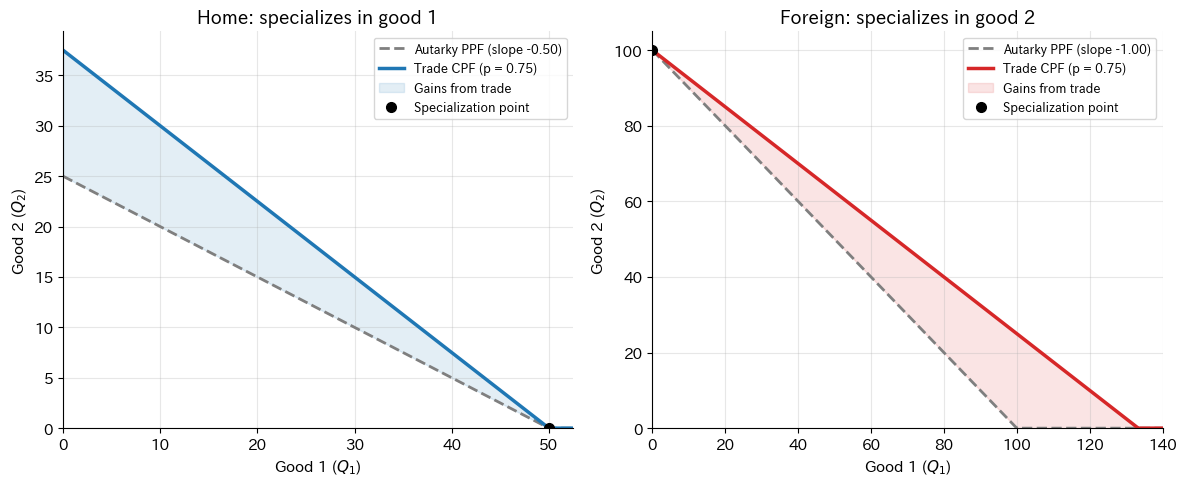

In [9]:
# --- パラメータ（会話で Gemini さんが用いた値） ---
L, a1, a2 = 100.0, 2.0, 4.0              # 自国: 両財で絶対劣位
Ls, a1s, a2s = 100.0, 1.0, 1.0           # 外国: 両財で絶対優位
p_world = 0.75                            # 0.5 < p < 1.0

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (LL, b1, b2, name, spec) in zip(axes, [(L, a1, a2, 'Home', 1), (Ls, a1s, a2s, 'Foreign', 2)]):
    Q1max, Q2max = LL / b1, LL / b2
    q1 = np.linspace(0, max(Q1max, LL / b2 / p_world) * 1.05, 300)
    ppf = np.clip((LL - b1 * q1) / b2, 0, None)
    if spec == 1:   # 財1に特化して交換: p q1 + q2 = p Q1max
        income = p_world * Q1max
    else:           # 財2に特化して交換: p q1 + q2 = Q2max
        income = Q2max
    cpf = np.clip(income - p_world * q1, 0, None)
    ax.plot(q1, ppf, '--', color=C['gray'], lw=2, label=f'Autarky PPF (slope -{b1/b2:.2f})')
    ax.plot(q1, cpf, '-', color=C['home'] if spec == 1 else C['foreign'], lw=2.5,
            label=f'Trade CPF (p = {p_world})')
    ax.fill_between(q1, ppf, cpf, where=cpf >= ppf, alpha=0.12,
                    color=C['home'] if spec == 1 else C['foreign'], label='Gains from trade')
    ax.plot(*((Q1max, 0) if spec == 1 else (0, Q2max)), 'ko', ms=7, label='Specialization point')
    ax.set_xlim(0, q1[-1]); ax.set_ylim(0, None)
    ax.set_xlabel('Good 1 ($Q_1$)'); ax.set_ylabel('Good 2 ($Q_2$)')
    ax.set_title(f'{name}: specializes in good {spec}')
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

自国（左）は両財で外国より生産性が低いのに、財1に特化して $p=0.75$ で交換すれば、自給自足の PPF（傾き $-0.5$）より外側の CPF（傾き $-0.75$）上で消費できます。外国（右）も同様に、財2に特化すれば得をします。**どちらの国も、自給自足の集合を CPF の内側に含む** ― これが第4章で `gains_from_trade_spec1/2` として証明した集合の包含です。

## 5.2 世界均衡を解く

国際価格 $p$ は与えられたものではなく、相対供給 $RS$ と相対需要 $RD$ の交点で決まります（3.4 節）。コブ＝ダグラス型の需要（財1への支出割合 $\beta$）のもとで均衡を求める関数を書きます。

In [10]:
def ricardo_equilibrium(a1, a2, a1s, a2s, L, Ls, beta=0.5):
    """2国2財リカード・モデルの貿易均衡（自国が財1に比較優位、a1/a2 < a1s/a2s を仮定）。
    返り値: dict(p, 生産, 消費, 効用(自給/貿易))。財2が価値尺度。"""
    assert a1 / a2 < a1s / a2s, '自国が財1に比較優位をもつように並べてください'
    lo, hi = a1 / a2, a1s / a2s
    p_full = beta / (1 - beta) * (Ls / a2s) / (L / a1)      # 両国完全特化のときの価格
    if lo < p_full < hi:
        p, case = p_full, 'both specialized'
        Q = dict(Q1=L / a1, Q2=0.0, Q1s=0.0, Q2s=Ls / a2s)
    elif p_full <= lo:              # 自国が大きすぎる → 自国が不完全特化
        p, case = lo, 'home incompletely specialized'
        Q2s = Ls / a2s
        # 世界の財1需要 = beta * 世界所得 / p, 世界所得 = p*Q1 + Q2 + Q2s(財2建て)
        # 自国は L = a1 Q1 + a2 Q2 を満たしつつ財1を供給
        # 世界所得 Y = p*L/a1 + Q2s (自国では p/a1 = 1/a2 なので所得は L/a2 = p L / a1)
        Y = p * L / a1 + Q2s
        Q1 = beta * Y / p
        Q2 = (L - a1 * Q1) / a2
        Q = dict(Q1=Q1, Q2=Q2, Q1s=0.0, Q2s=Q2s)
    else:                           # 外国が大きすぎる → 外国が不完全特化
        p, case = hi, 'foreign incompletely specialized'
        Q1 = L / a1
        Y = p * Q1 + Ls / a2s
        Q2 = 0.0
        Q1s_tot = beta * Y / p
        Q1s = Q1s_tot - Q1
        Q2s = (Ls - a1s * Q1s) / a2s
        Q = dict(Q1=Q1, Q2=Q2, Q1s=Q1s, Q2s=Q2s)
    # 所得（財2建て）と消費
    Y_home = p * Q['Q1'] + Q['Q2']
    Y_for = p * Q['Q1s'] + Q['Q2s']
    cons = dict(c1=beta * Y_home / p, c2=(1 - beta) * Y_home,
                c1s=beta * Y_for / p, c2s=(1 - beta) * Y_for)
    U = lambda c1, c2: c1 ** beta * c2 ** (1 - beta)
    # 自給自足の効用（所得を支出割合どおりに配分）
    U_aut = U(beta * L / a1, (1 - beta) * L / a2)
    U_aut_s = U(beta * Ls / a1s, (1 - beta) * Ls / a2s)
    return dict(p=p, case=case, **Q, **cons,
                U_aut=U_aut, U_trade=U(cons['c1'], cons['c2']),
                U_aut_s=U_aut_s, U_trade_s=U(cons['c1s'], cons['c2s']))

eq = ricardo_equilibrium(a1, a2, a1s, a2s, L, Ls)
for k, v in eq.items():
    print(f'{k:>10}: {v:.4f}' if isinstance(v, float) else f'{k:>10}: {v}')
print(f"\n自国の効用の増加率 {eq['U_trade']/eq['U_aut']-1:+.1%}, 外国 {eq['U_trade_s']/eq['U_aut_s']-1:+.1%}")

         p: 1.0000
      case: foreign incompletely specialized
        Q1: 50.0000
        Q2: 0.0000
       Q1s: 25.0000
       Q2s: 75.0000
        c1: 25.0000
        c2: 25.0000
       c1s: 50.0000
       c2s: 50.0000
     U_aut: 17.6777
   U_trade: 25.0000
   U_aut_s: 50.0000
 U_trade_s: 50.0000

自国の効用の増加率 +41.4%, 外国 +0.0%


注意：5.1 節では国際価格を $p = 0.75$ と「仮に」置きましたが、需要まで含めて均衡を解くと、このパラメータでは $p = 1.0$ になります。外国の生産能力が大きいため、外国は財2に特化しきらず、両財を作り続けるのです（**外国が不完全特化**）。このとき国際価格は外国の自給価格に一致し、外国は貿易から何も得ず、利益はすべて自国に行きます。

国の大きさ（労働量の比 $L/L^{\ast}$）を変えると、均衡の型と、利益の配分がどう変わるかを見てみます。

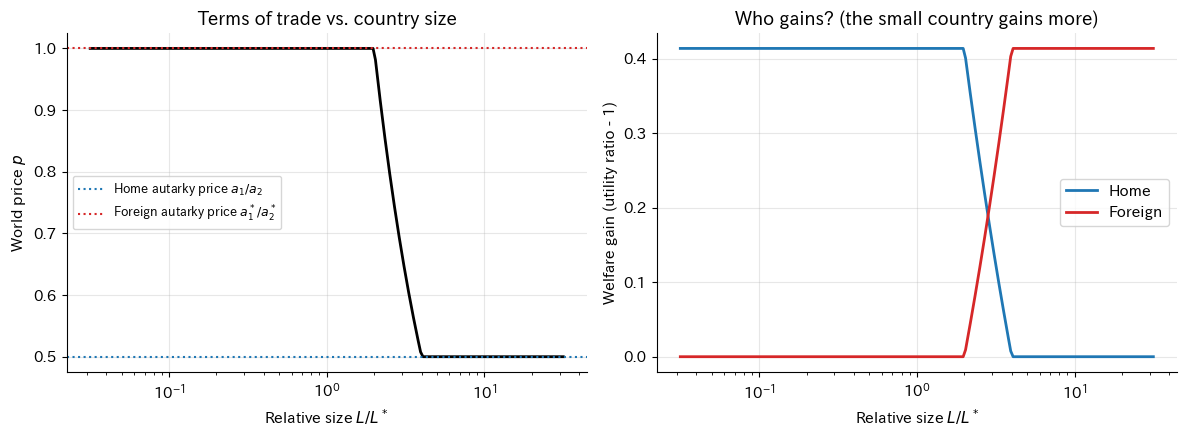

In [11]:
ratios = np.logspace(-1.5, 1.5, 200)
res = [ricardo_equilibrium(a1, a2, a1s, a2s, 100 * r, 100) for r in ratios]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogx(ratios, [r['p'] for r in res], color='k', lw=2)
axes[0].axhline(a1 / a2, ls=':', color=C['home'], label='Home autarky price $a_1/a_2$')
axes[0].axhline(a1s / a2s, ls=':', color=C['foreign'], label='Foreign autarky price $a_1^*/a_2^*$')
axes[0].set_xlabel('Relative size $L/L^*$'); axes[0].set_ylabel('World price $p$')
axes[0].set_title('Terms of trade vs. country size'); axes[0].legend(fontsize=9)
axes[1].semilogx(ratios, [r['U_trade'] / r['U_aut'] - 1 for r in res], color=C['home'], lw=2, label='Home')
axes[1].semilogx(ratios, [r['U_trade_s'] / r['U_aut_s'] - 1 for r in res], color=C['foreign'], lw=2, label='Foreign')
axes[1].set_xlabel('Relative size $L/L^*$'); axes[1].set_ylabel('Welfare gain (utility ratio - 1)')
axes[1].set_title('Who gains? (the small country gains more)'); axes[1].legend()
plt.tight_layout(); plt.show()

* 自国が小さいとき（左端）、国際価格は外国の自給価格 $a_1^{\ast}/a_2^{\ast}=1$ に張り付き、利益の大半は自国に行きます。
* 自国が大きいとき（右端）、価格は自国の自給価格 $0.5$ に張り付き、自国の利益はゼロ、利益はすべて外国に行きます。

**貿易の利益はつねに非負ですが、その配分は交易条件しだいです。** これは 3.6 節で見た「浮いた労働の配分」と同じ構造です。

## 5.3 リカードの数値で「浮いた労働」を描く

3.6 節の $S_E(\tau)$, $S_P(\tau)$ を図にします。

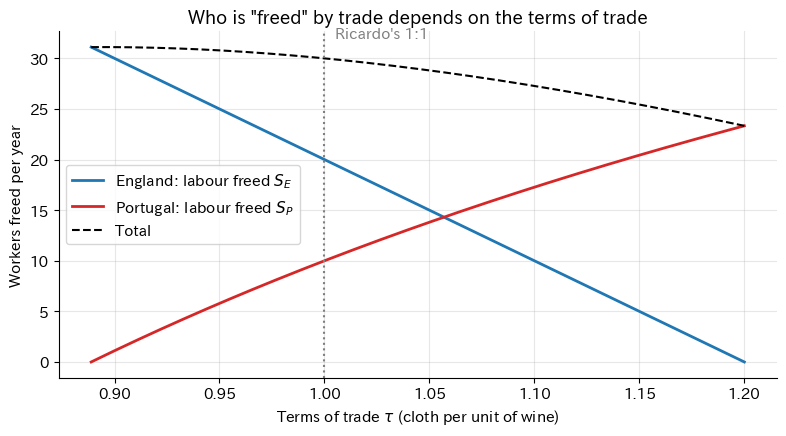

In [12]:
tau = np.linspace(8/9, 6/5, 200)
S_E = 120 - 100 * tau
S_P = 90 - 80 / tau
plt.figure(figsize=(8, 4.5))
plt.plot(tau, S_E, color=C['home'], lw=2, label='England: labour freed $S_E$')
plt.plot(tau, S_P, color=C['foreign'], lw=2, label='Portugal: labour freed $S_P$')
plt.plot(tau, S_E + S_P, color='k', lw=1.5, ls='--', label='Total')
plt.axvline(1.0, color=C['gray'], ls=':'); plt.text(1.005, 32, "Ricardo's 1:1", color=C['gray'])
plt.xlabel(r'Terms of trade $\tau$ (cloth per unit of wine)'); plt.ylabel('Workers freed per year')
plt.title('Who is "freed" by trade depends on the terms of trade')
plt.legend(); plt.tight_layout(); plt.show()

両財に絶対優位をもつポルトガルの労働が多く浮くのは、交易条件がイングランドの自給価格に近い（ポルトガルに有利な）ときだけです。

## 5.4 2011年版ウィキペディアの数値例の検算

In [13]:
# 1人あたり産出量（ワイン, 毛織物）
prod = {'Big': (10, 5), 'Small': (9, 3)}
before = {'Big': (100, 100), 'Small': (100, 100)}     # (ワイン, 毛織物) の従事者
after = {'Big': (20, 180), 'Small': (200, 0)}
for label, alloc in [('before', before), ('after', after)]:
    W = sum(prod[c][0] * alloc[c][0] for c in prod)
    Cl = sum(prod[c][1] * alloc[c][1] for c in prod)
    print(f'{label:>6}: world wine = {W}, world cloth = {Cl}')
# 記事の交換例: 小国→大国 ワイン850, 大国→小国 毛織物350
big = (10 * 20 + 850, 5 * 180 - 350)
small = (9 * 200 - 850, 0 + 350)
print('consumption Big (wine, cloth) =', big, ' before =', (1000, 500))
print('consumption Small (wine, cloth) =', small, ' before =', (900, 300))
print('implied terms of trade: 1 cloth =', 850 / 350, 'wine (between 2 and 3)')

before: world wine = 1900, world cloth = 800
 after: world wine = 2000, world cloth = 900
consumption Big (wine, cloth) = (1050, 550)  before = (1000, 500)
consumption Small (wine, cloth) = (950, 350)  before = (900, 300)
implied terms of trade: 1 cloth = 2.4285714285714284 wine (between 2 and 3)


記事の数値は正しく、両国とも両財の消費がちょうど 50 ずつ増えます（交易条件 2.43 は両国の機会費用 2 と 3 のあいだ）。ただし、どの交換比率と交換量を選ぶかは記事の側で「適切に再分配すれば」と決めたものであり、市場がそれを実現する保証はモデルの外にあります。そして、ここまでは**完全雇用のモデル**です。

---
# 6. 多数財への拡張 ― ドーンブッシュ＝フィッシャー＝サミュエルソン・モデル

2財では「どちらに特化するか」しか問題になりませんが、現実には無数の財があります。ドーンブッシュ、フィッシャー、サミュエルソン（Dornbusch, Fischer & Samuelson 1977, 以下 DFS）は、財を区間 $[0,1]$ 上の連続体として扱うことで、リカード・モデルを多数財に拡張しました。このモデルは第13章で「通貨高（賃金比の上昇）」を扱うときの土台にもなります。

## 6.1 モデル

* 財 $z \in [0,1]$。自国・外国の労働投入係数 $a(z)$, $a^{\ast}(z)$。
* 財を、自国の相対的な生産性 $A(z) = a^{\ast}(z)/a(z)$ が**減少する順**に並べる（$A'(z) < 0$）。これを**比較優位の連鎖**（chain of comparative advantage）と呼ぶ。
* 自国・外国の賃金 $w, w^{\ast}$ と、その比である相対賃金 $\omega = w/w^{\ast}$。

自国が財 $z$ を作るのは $w\,a(z) \le w^{\ast} a^{\ast}(z)$、すなわち $A(z) \ge \omega$ のとき。したがって境界の財 $\bar z$ は
$$
A(\bar z) = \omega
$$
で決まり、自国は $[0, \bar z]$、外国は $(\bar z, 1]$ を作ります。

需要は両国共通のコブ＝ダグラス型（3.4 節）で、財 $z$ への支出割合を密度 $b(z)$（$\int_0^1 b = 1$）、財 $0$ から $\bar z$ までへの支出割合の合計（累積）を $\theta(\bar z) = \int_0^{\bar z} b(z)\,dz$ とします。世界所得 $wL + w^{\ast}L^{\ast}$ のうち $\theta(\bar z)$ が自国の財に支出され、それが自国の労働所得に等しいので（貿易収支の均衡）、
$$
wL = \theta(\bar z)\,(wL + w^{\ast}L^{\ast})
\quad\Longleftrightarrow\quad
\omega = \frac{\theta(\bar z)}{1-\theta(\bar z)}\cdot\frac{L^{\ast}}{L} \equiv B(\bar z;\, L^{\ast}/L).
$$
$B$ は $\bar z$ について増加関数です。**均衡は減少関数 $A$ と増加関数 $B$ の交点**として一意に決まります。

L*/L = 0.5:  z̄ = 0.743,  ω = w/w* = 1.447
L*/L = 1.0:  z̄ = 0.654,  ω = w/w* = 1.890
L*/L = 2.0:  z̄ = 0.558,  ω = w/w* = 2.523


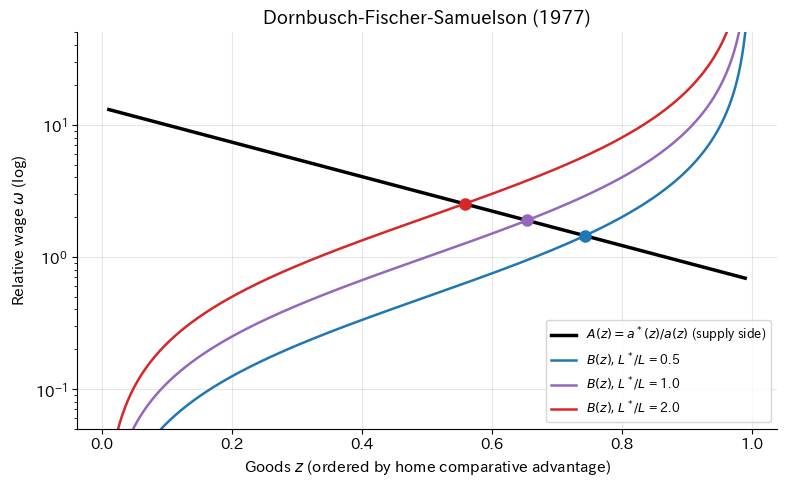

In [14]:
def dfs_equilibrium(A, theta, Lratio):
    """DFS モデルの均衡 (z̄, ω)。A: 相対生産性 (減少関数), theta: 支出の累積割合, Lratio = L*/L"""
    f = lambda z: A(z) - theta(z) / (1 - theta(z)) * Lratio
    zbar = brentq(f, 1e-9, 1 - 1e-9)
    return zbar, A(zbar)

A0, kappa = 3.0, 3.0
A_fun = lambda z: A0 * np.exp(-kappa * (z - 0.5))   # 比較優位の連鎖
theta_u = lambda z: z                               # b(z) = 1（一様な支出割合）

z = np.linspace(0.01, 0.99, 400)
plt.figure(figsize=(8, 5))
plt.semilogy(z, A_fun(z), color='k', lw=2.5, label='$A(z) = a^*(z)/a(z)$ (supply side)')
for Lr, col in [(0.5, C['home']), (1.0, C['purple']), (2.0, C['foreign'])]:
    plt.semilogy(z, theta_u(z) / (1 - theta_u(z)) * Lr, color=col, lw=1.8, label=f'$B(z)$, $L^*/L$ = {Lr}')
    zb, om = dfs_equilibrium(A_fun, theta_u, Lr)
    plt.plot(zb, om, 'o', color=col, ms=8)
    print(f'L*/L = {Lr}:  z̄ = {zb:.3f},  ω = w/w* = {om:.3f}')
plt.xlabel('Goods $z$ (ordered by home comparative advantage)'); plt.ylabel(r'Relative wage $\omega$ (log)')
plt.title('Dornbusch-Fischer-Samuelson (1977)')
plt.ylim(0.05, 50); plt.legend(fontsize=9); plt.tight_layout(); plt.show()

外国の労働力が相対的に大きくなる（$L^{\ast}/L$ が増える）と、$B$ 曲線が上に移り、自国の相対賃金 $\omega$ が上がり、自国が作る財の範囲 $\bar z$ は**狭まります**。外国の需要が相対的に大きくなって自国の財が求められ、自国の賃金が上がる結果、比較優位の連鎖の「端のほう」の財では自国が競争力を失うからです。賃金（＝通貨で測った労働の価格）が上がると、作れる財の範囲が縮む ― この仕組みは第13章で「通貨高」を考えるときに再び登場します。

## 6.2 比較静学を SymPy で

境界条件 $A(\bar z) = B(\bar z; \lambda)$（$\lambda = L^{\ast}/L$）を陰関数として微分すると、
$$
\frac{d\bar z}{d\lambda} = \frac{B_{\lambda}}{A'(\bar z) - B_{z}}
$$
です。$A' < 0$、$B_z > 0$、$B_\lambda > 0$ という符号条件だけから結論の符号が決まるかどうか、SymPy で確かめます。

In [15]:
zb, lam = sp.symbols('zbar lambda', positive=True)
Afun = sp.Function('A')
th = sp.Function('theta')
B = th(zb) / (1 - th(zb)) * lam
F = Afun(zb) - B                     # F(zbar, lambda) = 0
dz_dlam = sp.simplify(-sp.diff(F, lam) / sp.diff(F, zb))
print('dz̄/dλ =', dz_dlam)
# 符号の確認: A' < 0, θ' > 0, 0 < θ < 1 を代入
Ap, thp, thv = sp.symbols("A_p theta_p theta_v")
expr = dz_dlam.subs({sp.Derivative(Afun(zb), zb): Ap, sp.Derivative(th(zb), zb): thp, th(zb): thv})
print('記号で:', sp.simplify(expr))
print('数値例 (A\'=-1, θ\'=1, θ=0.5, λ=1):', expr.subs({Ap: -1, thp: 1, thv: sp.Rational(1, 2), lam: 1}))

dz̄/dλ = (1 - theta(zbar))*theta(zbar)/(-lambda*Derivative(theta(zbar), zbar) + theta(zbar)**2*Derivative(A(zbar), zbar) - 2*theta(zbar)*Derivative(A(zbar), zbar) + Derivative(A(zbar), zbar))


記号で: theta_v*(1 - theta_v)/(A_p*theta_v**2 - 2*A_p*theta_v + A_p - lambda*theta_p)
数値例 (A'=-1, θ'=1, θ=0.5, λ=1): -1/5


分子は $\theta/(1-\theta) > 0$、分母は $A' - B_z < 0$ なので、$d\bar z/d\lambda < 0$ となり、図の結果（外国が大きくなると自国の範囲が狭まる）と一致します。このような「関数の具体形を決めず、符号だけから推論する」方法が第7章のテーマです。

## 6.3 3国3財以上 ― ジョーンズの基準

3国以上になると、二国ずつの比較では特化パターンが決まりません。ジョーンズ（Jones 1961）は、完全特化のパターン（国から財への一対一の割り当て $\sigma$）のうち、労働投入係数の積 $\prod_c a_{\sigma(c),c}$ を最小にするものを選べばよい、という基準を示しました。現在のウィキペディアにも引かれている数値例で確かめます。

In [16]:
from itertools import permutations
countries = ['A (US)', 'B (UK)', 'C (Europe)']
goods = ['1 wheat', '2 linen', '3 cloth']
a = np.array([[10, 10, 10],    # 行: 財, 列: 国
              [5, 7, 3],
              [4, 3, 2]])
rows = []
for perm in permutations(range(3)):      # perm[c] = 国 c が作る財
    prodval = np.prod([a[perm[c], c] for c in range(3)])
    rows.append((prodval, ', '.join(f'{countries[c][0]}→{perm[c]+1}' for c in range(3))))
for v, s in sorted(rows):
    print(f'{s}:  product = {v}')

A→1, B→3, C→2:  product = 90
A→2, B→1, C→3:  product = 100
A→3, B→1, C→2:  product = 120
A→1, B→2, C→3:  product = 140
A→2, B→3, C→1:  product = 150
A→3, B→2, C→1:  product = 280


積を最小にするのは A→1（小麦）、B→3（服地）、C→2（リネン）で、これがウィキペディアで「唯一実現可能な完全特化パターン」とされているものです。

さらに中間財が貿易される場合には、比較優位の概念そのものの定義が難しくなることが知られています（McKenzie 1956; Deardorff 2005）。塩沢由典（Shiozawa 2007; 塩沢 2014）は、中間財貿易と技術選択を含む多数国多数財の場合に、古典派的な国際価値論を再構成しました。本ノートの第9章は、その最も単純な形 ― **資本財（中間財）を一つだけ入れる** ― から始めます。

---
# 7. 比較静学の道具立て ― SymPy・Lean・SMT ソルバ（IS-LM を例に）

会話は、JRF の次の問いから始まりました。

> IS-LM 分析のようなもの、そりゃあ、Python によるシミュレーションももちろんできると思います。でも、そうじゃなくて、式のまま…結構、曖昧な式ですよね…これをそのまま分析したいというとき、どういうツールが使えるのでしょう？ Lean とか？

経済学では、関数の具体形を決めずに、導関数の**符号条件**（たとえば限界消費性向 $0 < C' < 1$、投資の利子感応度 $I' < 0$）だけから、外生変数の変化が内生変数をどちらに動かすかを推論する方法を**比較静学**（comparative statics）と呼びます。サミュエルソン『経済分析の基礎』（Samuelson 1947）が体系化し、ランカスター（Lancaster 1962）やバセット＝メイビー＝クワーク（Bassett, Maybee & Quirk 1968）が「符号だけで答えが決まるのはいつか」という**定性経済学**（qualitative economics）として発展させました。

この章では、本ノート後半で資本財入りのリカード・モデルを分析するための道具として、四つのアプローチを IS-LM モデル（Hicks 1937）で練習します。

| 道具 | 得意なこと | この章での使い方 |
|---|---|---|
| 数式処理（SymPy, Mathematica） | 全微分・連立方程式を記号のまま解き、乗数の式を得る | 乗数 $dY/dG$ を導出 |
| 定理証明支援系（Lean 4, Coq, Isabelle） | 符号条件から結論が**必ず**出ることを証明する | $dY/dG > 0$ を証明 |
| SMT ソルバ（Z3, dReal） | 条件を満たす**反例**を自動で探す | 条件を緩めたときの反例探し |
| 符号可解性（定性経済学） | 行列の符号パターンだけで解の符号が決まるか判定 | 乱数による簡易判定 |

## 7.1 IS-LM モデルとは

IS-LM モデルは、ケインズ『一般理論』（Keynes 1936）の考え方を、ヒックス（Hicks 1937）が二本の式にまとめたもので、マクロ経済学の入門教科書に必ず出てくる短期（物価を一定とみなせる期間）の国民所得決定のモデルです。

* **IS 曲線**（Investment = Saving）：**財市場**の均衡。国民所得 $Y$（GDP）は、消費 $C$、投資 $I$、政府支出 $G$ の合計に等しい。消費は所得とともに増え（所得が 1 増えると消費は $C_Y$ だけ増える。$0<C_Y<1$ を**限界消費性向**という）、投資は利子率 $r$ が上がると減る（借りて投資するのが割高になる）。したがって、利子率が高いほど均衡所得は低い ― $(Y, r)$ 平面で右下がりの曲線になる。
* **LM 曲線**（Liquidity preference = Money supply）：**貨幣市場**の均衡。中央銀行が決める貨幣供給 $M$ と、人々が手元に持ちたい貨幣の量（貨幣需要）$L(Y, r)$ が等しい。取引が増える（$Y$ が大きい）ほど貨幣需要は増え、利子率が高いほど（債券を持つほうが得なので）減る。所得が高いほど貨幣市場を均衡させる利子率は高い ― 右上がりの曲線になる。
* 二本の曲線の交点で、所得 $Y$ と利子率 $r$ が同時に決まる。財政政策（$G$ を増やす）は IS 曲線を右へ、金融緩和（$M$ を増やす）は LM 曲線を右へ動かす。それぞれ $Y$ と $r$ がどちらに動くかを問うのが、IS-LM の比較静学です。

物価の変化や期待の役割を扱えないなどの限界から、現代の研究ではより精緻なモデルが使われますが、「関数の具体形を決めずに、符号条件だけで政策の効果を論じる」練習台としては最適です。なお、ここでの $r$ は**利子率**で、第9章の**利潤率** $r$ とは別の変数です（古典派の世界では両者はほぼ同じものと考えられていました）。

式で書くと：

* IS 曲線：$Y = C(Y) + I(r) + G$
* LM 曲線：$M = L(Y, r)$

偏導関数を $C_Y = dC/dY$, $I_r = dI/dr$, $L_Y = \partial L/\partial Y$, $L_r = \partial L/\partial r$ と書き、両式を全微分すると
$$
\begin{pmatrix} 1 - C_Y & -I_r \\ L_Y & L_r \end{pmatrix}
\begin{pmatrix} dY \\ dr \end{pmatrix}
=
\begin{pmatrix} dG \\ dM \end{pmatrix},
\qquad 0 < C_Y < 1,\; I_r < 0,\; L_Y > 0,\; L_r < 0 .
$$

## 7.2 SymPy による乗数の導出（会話で Gemini さんが示したコード）

In [17]:
# 1. 記号と変数の定義
dY, dr, dG, dM = sp.symbols('dY dr dG dM')

# 偏導関数の符号条件を属性として指定
C_Y = sp.Symbol("C_Y", positive=True)  # 限界消費性向 (0 < C_Y < 1)
I_r = sp.Symbol("I_r", negative=True)  # 投資の利子率感応度 (I_r < 0)
L_Y = sp.Symbol("L_Y", positive=True)  # 貨幣需要の所得感応度 (L_Y > 0)
L_r = sp.Symbol("L_r", negative=True)  # 貨幣需要の利子率感応度 (L_r < 0)

# 2. 全微分方程式系の構築
eq1 = sp.Eq((1 - C_Y) * dY - I_r * dr, dG)
eq2 = sp.Eq(L_Y * dY + L_r * dr, dM)

# 3. 政府支出 G の変化に対する比較静学 (dM = 0)
sol_G = sp.solve([eq1.subs(dM, 0), eq2.subs(dM, 0)], (dY, dr))
dY_dG = sp.simplify(sol_G[dY] / dG)
dr_dG = sp.simplify(sol_G[dr] / dG)
print("dY/dG =", dY_dG)
print("dr/dG =", dr_dG)

# 4. ヤコビアン行列式 D
D = (1 - C_Y) * L_r + I_r * L_Y
print("ヤコビアン行列式 D =", D)

dY/dG = L_r/(-C_Y*L_r + I_r*L_Y + L_r)
dr/dG = L_Y/(C_Y*L_r - I_r*L_Y - L_r)
ヤコビアン行列式 D = I_r*L_Y + L_r*(1 - C_Y)


SymPy は記号に `positive=True` などの属性を付けられますが、$C_Y < 1$ のような**上限**は属性では表せません。そこで $C_Y = 1 - s$（$s$ は限界貯蓄性向、正）と置き換えると、SymPy 自身に符号を判定させることができます。

In [18]:
s_ = sp.Symbol('s', positive=True)      # 限界貯蓄性向 s = 1 - C_Y > 0
D_s = D.subs(C_Y, 1 - s_)
print('D =', D_s, '  → D は負か?', D_s.is_negative)
print('dY/dG =', sp.simplify(dY_dG.subs(C_Y, 1 - s_)), '  → 正か?', sp.simplify(dY_dG.subs(C_Y, 1 - s_)).is_positive)
print('dr/dG =', sp.simplify(dr_dG.subs(C_Y, 1 - s_)), '  → 正か?', sp.simplify(dr_dG.subs(C_Y, 1 - s_)).is_positive)

D = I_r*L_Y + L_r*s   → D は負か? True
dY/dG = L_r/(I_r*L_Y + L_r*s)   → 正か? True
dr/dG = -L_Y/(I_r*L_Y + L_r*s)   → 正か? True


## 7.3 Lean による証明

SymPy の `is_negative` は便利ですが、「なぜそう言えるのか」を示してはくれず、判定できないときは `None` を返すだけです。Lean では、符号条件を構造体の**仮定**として持たせ、結論を**定理**として証明します。以下は会話で Gemini さんが示したコードに、利子率の反応 $dr/dG > 0$ と、解が実際に方程式を満たすことの検算を加えたものです。

（細かい点：Gemini さんのコードでは `def dY_dG` となっていましたが、実数の割り算は計算可能でないため Lean 4 では `noncomputable def` と書く必要があります。）

In [19]:
%%writefile lean_src/ch07_islm.lean
/-! ## 第7章 比較静学の形式化（IS-LM モデルを例に） -/

/-- IS-LM 系の偏導関数とその符号条件を保持する構造体。 -/
structure ISLMSystem where
  C_Y : ℝ
  I_r : ℝ
  L_Y : ℝ
  L_r : ℝ
  hC1 : 0 < C_Y
  hC2 : C_Y < 1
  hI  : I_r < 0
  hLY : 0 < L_Y
  hLr : L_r < 0

namespace ISLMSystem

/-- ヤコビアン行列式 `D = (1 - C_Y) L_r + I_r L_Y`。 -/
def det (sys : ISLMSystem) : ℝ :=
  (1 - sys.C_Y) * sys.L_r + sys.I_r * sys.L_Y

/-- `D < 0`。 -/
theorem det_neg (sys : ISLMSystem) : sys.det < 0 := by
  dsimp [det]
  have h1 : 0 < 1 - sys.C_Y := sub_pos.mpr sys.hC2
  have term1_neg : (1 - sys.C_Y) * sys.L_r < 0 := mul_neg_of_pos_of_neg h1 sys.hLr
  have term2_neg : sys.I_r * sys.L_Y < 0 := mul_neg_of_neg_of_pos sys.hI sys.hLY
  linarith

/-- 政府支出乗数 `dY/dG = L_r / D`。 -/
noncomputable def dY_dG (sys : ISLMSystem) : ℝ := sys.L_r / sys.det

/-- 利子率の反応 `dr/dG = -L_Y / D`。 -/
noncomputable def dr_dG (sys : ISLMSystem) : ℝ := -sys.L_Y / sys.det

/-- 財政支出の増加は所得を増やす。 -/
theorem dY_dG_pos (sys : ISLMSystem) : 0 < sys.dY_dG := by
  dsimp [dY_dG]
  exact div_pos_of_neg_of_neg sys.hLr sys.det_neg

/-- 財政支出の増加は利子率を上げる（クラウディング・アウトの源）。 -/
theorem dr_dG_pos (sys : ISLMSystem) : 0 < sys.dr_dG := by
  dsimp [dr_dG]
  exact div_pos_of_neg_of_neg (neg_neg_of_pos sys.hLY) sys.det_neg

/-- 解が実際に全微分方程式系を満たすことの検算（`dG = 1, dM = 0`）。 -/
theorem solves (sys : ISLMSystem) :
    (1 - sys.C_Y) * sys.dY_dG - sys.I_r * sys.dr_dG = 1 ∧
    sys.L_Y * sys.dY_dG + sys.L_r * sys.dr_dG = 0 := by
  have hD : sys.det ≠ 0 := sys.det_neg.ne
  constructor
  · simp only [dY_dG, dr_dG]
    field_simp
    simp only [det]; ring
  · simp only [dY_dG, dr_dG]
    field_simp
    ring

end ISLMSystem

Overwriting lean_src/ch07_islm.lean


`det_neg` の証明は、手で行う推論とほぼ同じ形をしています：$1 - C_Y > 0$ と $L_r < 0$ から第1項が負、$I_r < 0$ と $L_Y > 0$ から第2項が負、だから和は負（`linarith`）。

Gemini さんが会話で述べたとおり、Lean の利点は「前提条件のモレを完全に炙り出せる」ことです。たとえば `hLr : L_r < 0` を `L_r ≤ 0` に弱めると、`div_pos_of_neg_of_neg` が使えなくなり、証明が通らなくなります。どこで通らなくなるかが、どの仮定がどこで効いているかを教えてくれます。

なお、本格的には、具体形のない関数 $C, I, L$ から出発し、Mathlib の陰関数定理を使って「均衡 $Y(G)$ が微分可能で、その導関数が上の式に等しい」ことから証明すべきところです。ここでは線形化された体系（ヤコビアンの成分を実数として与えたもの）から出発しています。この簡略化は、比較静学の教科書の大半が採っているものでもあります。

## 7.4 Z3 による反例探し

SMT ソルバは、「条件をすべて満たし、かつ結論が成り立たない」数値の割り当て（**反例**）を探します。見つからなければ（unsat）、結論は条件から必ず従います。

In [20]:
try:
    import z3
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'z3-solver'], check=True)
    import z3

def islm_counterexample(strict_Lr=True):
    cy, ir, ly, lr = z3.Reals('C_Y I_r L_Y L_r')
    s = z3.Solver()
    s.add(cy > 0, cy < 1, ir < 0, ly > 0)
    s.add(lr < 0 if strict_Lr else lr <= 0)
    det = (1 - cy) * lr + ir * ly
    s.add(det != 0)
    # 「dY/dG = L_r / det > 0」の否定: L_r / det <= 0  ⇔  L_r * det <= 0 (det ≠ 0 のとき)
    s.add(lr * det <= 0)
    r = s.check()
    return r, (s.model() if r == z3.sat else None)

print('L_r < 0  のとき:', islm_counterexample(True))
print('L_r <= 0 のとき:', islm_counterexample(False))

L_r < 0  のとき: (unsat, None)
L_r <= 0 のとき: (sat, [L_Y = 1, C_Y = 1/2, L_r = 0, I_r = -1])


$L_r < 0$ のときは反例がなく（unsat）、$L_r \le 0$ に弱めると $L_r = 0$ という反例が見つかります。$L_r = 0$ は貨幣需要が利子率に反応しない場合（LM 曲線が垂直）で、財政支出は利子率の上昇で投資を同額押しのけ（完全なクラウディング・アウト）、所得は増えません（$dY/dG = 0$）。古典派の場合として知られるこの「境界のケース」を、ソルバは機械的に見つけてくれます。

## 7.5 符号可解性 ― 符号だけで答えが決まるか

ヤコビアンの各成分の**符号**だけを見て、解の符号が一意に決まるかを問うのが符号可解性（sign solvability）です。IS-LM の場合、
$$
\operatorname{sgn} J = \begin{pmatrix} + & + \\ + & - \end{pmatrix},\qquad
\operatorname{sgn}\begin{pmatrix} dG \\ dM\end{pmatrix} = \begin{pmatrix} + \\ 0 \end{pmatrix}
$$
です（$-I_r > 0$ に注意）。厳密な判定にはグラフ理論的なアルゴリズムがありますが（Bassett, Maybee & Quirk 1968; Klee, Ladner & Manber 1984）、ここでは乱数で大きさを振って、符号が変わるかどうかを調べる簡易版を書きます。

In [21]:
def sign_check(sign_J, sign_b, trials=20000, seed=0):
    """符号行列 sign_J, 右辺の符号 sign_b に対し、大きさをランダムに振って解の符号の出現パターンを数える。"""
    rng = np.random.default_rng(seed)
    sign_J, sign_b = np.array(sign_J), np.array(sign_b)
    patterns = {}
    for _ in range(trials):
        J = sign_J * rng.lognormal(0, 1.5, sign_J.shape)
        b = sign_b * rng.lognormal(0, 1.5, sign_b.shape)
        if abs(np.linalg.det(J)) < 1e-12:
            continue
        x = np.linalg.solve(J, b)
        key = tuple(np.sign(np.round(x, 12)).astype(int))
        patterns[key] = patterns.get(key, 0) + 1
    return patterns

print('IS-LM, dG>0         :', sign_check([[1, 1], [1, -1]], [1, 0]))
print('IS-LM, dM>0         :', sign_check([[1, 1], [1, -1]], [0, 1]))
# 符号だけでは決まらない例: 対角が同符号で非対角が逆符号
print('sign-ambiguous example:', sign_check([[1, 1], [1, 1]], [1, 0]))

IS-LM, dG>0         : {(np.int64(1), np.int64(1)): 20000}


IS-LM, dM>0         : {(np.int64(1), np.int64(-1)): 20000}


sign-ambiguous example: {(np.int64(-1), np.int64(1)): 9977, (np.int64(1), np.int64(-1)): 10023}


IS-LM では、財政政策（$dG > 0$）でも金融政策（$dM > 0$）でも、解の符号パターンは一つだけ現れます（符号可解）。最後の例は行列式の符号が大きさしだいで変わるため、二つのパターンが現れます（符号だけでは決まらない）。

## 7.6 シミュレーションか、比較静学か

会話で JRF は「資本財の場合は別の結論が導かれることを比較静学的に導けないか、Python シミュレーションのほうが有望なのかな」と問い、Gemini さんは次のように整理しました。

* **分配（利潤率 $r$ や賃金 $w$）によって比較優位の順序が変わる**という構造そのものを論証したいなら、比較静学（SymPy / Lean）が向いている → **第9章**
* **資本財の輸入・蓄積によって生産性のフロンティアが時間とともにどう変わるか**という過程を描きたいなら、Python による数値シミュレーション（相図、分岐）が向いている → **第10〜12章**

本ノートでもこの整理に従います。ただし実際には両者は補い合います。シミュレーションで現象を見つけ、比較静学（と Lean）でその現象が**どの仮定から必然的に出てくるのか**を確定する、という往復が有効です。

---
# 8. 失業と利子生活者

会話の中で、JRF は「失業…リカード的議論では私はこれは利子生活者だとおもうのですが…が増えるとか増えないとかいう議論もあったはずです」と問いました。Gemini さんは最初『原理』第31章「機械について」の話をし、次に第19章「商業の流路の突然の変化について」とブレッカー（Brecher 1974）らの議論を紹介し、最後に、ヘクシャー＝オリーン理論とサプライサイド的な正当化論、そしてホブソンらの利子生活者批判へと話を進めました。

この章では、これらを整理し、「貿易論のなかの失業」には少なくとも四つの異なる意味があることを示します。

| | 失業の意味 | 典型的なモデル | 節 |
|---|---|---|---|
| (a) | 貿易で**浮いた労働**（利益そのもの） | リカード第7章、需要固定 | 8.1, 8.2 |
| (b) | **貨幣で測った絶対的な高さ**による雇用の喪失 | 賃金・為替が硬直的で需要が制約されたモデル | 8.2 |
| (c) | 産業間移動の**過渡的**な摩擦 | リカード第19章、調整費用 | 8.3 |
| (d) | 機械化・賃金下限による**構造的**失業 | リカード第31章、ブレッカー | 8.4, 8.5 |

## 8.1 「浮いた労働」は誰のものか

3.6 節で見たとおり、リカードの数値例では、貿易の利益は**消費を固定したときに浮く労働**として表されていました。もし消費が増えなければ（需要が飽和していれば）、浮いた労働を使う場所はありません。塩沢由典（Shiozawa 2007）は、中間財貿易を含む一般的なモデルで、**世界の最終需要が増大しない限り、貿易自由化は短期的に失業と廃業を生む**ことを指摘しています（現在の日本語版ウィキペディアもこの指摘を引いています）。

浮いた労働が失業として現れるとき、その失業者は何によって暮らすのでしょうか。浮いた労働の分だけ、国全体としては同じ消費を少ない労働で得ているのですから、**分配さえされれば**失業者も以前と同じだけ消費できます。そのときの失業者は、「働かずに、社会全体の生産性の果実の分け前を受け取る者」 ― 構造的には利子生活者と同じ立場 ― です。分配されなければ、彼らは本当に困窮し、浮いた労働の果実は雇用されている者か、資本・土地の所有者の手に残ります。

JRF が 2011 年に「二財モデルですべてが分配されたときのことを考える…労働してない者にも分配されるのが普通というわけだから、上記のような解釈になる」と書いたのは、このことでした。**モデルが暗黙に仮定している「すべてが分配される」世界では、失業者は利子生活者と区別がつかない**のです。

## 8.2 需要が固定され、賃金と為替が硬直的なとき

2011 年版のウィキペディアの主張（「両国とも 100 人が失業している状態で自由貿易を行えば、比較優位の大国は完全雇用を達成し、比較劣位の小国は全員に近い人数が失業してしまう。特に通貨が高い国に、失業が集中する」）を、モデルとして再現してみます。

**設定**

* 3.7 節の数値（1 人あたり産出：大国 ワイン 10・毛織物 5、小国 ワイン 9・毛織物 3）。各国 200 人。
* 貿易前は各国 100 人だけが働いている（ワイン 50 人・毛織物 50 人）。世界の需要は貿易前の生産量 ワイン 950・毛織物 400 で**固定**。
* 賃金は自国通貨建てで両国とも 1 に**固定**。為替レート $e$ ＝ 小国通貨 1 単位の大国通貨建て価格（$e$ が大きいほど小国の**通貨が高い**）。
* 買い手は貨幣で測って最も安い生産者から買う（世界全体の費用最小化）。

この配分は線形計画問題として解けます。

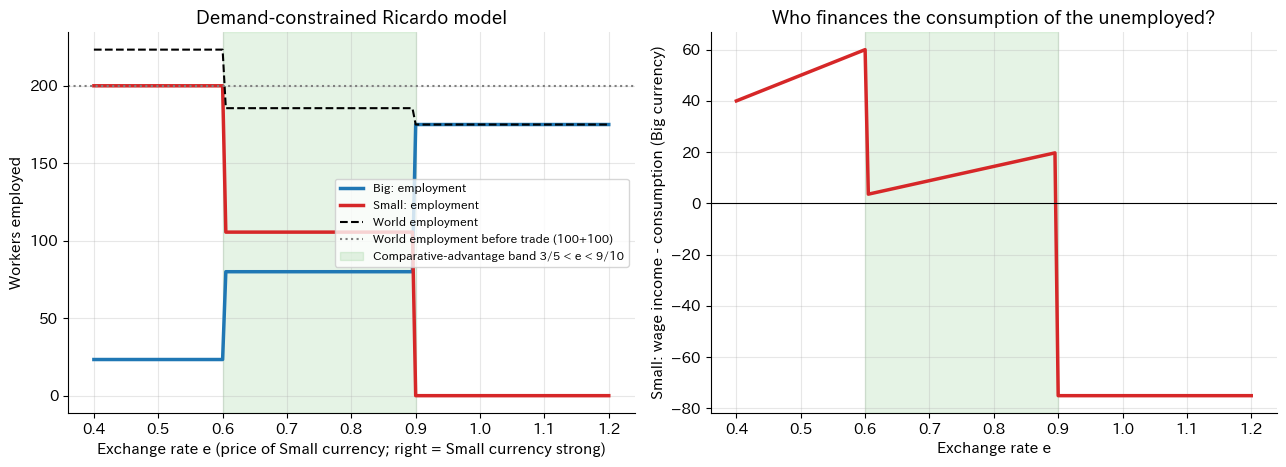

e = 0.50: Big wine    0.0, cloth   23.3 | Small wine  105.6, cloth   94.4 | employment Big   23.3, Small  200.0, world  223.3
e = 0.75: Big wine    0.0, cloth   80.0 | Small wine  105.6, cloth    0.0 | employment Big   80.0, Small  105.6, world  185.6
e = 1.00: Big wine   95.0, cloth   80.0 | Small wine    0.0, cloth    0.0 | employment Big  175.0, Small    0.0, world  175.0


In [22]:
prod = {'Big': (10, 5), 'Small': (9, 3)}     # 1人あたり産出 (ワイン, 毛織物)
CAP = 200                                    # 各国の労働力
DEMAND = (950, 400)                          # 世界需要（貿易前の生産量で固定）

def demand_constrained_allocation(e, wB=1.0, wS=1.0, demand=DEMAND):
    """費用最小の生産配分。変数は [大国ワイン, 大国毛織物, 小国ワイン, 小国毛織物] の従事者数。"""
    cost = [wB, wB, e * wS, e * wS]                        # 大国通貨建ての1人あたり費用
    A_ub = [[-10, 0, -9, 0], [0, -5, 0, -3], [1, 1, 0, 0], [0, 0, 1, 1]]
    b_ub = [-demand[0], -demand[1], CAP, CAP]
    r = linprog(cost, A_ub=A_ub, b_ub=b_ub, bounds=[(0, None)] * 4, method='highs')
    return r.x

es = np.linspace(0.4, 1.2, 161)
X = np.array([demand_constrained_allocation(e) for e in es])
empB, empS = X[:, 0] + X[:, 1], X[:, 2] + X[:, 3]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.plot(es, empB, color=C['home'], lw=2.5, label='Big: employment')
ax.plot(es, empS, color=C['foreign'], lw=2.5, label='Small: employment')
ax.plot(es, empB + empS, color='k', lw=1.5, ls='--', label='World employment')
ax.axhline(200, color=C['gray'], ls=':', label='World employment before trade (100+100)')
ax.axvspan(3/5, 9/10, color=C['third'], alpha=0.12, label='Comparative-advantage band 3/5 < e < 9/10')
ax.set_xlabel('Exchange rate e (price of Small currency; right = Small currency strong)')
ax.set_ylabel('Workers employed'); ax.set_title('Demand-constrained Ricardo model'); ax.legend(fontsize=8.5, loc='center right')
# 小国の貿易収支（大国通貨建て）: 輸出 - 輸入
def trade_balance_small(e, x):
    # 小国の生産額（小国の賃金所得）と、小国の消費（需要の半分と仮定）の差
    income = e * (x[2] + x[3])
    # 小国の消費 = 貿易前の小国の消費（ワイン 450, 毛織物 150）を世界の最安値で評価
    cw, cc = min(1 / 10, e / 9), min(1 / 5, e / 3)
    spend = 450 * cw + 150 * cc
    return income - spend
tbS = np.array([trade_balance_small(e, x) for e, x in zip(es, X)])
axes[1].plot(es, tbS, color=C['foreign'], lw=2.5)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].axvspan(3/5, 9/10, color=C['third'], alpha=0.12)
axes[1].set_xlabel('Exchange rate e'); axes[1].set_ylabel('Small: wage income - consumption (Big currency)')
axes[1].set_title('Who finances the consumption of the unemployed?')
plt.tight_layout(); plt.show()

for e in [0.5, 0.75, 1.0]:
    x = demand_constrained_allocation(e)
    print(f'e = {e:4.2f}: Big wine {x[0]:6.1f}, cloth {x[1]:6.1f} | Small wine {x[2]:6.1f}, cloth {x[3]:6.1f}'
          f' | employment Big {x[0]+x[1]:6.1f}, Small {x[2]+x[3]:6.1f}, world {x.sum():6.1f}')

結果を読みます（左図）。

1. **小国の通貨が高い**（$e > 9/10$）と、大国が両財とも貨幣で測って安くなり、全生産を引き受けます。大国 175 人雇用（ほぼ完全雇用）、小国 0 人。ウィキペディアの記述どおり「通貨の高い国に失業が集中」します。
2. **小国の通貨が安い**（$e < 3/5$）と逆に、小国が両財とも安くなり、小国は完全雇用、大国はごく一部しか雇用されません。
3. **中間の帯** $3/5 < e < 9/10$ でだけ、大国が毛織物、小国がワインを作るという**比較優位どおりの特化**が起きます。それでも世界の雇用は 185.6 人で、貿易前の 200 人より約 14 人少ない ― これが 8.1 節の「浮いた労働」です。

つまり、**どの財を作るか**は比較優位で決まるとしても、**どれだけ雇用されるか**は貨幣で測った絶対的な安さ（賃金と為替）と需要で決まります。比較優位が貿易パターンを決めるのは、為替レート（または賃金比）が帯の中に入るように調整される場合に限られます。この帯が空でないことと比較優位が同値であることを、Lean で証明しておきます（`exchange_band_iff`）。古典派の文献では、タウシッグ（Taussig 1927）が貨幣賃金と為替によるこの種の説明を詳しく展開しています。

右図は、小国の賃金所得から、小国の住民が貿易前と同じだけ消費するのに要する支出を引いたものです。小国の通貨が高いとき、小国の住民は（失業しているのに）安い輸入品で以前と同じだけ消費しようとすれば、その差額を**労働以外の所得**でまかなう必要があります。海外資産からの利子・配当、あるいは借金です。

ここに JRF の (M1) の読み替えがはっきり現れます。**通貨の高い国の失業者が以前と同じように暮らせているなら、その国は労働以外の所得（利子）で輸入をまかなっている。そうした国では通貨が高いのは当然で、その「失業者」は利子生活者の別名にすぎない。** 逆に、その所得がなければ、通貨高による失業は本物の困窮です。ウィキペディアの記述と JRF の読み替えは、どちらも同じモデルの異なる場合を言い当てていたのです。

In [23]:
%%writefile lean_src/ch08_unemployment.lean
/-! ## 第8章 失業と利子生活者 -/
namespace MoneyRicardo

/-- **比較優位 ＝ 為替レートの帯が空でないこと**。
  自国の賃金 `w`、外国の賃金 `ws`（外国通貨建て）、為替レート `e`（外国通貨 1 単位の自国通貨建て価格）のもとで、
  「財1は自国のほうが貨幣で測って安く、財2は外国のほうが安い」ような `e` が存在することは、
  自国が財1に比較優位をもつこと（`a1 * a2s < a1s * a2`）と同値。 -/
theorem exchange_band_iff (w ws a1 a2 a1s a2s : ℝ) (hw : 0 < w) (hws : 0 < ws)
    (h1 : 0 < a1) (_h2 : 0 < a2) (h1s : 0 < a1s) (h2s : 0 < a2s) :
    (∃ e : ℝ, 0 < e ∧ w * a1 < e * ws * a1s ∧ e * ws * a2s < w * a2) ↔ a1 * a2s < a1s * a2 := by
  constructor
  · rintro ⟨e, he, hA, hB⟩
    have hx : 0 < e * ws := mul_pos he hws
    -- 2つの不等式を掛け合わせて e * ws を消去する
    have hprod : (w * a1) * (e * ws * a2s) < (e * ws * a1s) * (w * a2) := by
      have p1 : 0 < w * a1 := mul_pos hw h1
      have p2 : 0 < e * ws * a2s := mul_pos hx h2s
      calc (w * a1) * (e * ws * a2s) < (e * ws * a1s) * (e * ws * a2s) :=
            mul_lt_mul_of_pos_right hA p2
        _ < (e * ws * a1s) * (w * a2) :=
            mul_lt_mul_of_pos_left hB (mul_pos hx h1s)
    have hwx : 0 < w * (e * ws) := mul_pos hw hx
    nlinarith [hprod, hwx]
  · intro hca
    -- e の下限 w a1 / (ws a1s) と上限 w a2 / (ws a2s) のあいだに e をとる
    have hlt : w * a1 / (ws * a1s) < w * a2 / (ws * a2s) := by
      rw [div_lt_div_iff₀ (mul_pos hws h1s) (mul_pos hws h2s)]
      have : 0 < w * ws := mul_pos hw hws
      nlinarith [mul_lt_mul_of_pos_left hca this]
    obtain ⟨e, he1, he2⟩ := exists_between hlt
    have he : 0 < e := lt_trans (div_pos (mul_pos hw h1) (mul_pos hws h1s)) he1
    refine ⟨e, he, ?_, ?_⟩
    · rw [div_lt_iff₀ (mul_pos hws h1s)] at he1; linarith
    · rw [lt_div_iff₀ (mul_pos hws h2s)] at he2; linarith

/-- 2011年版ウィキペディアの例（賃金は両国 1）: 小国の通貨の価格 `e` が 3/5 と 9/10 のあいだにあるときに限り、
  大国が毛織物、小国がワインを（貨幣で測って）安く作る。 -/
theorem wiki_band (e : ℝ) :
    ((1 : ℝ) * (1/5) < e * 1 * (1/3) ∧ e * 1 * (1/9) < (1 : ℝ) * (1/10)) ↔ (3/5 < e ∧ e < 9/10) := by
  constructor
  · rintro ⟨h1, h2⟩; constructor <;> linarith
  · rintro ⟨h1, h2⟩; constructor <;> linarith

end MoneyRicardo

namespace RicardoMachinery

/-- 『原理』第31章の数値例の検算: 流動資本（賃金基金）が 13000 から 5500 に減り、
  総生産物は 15000 から 7500 に減るが、純収入（利潤）2000 は変わらない。 -/
theorem machinery_example :
    let profit : ℝ := 2000
    let grossBefore : ℝ := 13000 + profit
    let grossAfter : ℝ := 5500 + profit
    grossBefore = 15000 ∧ grossAfter = 7500 ∧ grossBefore - 13000 = grossAfter - 5500 := by
  norm_num

end RicardoMachinery

Overwriting lean_src/ch08_unemployment.lean


## 8.3 過渡的な失業 ― 『原理』第19章

リカードは第19章「商業の流路の突然の変化について」（On Sudden Changes in the Channels of Trade）で、戦争から平和への移行や貿易の変化によって、ある産業に固定された資本と労働が無用になり、別の産業に移るまでに大きな困難と損失が生じることを論じています。固定資本（機械や建物）は別の用途に転用しにくく、その価値の多くが失われる、とも述べています。

これを最も簡単な形でモデル化します。

* 国全体の労働者は $L$ 人。貿易開始（$t=0$）で、比較劣位産業の労働者 $u_0$ 人が職を失う。時刻 $t$ の失業者数を $u(t)$ とする。
* 比較優位産業は、失業者を単位時間あたり割合 $\kappa$ で吸収する：$\dot u = -\kappa u$、よって $u(t) = u_0 e^{-\kappa t}$。
* 完全に再配置されれば、所得は自給自足より $g$（割合）高くなる。再配置の途中の所得は「雇用されている人数分」だけ。

将来の利益を現在の価値に換算する率（**割引率**）を $\rho$ とすると、貿易の利益の現在価値は
$$
\int_0^\infty e^{-\rho t}\Big[(1+g)\big(L - u(t)\big)\,y - L\,y\Big]dt
= \frac{g L y}{\rho} - \frac{(1+g)\,u_0\,y}{\rho + \kappa}
$$
（$y$ は 1 人あたり所得）。これが負になる、すなわち $\kappa < \rho\big[(1+g)u_0/(gL) - 1\big]$ なら、**貿易の利益は過渡的損失で打ち消されます**。

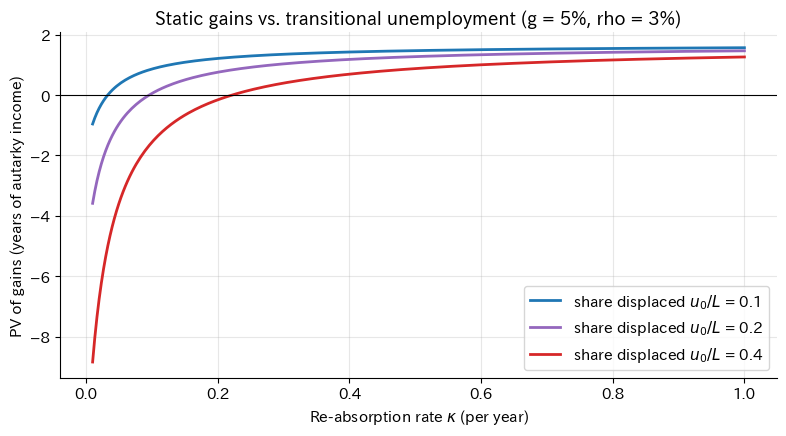

u0/L = 0.1:  gains are wiped out if kappa < 0.033 (mean duration > 30.3 years)
u0/L = 0.2:  gains are wiped out if kappa < 0.096 (mean duration > 10.4 years)
u0/L = 0.4:  gains are wiped out if kappa < 0.222 (mean duration > 4.5 years)


In [24]:
def transition_npv(g, u0_share, kappa, rho):
    """貿易開始の利益の現在価値（自給自足の年所得を 1 として）。"""
    return g / rho - (1 + g) * u0_share / (rho + kappa)

g, rho = 0.05, 0.03
kappas = np.linspace(0.01, 1.0, 300)
plt.figure(figsize=(8, 4.5))
for u0, col in [(0.1, C['home']), (0.2, C['purple']), (0.4, C['foreign'])]:
    plt.plot(kappas, [transition_npv(g, u0, k, rho) for k in kappas], color=col, lw=2,
             label=f'share displaced $u_0/L$ = {u0}')
plt.axhline(0, color='k', lw=0.8)
plt.xlabel(r'Re-absorption rate $\kappa$ (per year)'); plt.ylabel('PV of gains (years of autarky income)')
plt.title('Static gains vs. transitional unemployment (g = 5%, rho = 3%)')
plt.legend(); plt.tight_layout(); plt.show()
for u0 in [0.1, 0.2, 0.4]:
    k_star = rho * ((1 + g) * u0 / (g * 1.0) - 1)
    print(f'u0/L = {u0}:  gains are wiped out if kappa < {k_star:.3f} (mean duration > {1/k_star:.1f} years)' if k_star > 0 else f'u0/L = {u0}: always positive')

静的な貿易の利益（ここでは所得の 5%）は、再就職が遅い（平均失業期間が数年以上）と、簡単に過渡的損失で打ち消されます。実証研究でも、貿易ショックによる労働移動の調整には長い時間がかかり（Artuç, Chaudhuri & McLaren 2010）、中国からの輸入増が米国の地域労働市場に長期の雇用減をもたらした（Autor, Dorn & Hanson 2013 の「チャイナ・ショック」）ことが報告されています。

## 8.4 機械と失業 ― 『原理』第31章

第3版（1821年）でリカードは新たに第31章「機械について」を加え、「機械の導入は労働者階級の利益を害しない」という以前の自説を撤回しました。その数値例は次のとおりです（趣旨）。

* 資本家が 20,000 ポンドの資本をもち、7,000 を固定資本（建物・道具）、13,000 を流動資本（労働者の生活資料＝賃金基金）として使う。利潤率 10% で利潤は 2,000。毎年の**総生産物**は 15,000（賃金 13,000 ＋ 利潤 2,000）。
* ある年、労働者の半分を機械の製造に振り向ける。その年の生産物は機械 7,500 と生活資料 7,500。
* 翌年から、固定資本は 7,000 ＋ 機械 7,500 ＝ 14,500、流動資本（賃金基金）は 5,500 に減る。**総生産物は 7,500**（5,500 ＋ 2,000）に減るが、**純収入（利潤）2,000 は変わらない**。

In [25]:
rows = [('Before machine', 7000, 13000, 2000), ('After machine', 7000 + 7500, 5500, 2000)]
print(f"{'':16}{'fixed capital':>15}{'wage fund':>12}{'profit':>9}{'gross produce':>15}{'employment index':>18}")
for name, fixed, wage, profit in rows:
    print(f'{name:16}{fixed:>15,}{wage:>12,}{profit:>9,}{wage + profit:>15,}{wage / 13000:>18.2f}')

                  fixed capital   wage fund   profit  gross produce  employment index
Before machine            7,000      13,000    2,000         15,000              1.00
After machine            14,500       5,500    2,000          7,500              0.42


資本家の純収入は不変で、その純収入から地代・利子を受け取る人々の暮らしも変わりません。しかし賃金基金は 13,000 から 5,500 へと 58% 減り、それに比例して雇用が減ります。リカードは「純収入を増やす同じ原因が、同時に人口を過剰にし、労働者の状態を悪化させうる」と結論しました。後にマルクスはこれを「資本の有機的構成の高度化」と「相対的過剰人口（産業予備軍）」の理論として展開します。

第31章は貿易の章ではありませんが、**総生産（雇用）と純生産（不労所得の源泉）の分離**という論理は、貿易の議論にそのまま当てはまります。国の「豊かさ」を純収入で測る人にとっては、貿易や機械化で雇用が減っても豊かさは減らない。雇用で測る人にとっては、それは損失です。JRF の (M1) は、この二つの尺度のずれを指していると読めます。

## 8.5 賃金の下限と構造的失業 ― ブレッカー型モデル

ブレッカー（Brecher 1974a, b）は、ヘクシャー＝オリーン・モデルに最低（実質）賃金を入れ、自由貿易が失業を生み、厚生を下げうることを示しました（それ以前に Haberler 1950 も要素価格の硬直性と失業を論じています）。ここでは、リカード自身の世界に近い形 ― **工業（収穫一定）と農業（土地が固定され収穫逓減、地代が生じる）** ― で同じ論理を見ます。

* 労働者は全部で $L$ 人。工業の雇用を $L_M$、農業の雇用を $L_A$ とする（$L_M + L_A \le L$、残りは失業）。
* 工業：1 人あたり産出 $1/a_M$（$a_M$ は工業の労働投入係数）。工業品の価格を 1（世界価格）とする。
* 農業（穀物）：産出量は**生産関数** $F(L_A) = \bar A\,L_A^{\alpha}$。$\bar A$ は土地の広さ・肥沃度をまとめた定数、$0<\alpha<1$ は収穫逓減の度合い（雇用を 1% 増やすと産出は $\alpha$% 増える）。穀物の価格は $p$。$F'(L_A)$ は労働をもう 1 人増やしたときの産出の増分（**限界生産物**）。
* 賃金 $w$。地代 $R = pF(L_A) - wL_A$（農業の収入から賃金を引いた残り）は地主へ。
* 実質賃金の下限 $\bar w$（工業品建て）。$\bar w > 1/a_M$ なら工業は採算が合わず操業しない。農業の雇用は、限界生産物の価値が賃金に等しくなる $pF'(L_A) = \bar w$ で決まる。

穀物法の撤廃などで穀物の価格 $p$ が下がるとどうなるかを見ます。

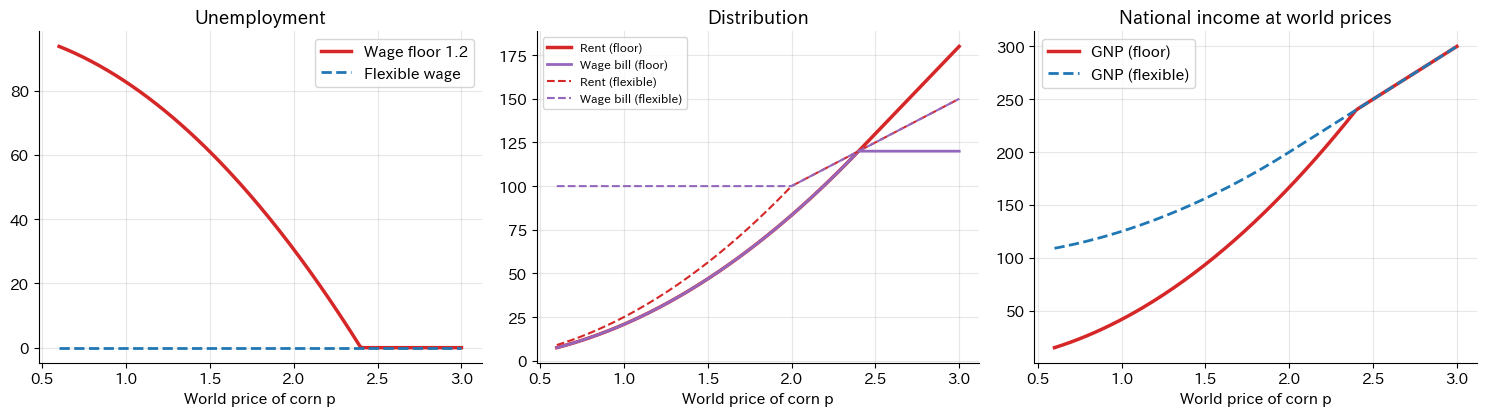

p = 2.4: floor → unemployed 0.0, GNP 240.0 | flexible → unemployed 0.0, GNP 240.0
p = 1.5: floor → unemployed 60.9, GNP 93.8 | flexible → unemployed 0.0, GNP 156.2


In [26]:
Abar, alpha, aM, Ltot = 10.0, 0.5, 1.0, 100.0

def brecher_economy(p, wbar=None):
    """賃金下限 wbar（None なら伸縮的）のもとでの雇用・所得。返り値: L_A, L_M, 失業, 地代, 賃金総額, GNP"""
    LA_of_w = lambda w: min(Ltot, (alpha * Abar * p / w) ** (1 / (1 - alpha)))
    if wbar is None:                     # 伸縮的賃金: 完全雇用
        w_full = alpha * Abar * p * Ltot ** (alpha - 1)   # 全員が農業にいるときの限界生産物
        w = max(1 / aM, w_full)          # 工業が操業できるなら賃金は 1/aM 以上
        LA = LA_of_w(w); LM = Ltot - LA
    else:
        w = wbar
        LA = LA_of_w(w)
        LM = (Ltot - LA) if 1 / aM >= wbar else 0.0
    U = Ltot - LA - LM
    Y_A = Abar * LA ** alpha
    rent = p * Y_A - w * LA
    return dict(LA=LA, LM=LM, U=U, rent=rent, wages=w * (LA + LM), GNP=p * Y_A + LM / aM)

ps = np.linspace(0.6, 3.0, 200)
flex = [brecher_economy(p) for p in ps]
rigid = [brecher_economy(p, wbar=1.2) for p in ps]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(ps, [r['U'] for r in rigid], color=C['foreign'], lw=2.5, label='Wage floor 1.2')
axes[0].plot(ps, [r['U'] for r in flex], color=C['home'], lw=2, ls='--', label='Flexible wage')
axes[0].set_title('Unemployment'); axes[0].set_xlabel('World price of corn p'); axes[0].legend()
axes[1].plot(ps, [r['rent'] for r in rigid], color=C['foreign'], lw=2.5, label='Rent (floor)')
axes[1].plot(ps, [r['wages'] for r in rigid], color=C['purple'], lw=2, label='Wage bill (floor)')
axes[1].plot(ps, [r['rent'] for r in flex], color=C['foreign'], lw=1.5, ls='--', label='Rent (flexible)')
axes[1].plot(ps, [r['wages'] for r in flex], color=C['purple'], lw=1.5, ls='--', label='Wage bill (flexible)')
axes[1].set_title('Distribution'); axes[1].set_xlabel('World price of corn p'); axes[1].legend(fontsize=8.5)
axes[2].plot(ps, [r['GNP'] for r in rigid], color=C['foreign'], lw=2.5, label='GNP (floor)')
axes[2].plot(ps, [r['GNP'] for r in flex], color=C['home'], lw=2, ls='--', label='GNP (flexible)')
axes[2].set_title('National income at world prices'); axes[2].set_xlabel('World price of corn p'); axes[2].legend()
plt.tight_layout(); plt.show()
for p in [2.4, 1.5]:
    r, f = brecher_economy(p, 1.2), brecher_economy(p)
    print(f"p = {p}: floor → unemployed {r['U']:.1f}, GNP {r['GNP']:.1f} | flexible → unemployed {f['U']:.1f}, GNP {f['GNP']:.1f}")

* 伸縮的な賃金のもとでは、穀物価格が下がると労働が工業へ移り、完全雇用が保たれます（比較優位どおりの再配置）。
* 賃金の下限が工業の生産性を上回る（$\bar w > 1/a_M$）と、工業は労働を吸収できず、穀物価格の下落はそのまま**失業**になります。国民所得は伸縮的な場合を大きく下回ります。

「賃金の下限」は、最低賃金制度だけでなく、リカードの世界では**生存水準の賃金**（それ以下では労働者が生きられない）でもありえます。そして地代（地主の不労所得）は、どちらの場合でも穀物価格とともに動きます。**誰が「失業」し、誰が「不労所得」を得るかは、要素の価格の硬直性と所有の構造で決まる**のであって、比較優位そのものでは決まりません。

## 8.6 「優位国の失業と劣位国の雇用で釣り合う」という言説

会話の後半で、JRF の記憶にあった「劣位にあるものはむしろ雇用が確保され、優位にあるものに失業が生じる。だからバランスが取れて正しい」という議論について、Gemini さんは次のように説明しました。

* ヘクシャー＝オリーン理論（Heckscher 1919; Ohlin 1933）では、資本豊富国は資本集約財に、労働豊富国は労働集約財に特化する。**ストルパー＝サミュエルソン定理**（Stolper & Samuelson 1941）によれば、自由貿易で資本豊富国の（相対的に希少な）労働の実質報酬は下がり、労働豊富国の労働の実質報酬は上がる。**要素価格均等化定理**（Samuelson 1948）はその極限。
* 1980 年代以降の脱工業化・グローバル化の肯定論は、これを「先進国の雇用の痛みと途上国の雇用獲得で世界的に釣り合う」と解釈して正当化に使った。

補足と訂正をしておきます。

1. ストルパー＝サミュエルソン定理が述べるのは**実質報酬（賃金）の低下**であって、**失業**ではありません。H-O モデルも完全雇用を仮定しています。「失業」が出てくるのは、8.2 節や 8.5 節のように賃金・為替の硬直性を入れたときです。Gemini さんの説明の「実質賃金が下がり（または失業し）」の括弧内は、モデルの外の話です。
2. 1.2 節で見たように、JRF が実際に読んだのは、出典のない百科事典の記述でした。「サプライサイダーの議論」という特定は、確認できる典拠のない推測です。ただし JRF 自身も 2011 年に「このモデルはサプライサイドの典型」と書いており、**供給側だけを見て「生産されたものはすべて分配・消費される」と考える見方**が、こうした言説の土台にあるという指摘自体は、モデルの構造に照らして妥当です。

そのうえで、「優位国の失業」を「利子生活者化」として見抜く批判には、長い系譜があります。

* **ホブソン**（Hobson 1902『帝国主義論』）：海外投資からの利子・配当に依存する階層（rentier）の利害が、帝国主義的膨張の動因であると論じた。
* **レーニン**（1917『帝国主義論』）：ホブソンに依拠し、資本輸出国を「利子生活者国家」（Rentnerstaat）と呼んだ。
* **ケインズ**（Keynes 1936『一般理論』第24章）：資本の希少性に基づく利子生活者の所得は、資本が豊富になれば消滅すべきものとし、「利子生活者の安楽死」を語った。
* **従属理論・不等価交換論**：プレビッシュ（Prebisch 1950）とシンガー（Singer 1950）は一次産品の交易条件の長期的悪化を、エマニュエル（Emmanuel 1969/1972）は賃金格差を通じた「不等価交換」を論じた。

JRF の批判 ― 「優位国の失業」が実は利子生活者化であるなら、それを劣位国の「生きるための雇用」と対称に並べて「釣り合っている」と言うのは言葉のすり替えだ ― は、この系譜の核心と同じ方向を向いています。本ノートの分析に即して言い直せば、次のとおりです。

> 比較優位のモデルは、**浮いた労働を誰がどう受け取るか**について何も語らない（定理 3.4 は集合の包含にすぎない）。「優位国の失業」が困窮なのか利子生活なのかは、その国が**労働以外の所得**（海外資産の利子、知的財産の使用料、地代）をどれだけもち、それがどう分配されるかで決まる。その所得の存在は、同時にその国の**通貨を高くする**（第13章）。したがって「通貨高 → 失業」と「利子生活者が多い → 通貨高」は同じ現象の両面であり、比較優位の理論からは導かれない。

また、JRF は 2011 年のメモで「現実社会においても失業手当をもらってる失業者は利子生活者みたいなものという面はある」とも書いています。失業給付は、社会全体の生産性の果実を、労働を介さずに受け取る制度であり、8.1 節の「分配さえされれば失業者は利子生活者と区別がつかない」という論点の、制度としての実現形態の一つです。

---
# 9. 資本財を入れる (1) ― 利潤率と比較優位の逆転（スラッファ＝リカード型）

## 9.1 問題

JRF は会話で「リカードの比較優位の議論において、資本財の場合は別の結論が導かれることを比較静学的に導けないか」と問いました。Gemini さんの答えの第一は、**生産に資本財（中間財）が必要なら、比較優位は技術だけでなく利潤率（分配）にも依存する**というものでした。

第3章のモデルでは、労働しか要素がないので相対価格は $a_1/a_2$ という技術だけで決まりました。資本財が入ると、価格には「資本財への支払い × (1 + 利潤率)」が含まれるので、利潤率が変われば相対価格が変わり、比較優位の向きさえ変わりうるのです。この種の分析は、スラッファ（Sraffa 1960）の価格体系を国際貿易に応用したもので、メトカーフとスティードマン（Metcalfe & Steedman 1972, 1973）、メインウェアリング（Mainwaring 1974）、スティードマン（Steedman 1979a, b）らが発展させました。

## 9.2 モデル

Gemini さんは会話で次の価格体系を示しました。
$$
p_1 = (1+r)\,p_K a_{K1} + w\,a_{L1},\qquad p_2 = (1+r)\,p_K a_{K2} + w\,a_{L2}.
$$
ここで $p_1, p_2, p_K$ は財1・財2・資本財の価格、$w$ は賃金、$r$ は**利潤率**（前払いした資本に対する利潤の割合）です。ただしこれだけでは資本財の価格 $p_K$ が決まりません。資本財自身も生産されるものとして、その価格方程式を補います。

* 財 $i=1,2$ は、資本財 $a_{Ki}$ と労働 $a_{Li}$ を投入して 1 単位生産される。
* 資本財 $K$ は、資本財 $a_{KK}$ と労働 $a_{LK}$ を投入して 1 単位生産される（$0 < a_{KK} < 1$）。
* 資本は 1 期で使い切る（流動資本）。資本財は国内で生産され、貿易されない。
* 利潤率 $r$ は均等化している。賃金は期末払い。

資本財の価格方程式は
$$
p_K = (1+r)\,p_K\,a_{KK} + w\,a_{LK}
\quad\Longrightarrow\quad
\frac{p_K}{w} = \frac{a_{LK}}{1 - (1+r)a_{KK}},
$$
で、これが正であるためには $r < R \equiv 1/a_{KK} - 1$（最大利潤率）が必要です。$k(r) \equiv (1+r)\,p_K/w$ とおくと、

$$
\phi(r) \equiv \frac{p_1}{p_2} = \frac{a_{K1}\,k(r) + a_{L1}}{a_{K2}\,k(r) + a_{L2}},
\qquad
k(r) = \frac{(1+r)\,a_{LK}}{1-(1+r)\,a_{KK}} .
$$

$r = 0$ のとき、$k(0) = a_{LK}/(1-a_{KK}) = v_K$ は資本財の**労働価値**（直接・間接に投下された労働の総量）で、$\phi(0) = v_1/v_2$ は労働価値の比になります（$v_i = a_{Li} + a_{Ki}v_K$）。

## 9.3 二つの単調性

**命題 9.1**　$-1 < r < r'$, $(1+r')a_{KK} < 1$ なら $k(r) < k(r')$。

**命題 9.2**　$0 \le k < k'$ のとき、$\phi(k) < \phi(k') \iff a_{L1}a_{K2} < a_{K1}a_{L2}$（財1のほうが資本集約的、すなわち $a_{K1}/a_{L1} > a_{K2}/a_{L2}$）。

*証明（命題 9.2）*　分母を払うと、
$$
(a_{K1}k + a_{L1})(a_{K2}k' + a_{L2}) - (a_{K1}k' + a_{L1})(a_{K2}k + a_{L2}) = (k' - k)\,(a_{L1}a_{K2} - a_{K1}a_{L2}).
$$
$k' - k > 0$ なので、左辺が負であることと $a_{L1}a_{K2} - a_{K1}a_{L2} < 0$ は同値。∎

つまり、**利潤率が上がると、資本集約的な財が相対的に高くなる**。両国で「どちらの財が資本集約的か」が異なれば、両国の $\phi$ は逆方向に動き、交差しえます。

## 9.4 SymPy で記号的に確かめる

In [27]:
r_, k_ = sp.symbols('r k', real=True)
aK1, aL1, aK2, aL2, aKK, aLK = sp.symbols('a_K1 a_L1 a_K2 a_L2 a_KK a_LK', positive=True)
phi_k = (aK1 * k_ + aL1) / (aK2 * k_ + aL2)
k_r = (1 + r_) * aLK / (1 - (1 + r_) * aKK)
print("dφ/dk =", sp.factor(sp.diff(phi_k, k_)))
print("dk/dr =", sp.factor(sp.diff(k_r, r_)))

dφ/dk = (a_K1*a_L2 - a_K2*a_L1)/(a_K2*k + a_L2)**2
dk/dr = a_LK/(a_KK*r + a_KK - 1)**2


$d\phi/dk$ の分子は $a_{K1}a_{L2} - a_{K2}a_{L1}$ で、分母は正の 2 乗、$dk/dr$ は $a_{LK} / (1-(1+r)a_{KK})^2 > 0$ です。命題 9.1・9.2 と一致します。

## 9.5 比較優位の逆転 ― 数値例

両国の資本財部門の技術を共通に $a_{KK} = a_{LK} = 1/2$ とすると、$k(r) = (1+r)/(1-r)$、最大利潤率 $R = 1$（100%）、$k(0) = 1$, $k(1/2) = 3$ です。

| | $a_{K1}$ | $a_{L1}$ | $a_{K2}$ | $a_{L2}$ | 資本集約的な財 | $v_1/v_2$（$r=0$） |
|---|---:|---:|---:|---:|---|---:|
| 自国 | 2 | 1 | 1/2 | 2 | 財1 | 3/2.5 = 1.2 |
| 外国 | 1/2 | 2 | 1/2 | 1 | 財2 | 2.5/1.5 ≈ 1.667 |

労働価値（$r=0$）で見れば自国が財1に比較優位をもちます。しかし利潤率が上がると、自国では資本集約的な財1が、外国では財2が相対的に高くなります。

逆転する利潤率 r* = 15/11 - 2*sqrt(37)/11 ≈ 0.25767953994577825


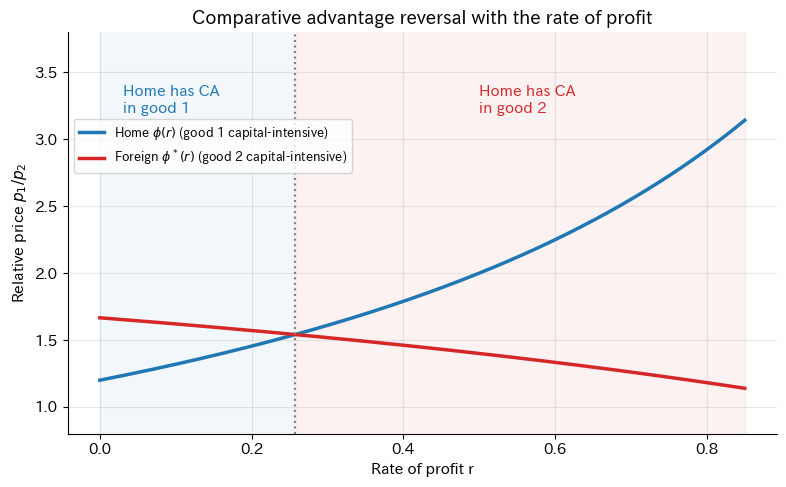

In [28]:
def k_of(r, aKK=0.5, aLK=0.5):
    return (1 + r) * aLK / (1 - (1 + r) * aKK)

def phi(tech, r):
    aK1, aL1, aK2, aL2 = tech
    k = k_of(r)
    return (aK1 * k + aL1) / (aK2 * k + aL2)

HOME = (2.0, 1.0, 0.5, 2.0)
FOREIGN = (0.5, 2.0, 0.5, 1.0)

# 逆転する利潤率を記号的に求める
rs_ = sp.symbols('r')
kk = (1 + rs_) / (1 - rs_)
phiH = (2 * kk + 1) / (kk / 2 + 2); phiF = (kk / 2 + 2) / (kk / 2 + 1)
r_star = [s for s in sp.solve(sp.Eq(phiH, phiF), rs_) if 0 < float(s) < 1][0]
print('逆転する利潤率 r* =', r_star, '≈', float(r_star))

rr = np.linspace(0, 0.85, 300)
plt.figure(figsize=(8, 5))
plt.plot(rr, [phi(HOME, x) for x in rr], color=C['home'], lw=2.5, label=r'Home $\phi(r)$ (good 1 capital-intensive)')
plt.plot(rr, [phi(FOREIGN, x) for x in rr], color=C['foreign'], lw=2.5, label=r'Foreign $\phi^*(r)$ (good 2 capital-intensive)')
plt.axvline(float(r_star), color=C['gray'], ls=':')
plt.fill_between(rr, 0, 4, where=rr < float(r_star), color=C['home'], alpha=0.06)
plt.fill_between(rr, 0, 4, where=rr > float(r_star), color=C['foreign'], alpha=0.06)
plt.text(0.03, 3.2, 'Home has CA\nin good 1', color=C['home'])
plt.text(0.5, 3.2, 'Home has CA\nin good 2', color=C['foreign'])
plt.xlabel('Rate of profit r'); plt.ylabel('Relative price $p_1/p_2$')
plt.ylim(0.8, 3.8); plt.title('Comparative advantage reversal with the rate of profit')
plt.legend(loc='upper left', bbox_to_anchor=(0.0, 0.8), fontsize=9); plt.tight_layout(); plt.show()

利潤率 $r^{\ast} = 15/11 - 2\sqrt{37}/11 \approx 25.8\%$ を境に、比較優位の向きが逆転します。**技術はまったく同じなのに、分配（利潤率）が変わるだけで、どちらの国が何を輸出するかが入れ替わる**のです。

用語について一言。Gemini さんはこれを「リスイッチング（Reswitching）／資本逆転（Capital Reversal）」と呼びましたが、厳密にはこれらは**一国内の技術選択**についての概念です（ケンブリッジ資本論争；Sraffa 1960, Samuelson 1966）。ここで見たものは「分配による比較優位の逆転」と呼ぶのが正確です。ただし、両者は同じ数学的根拠 ― 価格が利潤率の非線形関数であること ― をもっており、$\phi$ と $\phi^{\ast}$ が 2 回交差すれば「再逆転」も起こりえます（上の例でも、$R=1$ を超えて式を延長すれば $r \approx 2.47$ に 2 つ目の解があります）。

## 9.6 Lean による形式化

In [29]:
%%writefile lean_src/ch09_sraffa.lean
/-! ## 第9章 資本財を含むリカード・モデル（スラッファ＝リカード型） -/
namespace SraffaRicardo

/-- 一国の技術。財 i（i = 1, 2）は資本財 `aKi` と労働 `aLi` で、
  資本財は資本財 `aKK` と労働 `aLK` で生産される（流動資本、1期で使い切る）。 -/
structure Tech where
  aK1 : ℝ
  aL1 : ℝ
  aK2 : ℝ
  aL2 : ℝ
  hK1 : 0 < aK1
  hL1 : 0 < aL1
  hK2 : 0 < aK2
  hL2 : 0 < aL2

/-- 賃金を 1 としたときの「`(1+r) × 資本財価格`」を `k` とおくと、
  財1の財2建て相対価格は `φ(k) = (aK1 k + aL1)/(aK2 k + aL2)`。 -/
noncomputable def relPrice (t : Tech) (k : ℝ) : ℝ :=
  (t.aK1 * k + t.aL1) / (t.aK2 * k + t.aL2)

/-- 資本財部門: `k(r) = (1+r) aLK / (1 - (1+r) aKK)`。 -/
noncomputable def kOf (aKK aLK r : ℝ) : ℝ := (1 + r) * aLK / (1 - (1 + r) * aKK)

/-- `k(r)` は利潤率 `r` について狭義単調増加（`(1+r') aKK < 1` の範囲で）。 -/
theorem kOf_strictMono (aKK aLK r r' : ℝ) (hKK : 0 < aKK) (hLK : 0 < aLK)
    (hrr : r < r') (hmax : (1 + r') * aKK < 1) :
    kOf aKK aLK r < kOf aKK aLK r' := by
  unfold kOf
  have h1 : 0 < 1 - (1 + r) * aKK := by nlinarith
  have h2 : 0 < 1 - (1 + r') * aKK := by linarith
  rw [div_lt_div_iff₀ h1 h2]
  nlinarith

/-- **相対価格の単調性**: `k` が大きくなる（利潤率が上がる）と、財1の相対価格が上がるのは、
  財1が財2より資本集約的（`aK1/aL1 > aK2/aL2`）であるとき、かつそのときに限る。 -/
theorem relPrice_increasing_iff (t : Tech) {k k' : ℝ} (hk : 0 ≤ k) (hkk : k < k') :
    relPrice t k < relPrice t k' ↔ t.aL1 * t.aK2 < t.aK1 * t.aL2 := by
  unfold relPrice
  have hk' : 0 < k' := lt_of_le_of_lt hk hkk
  have d1 : 0 < t.aK2 * k + t.aL2 := by nlinarith [t.hK2, t.hL2]
  have d2 : 0 < t.aK2 * k' + t.aL2 := by nlinarith [t.hK2, t.hL2]
  rw [div_lt_div_iff₀ d1 d2]
  have key : (t.aK1 * k + t.aL1) * (t.aK2 * k' + t.aL2)
      - (t.aK1 * k' + t.aL1) * (t.aK2 * k + t.aL2)
      = (k' - k) * (t.aL1 * t.aK2 - t.aK1 * t.aL2) := by ring
  have hpos : 0 < k' - k := sub_pos.2 hkk
  constructor
  · intro H
    by_contra hc
    have hc' : 0 ≤ t.aL1 * t.aK2 - t.aK1 * t.aL2 := by linarith [not_lt.mp hc]
    nlinarith [mul_nonneg hpos.le hc']
  · intro H
    have : (k' - k) * (t.aL1 * t.aK2 - t.aK1 * t.aL2) < 0 :=
      mul_neg_of_pos_of_neg hpos (by linarith)
    linarith

/-- 数値例の自国。財1は資本集約的。 -/
noncomputable def home : Tech := ⟨2, 1, 1/2, 2, by norm_num, by norm_num, by norm_num, by norm_num⟩
/-- 数値例の外国。 -/
noncomputable def foreign : Tech := ⟨1/2, 2, 1/2, 1, by norm_num, by norm_num, by norm_num, by norm_num⟩

/-- 資本財部門の技術を両国共通に `aKK = aLK = 1/2` とすると `k(0) = 1`, `k(1/2) = 3`。 -/
theorem k_values : kOf (1/2) (1/2) 0 = 1 ∧ kOf (1/2) (1/2) (1/2) = 3 := by
  norm_num [kOf]

/-- **利潤率による比較優位の逆転**: 利潤率 0（＝労働価値で測った費用）では自国が財1に
  比較優位をもつが、利潤率 50% では自国は財2に比較優位をもつ。 -/
theorem comparative_advantage_reversal :
    relPrice home (kOf (1/2) (1/2) 0) < relPrice foreign (kOf (1/2) (1/2) 0) ∧
    relPrice foreign (kOf (1/2) (1/2) (1/2)) < relPrice home (kOf (1/2) (1/2) (1/2)) := by
  obtain ⟨h0, h1⟩ := k_values
  rw [h0, h1]
  norm_num [relPrice, home, foreign]

/-- **定常状態での貿易の損失**: 財2に特化して財1を国際価格 `p` で輸入する国において、
  `p` が財1の労働価値比 `v₁/v₂` を上回るなら、同じ消費 `(c₁, c₂)`（`c₁ > 0`）を得るのに
  自給自足より多くの労働が要る。 -/
theorem steady_state_loss (v1 v2 p c1 c2 : ℝ) (hp : v1 < p * v2)
    (hc1 : 0 < c1) :
    v1 * c1 + v2 * c2 < v2 * (c2 + p * c1) := by
  nlinarith [mul_lt_mul_of_pos_right hp hc1]

end SraffaRicardo

Overwriting lean_src/ch09_sraffa.lean


最後の定理 `steady_state_loss` は次節の主張の代数的な核です。

## 9.7 定常状態で貿易が損をもたらす

利潤率が正のとき、市場価格は労働価値からずれます。成長のない定常状態では、ある財 1 単位を「純生産物として」得るのに社会が要する労働は労働価値 $v_i$ そのものです（資本財の補填分を含めて）。したがって**定常状態での消費可能性は労働価値で決まり、価格では決まりません**。

ところが市場は価格で特化を決めます。$r > r^{\ast}$ では、自国は財2に、外国は財1に特化します ― 労働価値で見た比較優位と**逆**のパターンです。このとき、

* 自国は財1を国際価格 $p \in [\phi^{\ast}(r), \phi(r)]$ で輸入する。この $p$ が自国の労働価値比 $v_1/v_2 = 1.2$ を上回るなら、同じ消費を得るのに自給自足より多くの労働が要る（`steady_state_loss`）。
* 世界全体でも、両国の純生産の組み合わせは世界の生産可能性フロンティアの**内側**に落ちる。

labour values  Home (v1, v2) = (3.0, 2.5)   Foreign = (2.5, 1.5)


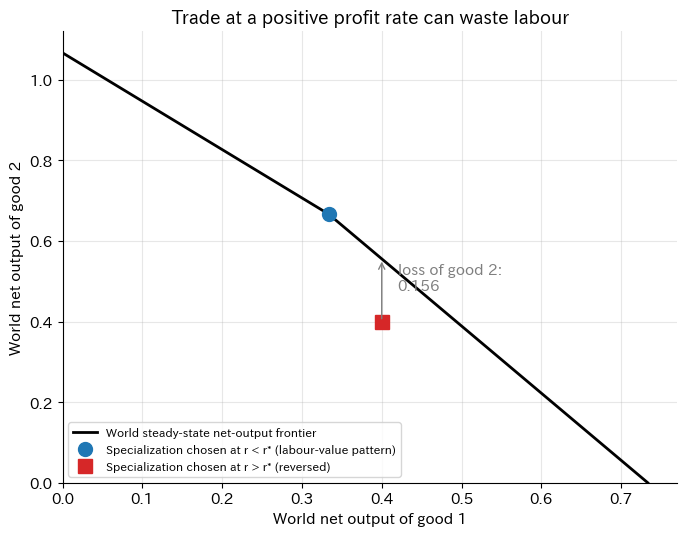

r = 0.1: price band [1.319, 1.621], Home exports good 1; Home labour-value ratio v1/v2 = 1.200, Foreign = 1.667
r = 0.4: price band [1.462, 1.789], Home exports good 2; Home labour-value ratio v1/v2 = 1.200, Foreign = 1.667
r = 0.6: price band [1.333, 2.250], Home exports good 2; Home labour-value ratio v1/v2 = 1.200, Foreign = 1.667


In [30]:
def labour_values(tech, aKK=0.5, aLK=0.5):
    vK = aLK / (1 - aKK)
    aK1, aL1, aK2, aL2 = tech
    return aL1 + aK1 * vK, aL2 + aK2 * vK

vH, vF = labour_values(HOME), labour_values(FOREIGN)
print('labour values  Home (v1, v2) =', vH, '  Foreign =', vF)

# 世界の定常状態の純生産フロンティア（各国の労働 = 1）
def world_frontier(vH, vF, n=200):
    """財1の量 x に対する財2の最大量。比較優位（労働価値）に従って財1を割り当てる。"""
    # 労働価値で見て財1の機会費用が低い国から財1を作る
    order = sorted([vH, vF], key=lambda v: v[0] / v[1])
    (v1a, v2a), (v1b, v2b) = order
    xmax = 1 / v1a + 1 / v1b
    xs = np.linspace(0, xmax, n); ys = []
    for x in xs:
        if x <= 1 / v1a:
            ys.append((1 - x * v1a) / v2a + 1 / v2b)
        else:
            ys.append((1 - (x - 1 / v1a) * v1b) / v2b)
    return xs, np.array(ys)

xs, ys = world_frontier(vH, vF)
pattern_low_r = (1 / vH[0], 1 / vF[1])      # r < r*: Home→財1, Foreign→財2
pattern_high_r = (1 / vF[0], 1 / vH[1])     # r > r*: Home→財2, Foreign→財1
plt.figure(figsize=(7, 5.5))
plt.plot(xs, ys, color='k', lw=2, label='World steady-state net-output frontier')
plt.plot(*pattern_low_r, 'o', color=C['home'], ms=10, label=f'Specialization chosen at r < r* (labour-value pattern)')
plt.plot(*pattern_high_r, 's', color=C['foreign'], ms=10, label=f'Specialization chosen at r > r* (reversed)')
x_hi = pattern_high_r[0]
y_frontier = np.interp(x_hi, xs, ys)
plt.annotate('', xy=(x_hi, y_frontier), xytext=pattern_high_r, arrowprops=dict(arrowstyle='->', color=C['gray']))
plt.text(x_hi + 0.02, (y_frontier + pattern_high_r[1]) / 2, f'loss of good 2:\n{y_frontier - pattern_high_r[1]:.3f}', color=C['gray'])
plt.xlabel('World net output of good 1'); plt.ylabel('World net output of good 2')
plt.title('Trade at a positive profit rate can waste labour'); plt.legend(fontsize=8.5, loc='lower left')
plt.xlim(0, None); plt.ylim(0, None); plt.tight_layout(); plt.show()

# 自国の損得: r > r* のとき国際価格 p は [φ*(r), φ(r)] の間
for r in [0.1, 0.4, 0.6]:
    lo, hi = sorted([phi(HOME, r), phi(FOREIGN, r)])
    home_good = 1 if phi(HOME, r) < phi(FOREIGN, r) else 2
    print(f'r = {r}: price band [{lo:.3f}, {hi:.3f}], Home exports good {home_good}; '
          f'Home labour-value ratio v1/v2 = {vH[0]/vH[1]:.3f}, Foreign = {vF[0]/vF[1]:.3f}')

$r = 0.6$ では、価格の帯 $[1.33, 2.25]$ のどこで取引されても、財1を輸入する自国にとって $p > v_1/v_2 = 1.2$ なので自国は定常状態で損をします。外国（財1を輸出、労働価値比 1.667）も、$p < 1.667$ の範囲で取引されれば損をします。**両国がともに損をする貿易**が、競争的な市場のもとで成立しうるのです。

これはメトカーフとスティードマンらが強調した論点です（Metcalfe & Steedman 1973; Steedman 1979a）。ただし注意点があります。

* 成長率 $g$ が利潤率 $r$ に等しい経済（黄金律）では、価格が「成長を考慮した真の費用」を正しく表すので、この損失は生じません。損失は $r > g$ の乖離から生じます。言い換えれば、**利潤（利子）のうち再投資されずに消費される部分が、価格を「労働で測った費用」からずらし、特化のパターンを誤らせる**のです。
* 「損」とは定常状態の純生産で測った損です。資本家の利潤や移行過程は別に考える必要があります。

## 9.8 この章から JRF のメモへ

1. **比較優位は分配に依存する。** 利潤率（利子率）が変わると比較優位が入れ替わる。利子率は金融・資本市場で決まる変数なので、**資本取引（金融）が比較優位のパターンそのものを動かしうる**。これは (M3)「比較優位を資本取引のからむ議論につなげるのは慎重に」の、もう一つの理論的根拠です。
2. **利子の存在が、貿易を損にしうる。** 労働しか要素がないモデルでは貿易の利益は保証されていました（定理 3.4）。利潤率が正で、それが再投資されない（利子生活者が消費する）経済では、その保証が失われます。(M1) の「利子生活者」は、ここでも比較優位の結論を変える鍵になっています。
3. 他方、このモデルの資本財は「流動資本」で、国内で生産され、貿易されません。**資本財が貿易され、蓄積され、時間とともに生産性を変える**とどうなるか ― それが次の第10〜12章の主題です。

---
# 10. 資本財を入れる (2) ― ハミルトン＝リスト的保護貿易論

## 10.1 系譜

Gemini さんが「資本財の輸入・蓄積によって国の生産性フロンティアが時間とともに変化する過程」の例として挙げたのが、**学習効果を伴う動的リカード・モデル**としての幼稚産業保護論でした。JRF は「ハミルトン・リスト的保護貿易論の定式化が私のやりたかったもの」と応じています。

* **アレクサンダー・ハミルトン**（Hamilton 1791『製造業に関する報告書』）：米国初代財務長官として、製造業の育成のために保護関税と奨励金を提言した。
* **フリードリッヒ・リスト**（List 1841『政治経済学の国民的体系』）：ドイツの関税同盟を背景に、「生産力の理論」を掲げ、国が工業化の段階に達するまでの教育的保護を主張した。先に工業化した国が自由貿易を説くのは「登りきった梯子を外す」ことだ、という比喩は、チャン（Chang 2002『はしごを外せ』）が現代に甦らせた。
* **J. S. ミル**（Mill 1848『経済学原理』第5編第10章）は、自由貿易論者でありながら、新しい国での一時的な保護を正当な例外として認めた。
* **バステーブル**（Bastable 1891）とケンプ（Kemp 1960）は、保護が正当化される条件を整理した。**ミルの基準**：保護された産業が、いずれ保護なしで競争できるようになること。**バステーブルの基準**：その将来の利益の現在価値が、保護期間中の損失を上回ること。ケンプはさらに、学習が企業の外部に溢れ出す（外部性がある）場合に限って、政府の介入が正当化されると論じた。
* 理論の現代的な形：アロー（Arrow 1962）の**学習効果**（learning by doing）を、クルーグマン（Krugman 1987）、ルーカス（Lucas 1988）、ヤング（Young 1991）、レディング（Redding 1999）らが動的比較優位のモデルに組み込んだ。メリッツ（Melitz 2005）は、学習の曲線と競争環境しだいで、関税・数量制限・補助金のどれが望ましいかが変わることを示した。
* 実証：ジュハース（Juhász 2018）は、ナポレオンの大陸封鎖がフランスの一部地域を英国の綿業から「一時的に保護」した自然実験を使い、保護された地域で機械紡績が定着し、封鎖解除後も長く優位が持続したことを示した。

フランク・グレアム（Graham 1923）が、収穫逓増の産業を手放す特化は損でありうることを示した「グレアムのパラドックス」も、この系譜の先駆です。

## 10.2 モデル（会話で示された定式化）

2財（伝統財・農業 $A$、製造業 $M$）、労働のみが可変投入（総量 $L$）の小国を考えます。$Y_A, Y_M$ は農業・製造業の産出量、$L_A, L_M$ はそれぞれの雇用（$L_A + L_M = L$）、$A_A, A_M$ は 1 人あたりの生産性、$\dot A_M$ は $A_M$ の時間微分（変化の速さ）です。
$$
Y_A = A_A L_A, \qquad Y_M = A_M(t)\,L_M ,
\qquad
\frac{\dot A_M(t)}{A_M(t)} = \delta\, L_M(t) \quad(\delta > 0).
$$
農業の生産性 $A_A$ は一定、製造業の生産性 $A_M(t)$ は**作ることによって上がる**（アロー型の学習）。世界価格は $p^{\ast} = p_M^{\ast}/p_A^{\ast}$（$p_M^{\ast}, p_A^{\ast}$ は工業品・農産物の世界市場での価格）。

自国の自給相対価格は $p_{\mathrm{aut}}(t) = A_A / A_M(t)$。初期に $A_M(0)$ が小さく $p^{\ast} < p_{\mathrm{aut}}(0)$ なら：

* **自由貿易の罠**：自国は静的比較優位に従って農業に完全特化（$L_M = 0$）。すると $\dot A_M = 0$ で、$A_M$ は永久に $A_M(0)$ のまま。「資本財（工業品）を輸入し、一次産品を輸出する構造」に固定される。
* **保護関税**：輸入工業品に従価関税（価格に対する税率）$\tau$ を課し（第3章の交易条件 $\tau$ とは別の記号です）、$(1+\tau)p^{\ast} \ge A_A/A_M(t)$ とすれば、国内で製造業が採算に乗り、$L_M > 0$ となって学習が始まる。
* **離陸と撤廃**（リスト的出口条件）：$A_M(t) \ge A_A/p^{\ast}$ に達したら関税を撤廃する。以後は自由貿易のもとで製造業に比較優位をもつ。

**市場の失敗**：個々の企業は、自分がいま製造業を営むことが将来の国全体の $A_M$ を押し上げるという効果（知識の溢れ出し）を価格に織り込めません。だから市場に任せると「罠」から抜け出せない、というのがこの議論の経済学的な核心です。

## 10.3 Lean による形式化

### (1) 会話で示された骨組みと、その `sorry` の解消

会話で Gemini さんが示したコードは、学習効果の結果である下限 $A_M(t) \ge A_{M0}(1 + \delta L_{\min} t)$（$A_{M0} = A_M(0)$ は初期の生産性、$L_{\min}$ は関税によって保証される製造業の最低雇用、threshold は自立化の閾値 $A_A/p^{\ast}$）を公理 `hLearning` として置き、主定理の証明を `sorry`（未完）のままにしていました。Gemini さんが指示した方針どおり、$T = \text{threshold}/(A_{M0}\,\delta\,L_{\min})$ を明示的に与えれば証明は完成します。

In [31]:
%%writefile lean_src/ch10_infant.lean
/-! ## 第10章 ハミルトン＝リスト的幼稚産業保護 -/

/-- Gemini さんとの会話で示された骨組み（連続時間・下限成長を公理とする版）。 -/
structure InfantIndustryModel where
  A_A : ℝ
  p_star : ℝ
  delta : ℝ
  L_min : ℝ
  A_M0 : ℝ
  hA_A : 0 < A_A
  hp_star : 0 < p_star
  hdelta : 0 < delta
  hL_min : 0 < L_min
  hA_M0 : 0 < A_M0
  A_M : ℝ → ℝ
  L_M : ℝ → ℝ
  tau : ℝ → ℝ
  hA_M_init : A_M 0 = A_M0
  hProtection : ∀ t ≥ 0, 0 < tau t → L_min ≤ L_M t
  hLearning : ∀ t ≥ 0, A_M0 * (1 + delta * L_min * t) ≤ A_M t

namespace InfantIndustryModel

/-- 自立化の閾値 `A_A / p*`。 -/
noncomputable def threshold (model : InfantIndustryModel) : ℝ :=
  model.A_A / model.p_star

/-- 会話では `sorry` のまま残っていた主定理。`T = threshold / (A_M0 δ L_min)` で埋まる。 -/
theorem self_sustainability_achievable (model : InfantIndustryModel) :
    ∃ T : ℝ, 0 ≤ T ∧ model.threshold ≤ model.A_M T := by
  have hk : 0 < model.A_M0 * model.delta * model.L_min :=
    mul_pos (mul_pos model.hA_M0 model.hdelta) model.hL_min
  have hth : 0 < model.threshold := div_pos model.hA_A model.hp_star
  refine ⟨model.threshold / (model.A_M0 * model.delta * model.L_min), by positivity, ?_⟩
  have hL := model.hLearning (model.threshold / (model.A_M0 * model.delta * model.L_min))
    (by positivity)
  have e : model.A_M0 * (1 + model.delta * model.L_min *
      (model.threshold / (model.A_M0 * model.delta * model.L_min)))
      = model.A_M0 + model.threshold := by
    have h1 := model.hA_M0.ne'
    have h2 := model.hdelta.ne'
    have h3 := model.hL_min.ne'
    field_simp
  linarith [model.hA_M0]

end InfantIndustryModel

Overwriting lean_src/ch10_infant.lean


### (2) 公理を定理に ― 離散時間版

しかし、学習効果の下限を「公理」として置くのは、示すべきことを仮定しているようなものです。離散時間 $A_{n+1} = A_n(1 + \delta L_n)$ なら、**ベルヌーイの不等式**型の議論で下限そのものを証明できます。あわせて「自由貿易の罠」も定理にします。

In [32]:
%%writefile -a lean_src/ch10_infant.lean

namespace InfantIndustry

/-- **離散時間版の学習効果**: `A_{n+1} = A_n (1 + δ L_n)`, `L_n ≥ L_min` なら
  `A_n ≥ A_0 (1 + δ L_min n)`（ベルヌーイの不等式型の下限）。公理ではなく定理として導く。 -/
theorem learning_lower_bound (A L : ℕ → ℝ) (δ Lmin : ℝ) (hδ : 0 ≤ δ) (hLmin : 0 ≤ Lmin)
    (hL : ∀ n, Lmin ≤ L n) (hA0 : 0 < A 0)
    (hrec : ∀ n, A (n + 1) = A n * (1 + δ * L n)) :
    ∀ n : ℕ, A 0 * (1 + δ * Lmin * n) ≤ A n := by
  intro n
  induction n with
  | zero => simp
  | succ n ih =>
    rw [hrec n]
    have hb : 0 ≤ δ * Lmin := mul_nonneg hδ hLmin
    have h1 : δ * Lmin ≤ δ * L n := mul_le_mul_of_nonneg_left (hL n) hδ
    have hAn : 0 ≤ A n := le_trans (by positivity) ih
    have step : A 0 * (1 + δ * Lmin * n) * (1 + δ * Lmin) ≤ A n * (1 + δ * L n) := by
      apply mul_le_mul ih (by linarith) (by linarith) hAn
    have hn : (0 : ℝ) ≤ n := Nat.cast_nonneg n
    push_cast
    nlinarith [mul_nonneg (mul_nonneg hA0.le hb) (mul_nonneg hb hn)]

/-- **離陸の定理**: 保護により `L_n ≥ L_min > 0` が保たれれば、どんな閾値もいつか超える。 -/
theorem takeoff (A L : ℕ → ℝ) (δ Lmin θ : ℝ) (hδ : 0 < δ) (hLmin : 0 < Lmin)
    (hL : ∀ n, Lmin ≤ L n) (hA0 : 0 < A 0)
    (hrec : ∀ n, A (n + 1) = A n * (1 + δ * L n)) :
    ∃ N : ℕ, θ ≤ A N := by
  obtain ⟨N, hN⟩ := exists_nat_gt (θ / (A 0 * δ * Lmin))
  refine ⟨N, ?_⟩
  have hb := learning_lower_bound A L δ Lmin hδ.le hLmin.le hL hA0 hrec N
  have hk : 0 < A 0 * δ * Lmin := by positivity
  have : θ < A 0 * δ * Lmin * N := by
    rw [div_lt_iff₀ hk] at hN; linarith
  nlinarith

/-- **自由貿易の罠**: 製造業に労働が配分されない（`L_n = 0`）限り、生産性は永久に動かない。 -/
theorem free_trade_trap (A L : ℕ → ℝ) (δ : ℝ) (hL : ∀ n, L n = 0)
    (hrec : ∀ n, A (n + 1) = A n * (1 + δ * L n)) : ∀ n, A n = A 0 := by
  intro n
  induction n with
  | zero => rfl
  | succ n ih => rw [hrec n, hL n, ih]; ring

Appending to lean_src/ch10_infant.lean


### (3) 連続時間版 ― 微分方程式から公理を導く

連続時間 $\dot A = \delta A L$ の場合、$g(t) = A(t)\,e^{-\delta L_{\min} t}$ という補助関数を考えると、
$$
g'(t) = \delta A(t) e^{-\delta L_{\min}t}\,\big(L(t) - L_{\min}\big) \ge 0
$$
なので $g$ は単調増加、$g(t) \ge g(0) = A(0)$。よって $A(t) \ge A(0)\,e^{\delta L_{\min}t} \ge A(0)(1 + \delta L_{\min}t)$（最後は $e^x \ge 1+x$）。Mathlib の `monotoneOn_of_deriv_nonneg`（導関数が非負なら単調）と `Real.add_one_le_exp` を使って、これをそのまま書きます。会話の公理 `hLearning` は、ここで定理 `learning_axiom_derived` になります。

In [33]:
%%writefile -a lean_src/ch10_infant.lean

/-- **連続時間版**: `A' = δ A L`, `A > 0`, `t ≥ 0` で `L ≥ L_min` なら
  `A(t) ≥ A(0) e^{δ L_min t}`。会話で公理 `hLearning` として置かれた不等式は、
  ここから系として従う（下の `learning_axiom_derived`）。 -/
theorem learning_exp_lower_bound (A L : ℝ → ℝ) (δ Lmin : ℝ) (hδ : 0 ≤ δ)
    (hA : ∀ t, HasDerivAt A (δ * A t * L t) t) (hpos : ∀ t, 0 < A t)
    (hL : ∀ t, 0 ≤ t → Lmin ≤ L t) :
    ∀ t, 0 ≤ t → A 0 * Real.exp (δ * Lmin * t) ≤ A t := by
  set c := δ * Lmin with hc
  set g : ℝ → ℝ := fun t => A t * Real.exp (-c * t) with hg_def
  have hg : ∀ t, HasDerivAt g
      (δ * A t * L t * Real.exp (-c * t) + A t * (Real.exp (-c * t) * (-c))) t := by
    intro t
    have h1 : HasDerivAt (fun t => -c * t) (-c) t := by
      simpa using (hasDerivAt_id t).const_mul (-c)
    exact (hA t).mul h1.exp
  have hmono : MonotoneOn g (Set.Ici 0) := by
    apply monotoneOn_of_deriv_nonneg (convex_Ici 0)
    · exact fun t _ => (hg t).continuousAt.continuousWithinAt
    · exact fun t _ => (hg t).differentiableAt.differentiableWithinAt
    · intro t ht
      rw [interior_Ici] at ht
      rw [(hg t).deriv]
      have hLt := hL t (le_of_lt ht)
      have he := Real.exp_pos (-c * t)
      have hAt := hpos t
      have : δ * A t * L t * Real.exp (-c * t) + A t * (Real.exp (-c * t) * (-c))
          = δ * (A t * Real.exp (-c * t)) * (L t - Lmin) := by rw [hc]; ring
      rw [this]
      exact mul_nonneg (mul_nonneg hδ (mul_pos hAt he).le) (by linarith)
  intro t ht
  have h0 := hmono (Set.mem_Ici.2 le_rfl) ht ht
  simp only [hg_def, mul_zero, Real.exp_zero, mul_one] at h0
  have he : Real.exp (-c * t) * Real.exp (c * t) = 1 := by
    rw [← Real.exp_add]; simp
  calc A 0 * Real.exp (c * t) ≤ A t * Real.exp (-c * t) * Real.exp (c * t) :=
        mul_le_mul_of_nonneg_right h0 (Real.exp_pos _).le
    _ = A t := by rw [mul_assoc, he, mul_one]

/-- 会話の公理 `hLearning` はモデルの微分方程式から導ける。 -/
theorem learning_axiom_derived (A L : ℝ → ℝ) (δ Lmin : ℝ) (hδ : 0 ≤ δ)
    (hA : ∀ t, HasDerivAt A (δ * A t * L t) t) (hpos : ∀ t, 0 < A t)
    (hL : ∀ t, 0 ≤ t → Lmin ≤ L t) :
    ∀ t, 0 ≤ t → A 0 * (1 + δ * Lmin * t) ≤ A t := by
  intro t ht
  have h := learning_exp_lower_bound A L δ Lmin hδ hA hpos hL t ht
  have h2 : 1 + δ * Lmin * t ≤ Real.exp (δ * Lmin * t) := by
    linarith [Real.add_one_le_exp (δ * Lmin * t)]
  nlinarith [hpos 0]

end InfantIndustry

Appending to lean_src/ch10_infant.lean


## 10.4 シミュレーション ― 保護は割に合うか

形式化した定理は「いつか離陸できる」（ミルの基準）ことを保証しますが、「それが得か」（バステーブルの基準）には答えません。それには厚生の比較が要ります。次の設定でシミュレーションします。

* 消費者は所得の割合 $\alpha$ を工業品に支出する（コブ＝ダグラス）。時刻 $t$ の効用（実質所得で測った豊かさ）を $V(t)$ とし、国全体の厚生 $W$ をその対数の割引現在価値 $W = \int_0^\infty e^{-\rho t}\ln V(t)\,dt$ で測る（$\rho$ は割引率）。
* **自由貿易**：農業に特化し、所得 $A_A L$ で世界価格 $p^{\ast}$ の工業品を買う。
* **保護（禁止的関税）**：自給自足と同じく両財を国内生産、$L_M = \alpha L$、価格 $A_A/A_M$。
* **離陸後**：関税を撤廃し、製造業に特化して $p^{\ast}A_M L$ の所得を得る。
* 学習には上限 $\bar A$ を設ける（8.5 節の $\bar A$ とは別の記号）：$\dot A_M = \delta A_M L_M (1 - A_M/\bar A)$。会話のモデル（上限なし）では、製造業に特化した後 $A_M$ が指数的に無限に伸び続け、どんな保護も「割に合う」ことになってしまうからです。

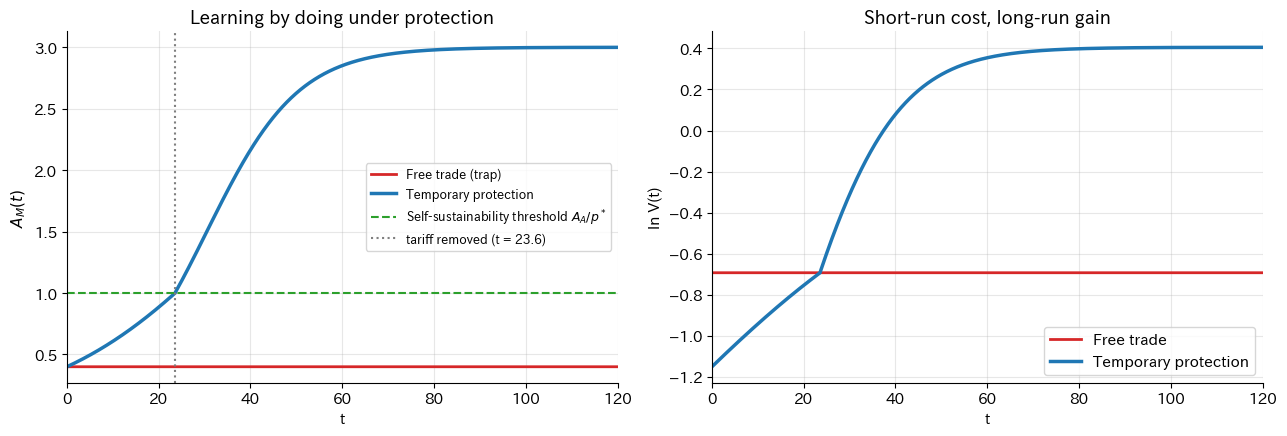

W(free) = -23.048,  W(protect) = -14.461,  difference = +8.586


In [34]:
def infant_industry(delta=0.10, rho=0.03, AM0=0.4, Abar=3.0, A_A=1.0, pstar=1.0,
                    alpha=0.5, L=1.0, T=200, policy='protect', n=4001):
    """policy: 'free'（自由貿易のまま）, 'protect'（離陸まで保護して撤廃）"""
    thr = A_A / pstar
    cst = alpha ** alpha * (1 - alpha) ** (1 - alpha)
    t = np.linspace(0, T, n)
    if policy == 'free':
        A = np.full_like(t, AM0)
    else:
        def rhs(_, y):
            a = y[0]
            LM = L if a >= thr else alpha * L
            return [delta * a * LM * (1 - a / Abar)]
        A = solve_ivp(rhs, (0, T), [AM0], t_eval=t, max_step=0.1).y[0]
    V = np.where(A >= thr, pstar * A * L * cst / pstar ** alpha,            # 製造業に特化
                 np.where(policy == 'free', A_A * L * cst / pstar ** alpha,  # 農業に特化（自由貿易）
                          A_A * L * cst * (A / A_A) ** alpha))              # 保護下（自給自足）
    W = trapezoid(np.exp(-rho * t) * np.log(V), t)
    t_exit = t[np.argmax(A >= thr)] if (A >= thr).any() else np.inf
    return dict(t=t, A=A, V=V, W=W, t_exit=t_exit)

free, prot = infant_industry(policy='free'), infant_industry()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(free['t'], free['A'], color=C['foreign'], lw=2, label='Free trade (trap)')
axes[0].plot(prot['t'], prot['A'], color=C['home'], lw=2.5, label='Temporary protection')
axes[0].axhline(1.0, color=C['third'], ls='--', label='Self-sustainability threshold $A_A/p^*$')
axes[0].axvline(prot['t_exit'], color=C['gray'], ls=':', label=f"tariff removed (t = {prot['t_exit']:.1f})")
axes[0].set_xlim(0, 120); axes[0].set_xlabel('t'); axes[0].set_ylabel('$A_M(t)$'); axes[0].legend(fontsize=9)
axes[0].set_title('Learning by doing under protection')
axes[1].plot(free['t'], np.log(free['V']), color=C['foreign'], lw=2, label='Free trade')
axes[1].plot(prot['t'], np.log(prot['V']), color=C['home'], lw=2.5, label='Temporary protection')
axes[1].set_xlim(0, 120); axes[1].set_xlabel('t'); axes[1].set_ylabel('ln V(t)')
axes[1].set_title('Short-run cost, long-run gain'); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"W(free) = {free['W']:.3f},  W(protect) = {prot['W']:.3f},  difference = {prot['W'] - free['W']:+.3f}")

保護の期間中、厚生は自由貿易を下回ります（高い国産工業品を買わされる「死荷重」）。離陸して関税を撤廃した後は、製造業に特化して自由貿易を上回ります。どちらが勝つかは、学習の速さ $\delta$ と割引率 $\rho$ しだいです。

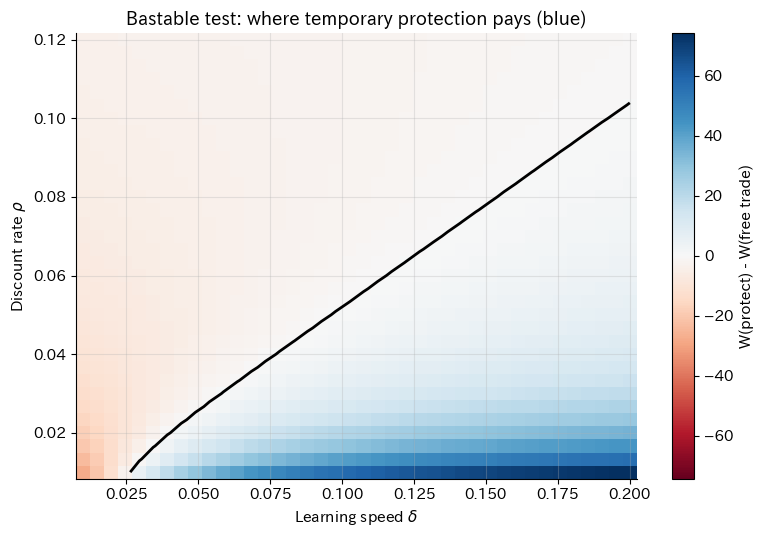

In [35]:
deltas = np.linspace(0.01, 0.20, 40)
rhos = np.linspace(0.01, 0.12, 34)
discount = lambda t, V, rho: trapezoid(np.exp(-rho * t) * np.log(V), t)
# 動学は ρ に依存しないので、δ ごとに 1 回だけ解き、厚生は ρ ごとに計算し直す
paths = [infant_industry(delta=d, n=2001) for d in deltas]
fpath = infant_industry(policy='free', n=2001)
gain = np.array([[discount(pt['t'], pt['V'], rho) - discount(fpath['t'], fpath['V'], rho)
                  for pt in paths] for rho in rhos])
plt.figure(figsize=(8, 5.5))
lim = np.abs(gain).max()
im = plt.pcolormesh(deltas, rhos, gain, cmap='RdBu', vmin=-lim, vmax=lim, shading='auto')
cs = plt.contour(deltas, rhos, gain, levels=[0], colors='k', linewidths=2)
plt.colorbar(im, label='W(protect) - W(free trade)')
plt.xlabel(r'Learning speed $\delta$'); plt.ylabel(r'Discount rate $\rho$')
plt.title('Bastable test: where temporary protection pays (blue)')
plt.tight_layout(); plt.show()

青い領域（右下：学習が速く、将来を重く見る）では保護が割に合い、赤い領域（左上：学習が遅い、または近視眼的）では割に合いません。黒い線がバステーブルの基準の境界です。

さらに、学習の上限 $\bar A$ が自立化の閾値 $A_A/p^{\ast}$ に届かなければ（$\bar A < A_A/p^{\ast}$）、どれだけ保護しても離陸できません（ミルの基準の不成立）。保護は永続化し、損失だけが残ります。また $\bar A$ が閾値をわずかに上回るだけ（下の $\bar A = 1.2$）なら、離陸はできても時間がかかりすぎ、保護は割に合いません。**ミルの基準を満たしても、バステーブルの基準を満たすとは限らない**のです。

In [36]:
for Abar in [3.0, 1.2, 0.9]:
    out = infant_industry(Abar=Abar)
    print(f'Abar = {Abar}: exit time = {out["t_exit"]}, W(protect) - W(free) = {out["W"] - free["W"]:+.3f}')

Abar = 3.0: exit time = 23.6, W(protect) - W(free) = +8.586
Abar = 1.2: exit time = 46.1, W(protect) - W(free) = -4.635
Abar = 0.9: exit time = inf, W(protect) - W(free) = -7.627


## 10.5 この章から JRF のメモへ

* このモデルでは、**比較優位は与えられたものではなく、過去の生産の履歴（どれだけ作ってきたか）によって作られる**。JRF が 2011 年 10 月に書いた「単に過去の生産設備があるため低コストでできるということであれば、その『優位』は…容易にくつがえされる」(M0) は、まさにこの経路依存性の指摘です。
* くつがえす力をもつのは、ここでは**関税をかける国家**でした。しかし学習の「燃料」が、外国から輸入される資本財（機械・設備）だとしたらどうでしょう。くつがえす力は、資本財を**供給する国**の手にも握られることになります。これが JRF の次の問いであり、第11章の主題です。
* 保護の批判も忘れてはいけません。どの産業が「幼稚産業」かを政府が見分けられるか、保護が既得権化して撤廃されなくなる危険（上の $\bar A < A_A/p^{\ast}$ の場合）、報復関税の連鎖などです。

---
# 11. 資本財を入れる (3) ― 供給国による優位の付け替えと「減耗のコントロール」

## 11.1 問い

ハミルトン＝リストのモデルを見た後、JRF は次のように問いました。

> ハミルトン・リストのモデルは私が言いたいことをだいたい言ってくれているのですが、少し変形した見解として、資本財を輸出する国は、その輸出先を変更することで、容易に、他の国に優位性をもたらし、逆に劣位性に置くことができるとも考えていました。その議論はできそうですか？ 数式で。

Gemini さんは、これを現代の地政学的経済学（geo-economics）における**「相互依存の武器化」**（weaponized interdependence; Farrell & Newman 2019）や、技術禁輸による動的比較優位の操作として定式化しました。

この考え方には古い先駆があります。ハーシュマン（Hirschman 1945『国力と外国貿易の構造』）は、貿易が大国に与える力を、輸入で国内の供給を増やす**供給効果**と、相手国を自国との貿易に依存させることで政治的影響力を得る**影響効果**とに分けて分析しました。冷戦期には、西側諸国が対共産圏輸出統制委員会（COCOM）を通じて戦略物資・技術の輸出を統制しました。2010 年には、中国によるレアアースの対日輸出停止が問題になり ― 2011 年版のウィキペディア「比較優位」の「安全保障の問題」の節にもこの事件が記されています ― 2020 年代には半導体製造装置の輸出規制が大きな争点になりました。

## 11.2 モデル（会話で示された定式化）

* 国：先進国 X（資本財の供給国）、途上国 A と B。
* X は資本財の供給能力 $\bar K$ をもち、配分比率 $s(t)\in[0,1]$ で A と B に振り分ける：$K_A = s\bar K$, $K_B = (1-s)\bar K$。
* 途上国 $i$ の製造業の産出 $Y_{M,i} = A_{M,i}\,L_{M,i}^{\alpha} K_i^{1-\alpha}$（$L_{M,i}$ は製造業の雇用、$K_i$ は使える資本財、$0<\alpha<1$ は労働の産出弾力性。資本財がなければ産出もゼロになる「コブ＝ダグラス型の生産関数」）。労働の限界生産力 $\alpha A_{M,i}(K_i/L_{M,i})^{1-\alpha}$ は $K_i \to 0$ で 0 に近づき、自給価格（限界費用）
$$
p_{\mathrm{aut},i} \propto \frac{1}{A_{M,i}}\left(\frac{L_{M,i}}{K_i}\right)^{1-\alpha}
$$
は急騰する。
* 学習は資本財へのアクセスに依存する（$\gamma > 0$ はその感応度）：
$$
\frac{\dot A_{M,i}}{A_{M,i}} = \delta\,L_{M,i}\left(\frac{K_i}{\bar K}\right)^{\gamma}.
$$

X が時刻 $t_0$ に配分を B 優遇から A 優遇へ切り替えると、A は学習が加速して比較優位を獲得し、B は学習が止まって劣位に固定される ― というのが会話の結論でした。B は**自国の関税政策ではこの劣位から抜け出せない**（関税は資本財を生み出さない）点が、第10章との決定的な違いです。

## 11.3 シミュレーション（会話で示されたコード）

以下は会話で Gemini さんが示したコードそのものです（コメントの一部を整理）。

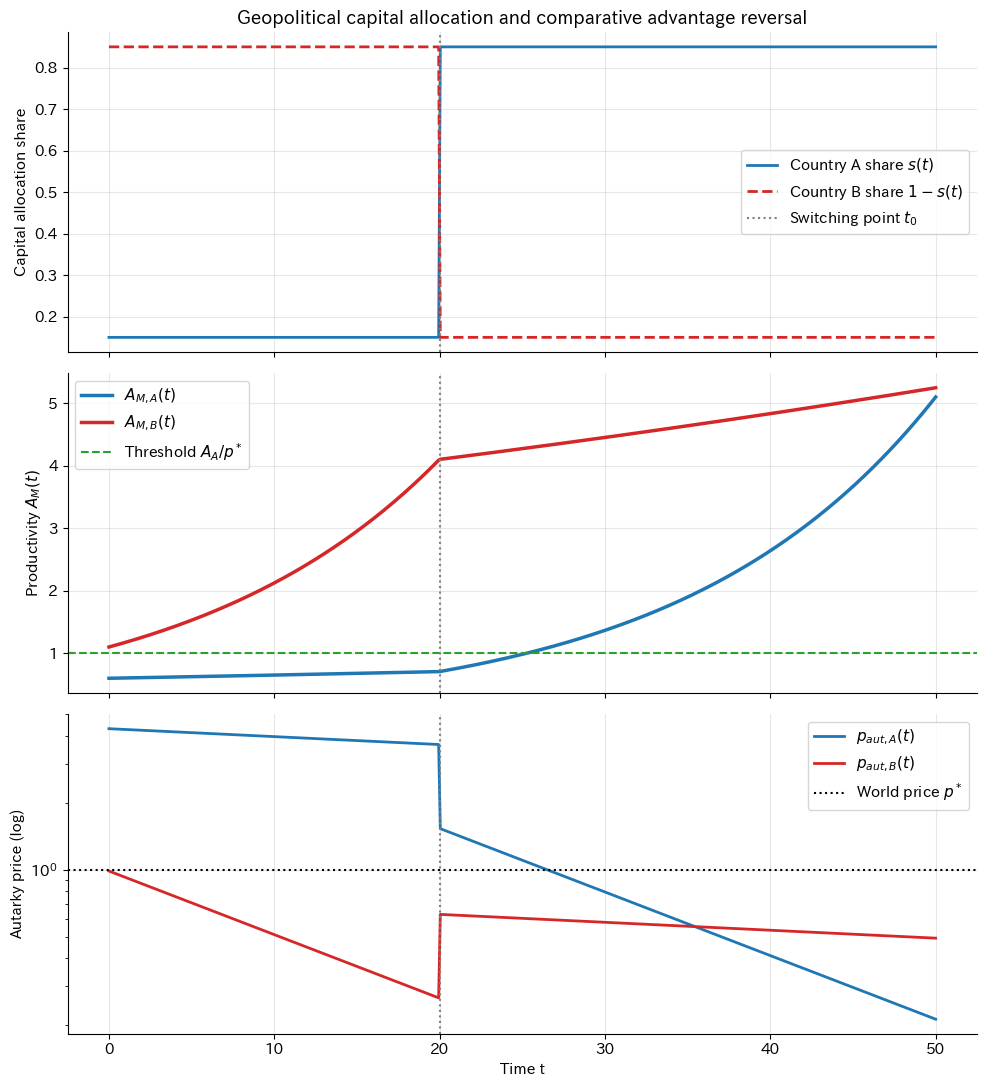

In [37]:
# =====================================================================
# 地政学的資本財配分スイッチング・モデル (Geopolitical Switching Model)
# =====================================================================
params = {
    'A_A': 1.0,         # 農業（一次産品）の生産性 (一定)
    'p_star': 1.0,      # 世界市場における相対価格 (p_M* / p_A*)
    'K_bar': 1.0,       # 供給国 X の総資本財供給能力
    'delta': 0.08,      # 学習効果の効率係数
    'gamma': 1.2,       # 資本財アクセス密度の感応度
    'L_M': 1.0,         # 各国の製造業労働投入量
    't_switch': 20.0,   # 供給国 X が配分比率を切り替える時刻 (t_0)
    's_before': 0.15,   # 切り替え前の国 A への配分比率 (国 B 優遇)
    's_after': 0.85,    # 切り替え後の国 A への配分比率 (国 A 偏重)
    'alpha': 0.5        # 生産関数における労働の弾力性
}
A_thresh = params['A_A'] / params['p_star']

def s_func(t, p):
    """時刻 t における国 A への資本財配分比率 s(t)"""
    return p['s_before'] if t < p['t_switch'] else p['s_after']

def system_ode(t, y, p):
    """y = [A_MA, A_MB] : 国 A および国 B の製造業生産性"""
    A_MA, A_MB = y
    s = s_func(t, p)
    K_A, K_B = s * p['K_bar'], (1.0 - s) * p['K_bar']
    dA_MA = p['delta'] * A_MA * p['L_M'] * (K_A / p['K_bar']) ** p['gamma']
    dA_MB = p['delta'] * A_MB * p['L_M'] * (K_B / p['K_bar']) ** p['gamma']
    return [dA_MA, dA_MB]

def run_switching(T=50.0, n=500):
    t_eval = np.linspace(0.0, T, n)
    sol = solve_ivp(system_ode, (0.0, T), [0.6, 1.1], args=(params,), t_eval=t_eval,
                    method='RK45', max_step=0.1)
    return sol.t, sol.y[0], sol.y[1]

def plot_switching(t_vec, A_MA_vec, A_MB_vec):
    s_vec = np.array([s_func(t, params) for t in t_vec])
    eps = 1e-5
    K_A_vec, K_B_vec = s_vec * params['K_bar'], (1.0 - s_vec) * params['K_bar']
    p_aut_A = (params['A_A'] / A_MA_vec) * (params['L_M'] / (K_A_vec + eps)) ** (1 - params['alpha'])
    p_aut_B = (params['A_A'] / A_MB_vec) * (params['L_M'] / (K_B_vec + eps)) ** (1 - params['alpha'])
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 11), sharex=True)
    ax1.plot(t_vec, s_vec, color=C['home'], lw=2, label='Country A share $s(t)$')
    ax1.plot(t_vec, 1 - s_vec, '--', color=C['foreign'], lw=2, label='Country B share $1-s(t)$')
    ax1.axvline(params['t_switch'], color=C['gray'], ls=':', label='Switching point $t_0$')
    ax1.set_ylabel('Capital allocation share'); ax1.legend(loc='center right')
    ax1.set_title('Geopolitical capital allocation and comparative advantage reversal', fontweight='bold')
    ax2.plot(t_vec, A_MA_vec, color=C['home'], lw=2.5, label='$A_{M,A}(t)$')
    ax2.plot(t_vec, A_MB_vec, color=C['foreign'], lw=2.5, label='$A_{M,B}(t)$')
    ax2.axhline(A_thresh, color=C['third'], ls='--', label='Threshold $A_A/p^*$')
    ax2.axvline(params['t_switch'], color=C['gray'], ls=':')
    ax2.set_ylabel('Productivity $A_M(t)$'); ax2.legend(loc='upper left')
    ax3.plot(t_vec, p_aut_A, color=C['home'], lw=2, label='$p_{aut,A}(t)$')
    ax3.plot(t_vec, p_aut_B, color=C['foreign'], lw=2, label='$p_{aut,B}(t)$')
    ax3.axhline(params['p_star'], color='k', ls=':', label='World price $p^*$')
    ax3.axvline(params['t_switch'], color=C['gray'], ls=':')
    ax3.set_yscale('log'); ax3.set_xlabel('Time t'); ax3.set_ylabel('Autarky price (log)')
    ax3.legend(loc='upper right')
    plt.tight_layout(); plt.show()

t_vec, A_MA_vec, A_MB_vec = run_switching()
plot_switching(t_vec, A_MA_vec, A_MB_vec)

### AI の説明を検算する

会話で Gemini さんは、このグラフについて「国 A の成長曲線が急浮上して $t \approx 36$ 近辺で逆転（クロスオーバー）を起こします」と説明しました。実際に計算してみると、$t = 50$ までには逆転は起きていません（上図）。解析的に確かめてみます。

$t < t_0$ では成長率が一定なので、$A_{M,A}(t_0) = 0.6\,e^{\delta\, 0.15^{\gamma} t_0}$, $A_{M,B}(t_0) = 1.1\,e^{\delta\,0.85^{\gamma} t_0}$。$t > t_0$ では成長率が入れ替わるので、逆転の時刻は
$$
t_{\times} = t_0 + \frac{\ln\big(A_{M,B}(t_0)/A_{M,A}(t_0)\big)}{\delta\,(0.85^{\gamma} - 0.15^{\gamma})}.
$$

In [38]:
d, g_, t0 = params['delta'], params['gamma'], params['t_switch']
gA, gB = d * 0.15 ** g_, d * 0.85 ** g_
A_t0, B_t0 = 0.6 * np.exp(gA * t0), 1.1 * np.exp(gB * t0)
t_cross = t0 + np.log(B_t0 / A_t0) / (gB - gA)
print(f'A(t0) = {A_t0:.3f}, B(t0) = {B_t0:.3f}  →  crossover at t = {t_cross:.2f}')
t_long, a_long, b_long = run_switching(T=80.0, n=801)
idx = np.where(np.diff(np.sign(a_long - b_long)) != 0)[0]
print('数値解での逆転時刻:', t_long[idx])

A(t0) = 0.707, B(t0) = 4.103  →  crossover at t = 50.52
数値解での逆転時刻: [50.4]


逆転は $t \approx 50.5$ で起きます。切り替え前の 20 年間に B が 4 倍近くまで成長しているので、追いつくのに時間がかかるのです。モデルの**定性的な結論**（切り替えで逆転が起きる）は正しいのですが、**数値の説明**は誤っていました。生成 AI の説明は、コードを実際に動かして確かめる必要がある ― このノートの方法論上の教訓の一つです。この「追いつくのに時間がかかる」こと自体が、**先に与えられた優位は、供給を切り替えてもすぐには消えない**という、経路依存性の表れでもあります。

## 11.4 「減耗のコントロール」― 2011年のメモ (M2)

会話のモデルでは、資本財の配分をフロー（その時点の供給量）として扱っていました。しかし実際の資本は**時間とともに摩耗・陳腐化するストック**です。JRF の 2011 年のメモは、まさにこの点を突いていました。

> 設備の革新に優位を持つというのは、設備の生産によって相手の減耗をコントロールできることを意味する。ある意味、輸出によって生産を減らす効果があることになるわけだから、二財モデルだけ見て、貿易をすれば世界で生産される量が増えるという観方はややナイーブにすぎる。

資本ストックの運動方程式を
$$
\dot K_i(t) = I_i(t) - d\,K_i(t)
$$
とします（$I_i$ は X からの設備・部品の輸入、$d$ は減耗率）。X が B への輸出を減耗分より少なく（$I_B < dK_B$）抑えれば、$\dot K_B < 0$ となり、**B の既存の産業基盤は放っておいても縮んでいきます**。X は B の工場を壊す必要はなく、ただ更新投資の供給を絞ればよいのです。

**定理 11.1**　離散時間 $K_{n+1} = (1-d)K_n + I_n$, $0 < d \le 1$ で、$0 \le I_n \le \theta\, d\, K_n$（$0 \le \theta < 1$）なら、$0 \le K_n \le (1 - (1-\theta)d)^n K_0$。とくに $\theta < 1$ なら $K_n \to 0$。

半減期はおよそ $\ln 2 / ((1-\theta) d)$。**減耗が速い設備ほど（$d$ が大きいほど）、供給国の「てこ」は強い**。JRF のメモにある「毛織物（ファッション）は減耗が発生しやすく、ワインは減耗が発生しにくい」という対比は、この $d$ の違いを、消費財の側から指摘したものと読めます。

In [39]:
%%writefile lean_src/ch11_switching.lean
/-! ## 第11章 資本財供給国による「減耗のコントロール」 -/
namespace CapitalControl

/-- 資本ストックの運動 `K_{n+1} = (1-d) K_n + I_n` において、供給国が更新投資を
  減耗の一定割合 `θ < 1` 以下（`I_n ≤ θ d K_n`）に絞ると、相手国の資本は幾何級数的に縮む。 -/
theorem capital_geometric_decay (K I : ℕ → ℝ) (d θ : ℝ) (hd0 : 0 < d) (hd1 : d ≤ 1)
    (hθ0 : 0 ≤ θ) (hK0 : 0 ≤ K 0)
    (hrec : ∀ n, K (n + 1) = (1 - d) * K n + I n)
    (hI0 : ∀ n, 0 ≤ I n) (hI : ∀ n, I n ≤ θ * d * K n) :
    ∀ n, 0 ≤ K n ∧ K n ≤ (1 - (1 - θ) * d) ^ n * K 0 := by
  have hρ : 0 ≤ 1 - (1 - θ) * d := by nlinarith
  intro n
  induction n with
  | zero => simp [hK0]
  | succ n ih =>
    obtain ⟨ih1, ih2⟩ := ih
    rw [hrec n]
    constructor
    · nlinarith [hI0 n]
    · have : (1 - d) * K n + I n ≤ (1 - (1 - θ) * d) * K n := by nlinarith [hI n]
      calc (1 - d) * K n + I n ≤ (1 - (1 - θ) * d) * K n := this
        _ ≤ (1 - (1 - θ) * d) * ((1 - (1 - θ) * d) ^ n * K 0) :=
            mul_le_mul_of_nonneg_left ih2 hρ
        _ = (1 - (1 - θ) * d) ^ (n + 1) * K 0 := by ring

/-- したがって相手国の資本ストックは 0 に収束する（産業基盤の「自然死」）。 -/
theorem capital_tendsto_zero (K I : ℕ → ℝ) (d θ : ℝ) (hd0 : 0 < d) (hd1 : d ≤ 1)
    (hθ0 : 0 ≤ θ) (hθ1 : θ < 1) (hK0 : 0 ≤ K 0)
    (hrec : ∀ n, K (n + 1) = (1 - d) * K n + I n)
    (hI0 : ∀ n, 0 ≤ I n) (hI : ∀ n, I n ≤ θ * d * K n) :
    Tendsto K atTop (𝓝 0) := by
  have hb := capital_geometric_decay K I d θ hd0 hd1 hθ0 hK0 hrec hI0 hI
  have hρ0 : 0 ≤ 1 - (1 - θ) * d := by nlinarith
  have hρ1 : 1 - (1 - θ) * d < 1 := by nlinarith
  have hlim : Tendsto (fun n => (1 - (1 - θ) * d) ^ n * K 0) atTop (𝓝 0) := by
    simpa using (tendsto_pow_atTop_nhds_zero_of_lt_one hρ0 hρ1).mul_const (K 0)
  exact tendsto_of_tendsto_of_tendsto_of_le_of_le tendsto_const_nhds hlim
    (fun n => (hb n).1) (fun n => (hb n).2)

end CapitalControl

Overwriting lean_src/ch11_switching.lean


### シミュレーション：設備の供給を絞ると、技術も減耗する

資本ストックと、それに体化された技術（学習）を組み合わせたモデルを作ります。

* 資本：$\dot K_i = I_i - dK_i$、X からの供給 $I_A = s\,\bar I$, $I_B = (1-s)\bar I$（$\bar I$ は X が毎期供給できる設備の総量）。
* 技術：$\dot A_i / A_i = \delta\,\dfrac{K_i}{K_i + K_h} - \mu$。設備があれば学習が進み（$K_h$ は学習速度が最大の半分になる資本の量）、設備がなければ技能は陳腐化率 $\mu$ で失われる。
* 自給価格（$L$ は製造業の雇用、$\alpha$ は 11.2 節と同じ）：$p_{\mathrm{aut},i} = \dfrac{1}{A_i}\left(\dfrac{L}{K_i}\right)^{1-\alpha}$。

X は $t_0 = 20$ に B への供給を減耗分の一部（$\theta$）に絞り、その分を A に回します。$t_1 = 60$ に供給を元に戻します。

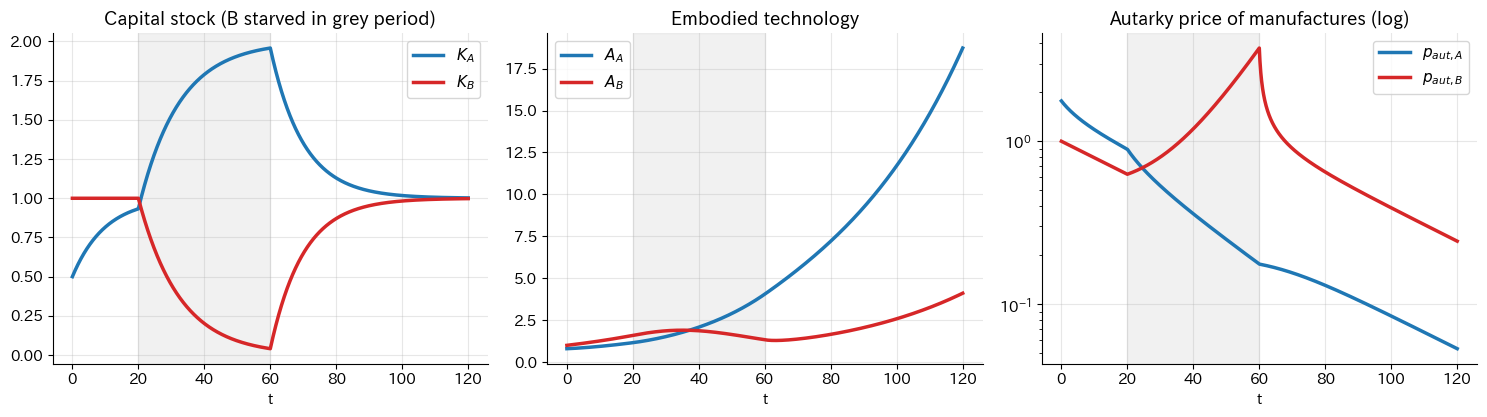

B の資本: t=20 で 1.000 → t=60 で 0.041;  技術: 1.594 → 1.331 → t=120 で 4.109
A の技術: t=20 で 1.159 → t=120 で 18.728


In [40]:
def stock_model(theta=0.2, d=0.10, Ibar=0.2, delta=0.08, mu=0.03, Kh=0.5, alpha=0.5, L=1.0,
                t0=20.0, t1=60.0, T=120.0, n=2401, K0=(0.5, 1.0), A0=(0.8, 1.0)):
    t = np.linspace(0, T, n); dt = t[1] - t[0]
    K = np.zeros((n, 2)); A = np.zeros((n, 2)); I = np.zeros((n, 2))
    K[0], A[0] = K0, A0
    for k in range(n - 1):
        if t0 <= t[k] < t1:
            IB = min(theta * d * K[k, 1], Ibar)       # B への供給を減耗の theta 倍に絞る
            IA = Ibar - IB                             # 残りは A へ
        else:
            IA = IB = Ibar / 2
        I[k] = (IA, IB)
        K[k + 1] = K[k] + dt * (np.array([IA, IB]) - d * K[k])
        A[k + 1] = A[k] * (1 + dt * (delta * K[k] / (K[k] + Kh) - mu))
    I[-1] = I[-2]
    p_aut = (1 / A) * (L / np.maximum(K, 1e-9)) ** (1 - alpha)
    return t, K, A, I, p_aut

t, K, A, I, p_aut = stock_model()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for j, (name, col) in enumerate([('A', C['home']), ('B', C['foreign'])]):
    axes[0].plot(t, K[:, j], color=col, lw=2.5, label=f'$K_{name}$')
    axes[1].plot(t, A[:, j], color=col, lw=2.5, label=f'$A_{name}$')
    axes[2].semilogy(t, p_aut[:, j], color=col, lw=2.5, label=f'$p_{{aut,{name}}}$')
for ax in axes:
    ax.axvspan(20, 60, color=C['gray'], alpha=0.1)
    ax.set_xlabel('t'); ax.legend()
axes[0].set_title('Capital stock (B starved in grey period)')
axes[1].set_title('Embodied technology')
axes[2].set_title('Autarky price of manufactures (log)')
plt.tight_layout(); plt.show()
print(f'B の資本: t=20 で {K[400,1]:.3f} → t=60 で {K[1200,1]:.3f};  技術: {A[400,1]:.3f} → {A[1200,1]:.3f} → t=120 で {A[-1,1]:.3f}')
print(f'A の技術: t=20 で {A[400,0]:.3f} → t=120 で {A[-1,0]:.3f}')

灰色の期間に B の資本は幾何級数的に縮み（定理 11.1）、それに体化された技術も陳腐化して下がります。その間に A は資本を得て技術を伸ばし、B を追い抜きます。供給を元に戻すと B の技術は再び伸び始めますが、**A との差は開いたまま元に戻りません**（ヒステリシス）。供給国は、相手国の設備の**減耗を通じて**、比較優位を付け替えられるのです。

## 11.5 逆説：完全な禁輸は相手の「幼稚産業」を育てる

ただし、このてこには限界があります。B が自前で資本財を作り始めれば、X の供給に依存しなくなります。しかも第10章で見たように、資本財産業を育てるには**保護**が要りますが、X による禁輸は、**B の資本財産業にとって外から課された禁止的関税と同じ働きをします**。

そこで、B が「輸入が必要量の半分を下回ったら、国産の資本財生産を始める」という政策をもつ場合を考えます。B が国産化に振り向ける労働を $\ell_K$、国産資本財の生産性（1 人あたり年産）を $Z_B$ とし、$Z_B$ は作ることで学習される（$\dot Z_B = \eta Z_B \ell_K (1 - Z_B/\bar Z)$；$\eta$ は学習の速さ、$\bar Z$ は到達しうる上限）とします。X の二つの戦略を比べます。

* **部分的な締め付け**：減耗の 60% だけ供給し続ける（B は国産化に踏み切らない）。
* **完全禁輸**：供給をゼロにする（B は国産化に踏み切る）。

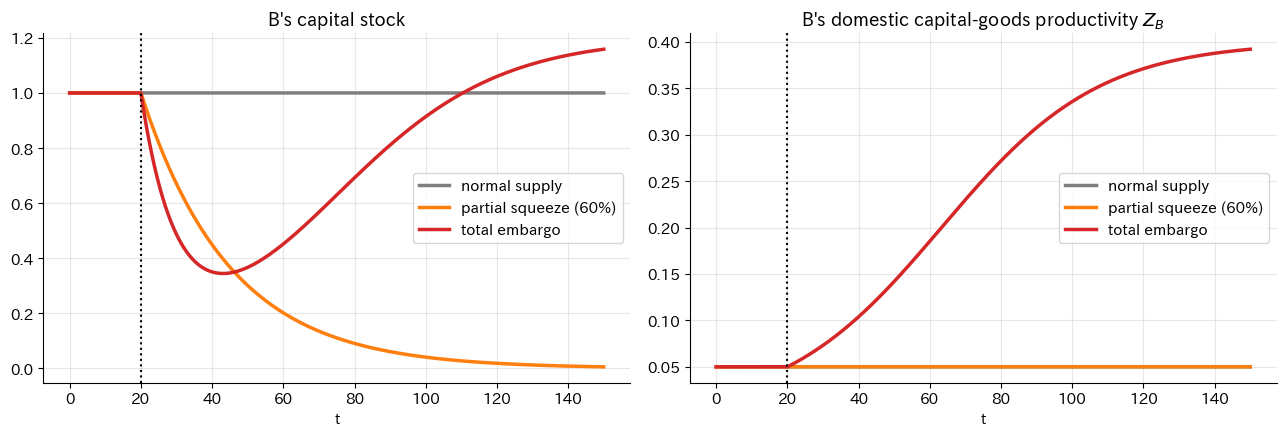

In [41]:
def embargo_model(supply_frac, d=0.10, Kstar=1.0, lK=0.3, eta=0.15, Z0=0.05, Zbar=0.4,
                  t0=20.0, T=150.0, n=3001, trigger=0.5):
    t = np.linspace(0, T, n); dt = t[1] - t[0]
    K = np.zeros(n); Z = np.zeros(n); dom = np.zeros(n)
    K[0], Z[0] = Kstar, Z0
    for k in range(n - 1):
        need = d * K[k]                                  # いまの資本を維持するのに必要な更新投資
        imp = d * Kstar if t[k] < t0 else supply_frac * need
        program = imp < trigger * need                   # 輸入が必要量の半分未満なら国産化
        dom[k] = Z[k] * lK if program else 0.0
        K[k + 1] = K[k] + dt * (imp + dom[k] - d * K[k])
        Z[k + 1] = Z[k] + dt * (eta * Z[k] * (lK if program else 0.0) * (1 - Z[k] / Zbar))
    dom[-1] = dom[-2]
    return t, K, Z, dom

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for frac, col, lab in [(1.0, C['gray'], 'normal supply'), (0.6, C['orange'], 'partial squeeze (60%)'),
                       (0.0, C['foreign'], 'total embargo')]:
    t, K, Z, dom = embargo_model(frac)
    axes[0].plot(t, K, color=col, lw=2.5, label=lab)
    axes[1].plot(t, Z, color=col, lw=2.5, label=lab)
axes[0].set_title("B's capital stock"); axes[1].set_title("B's domestic capital-goods productivity $Z_B$")
for ax in axes:
    ax.axvline(20, color='k', ls=':'); ax.set_xlabel('t'); ax.legend()
plt.tight_layout(); plt.show()

* **部分的な締め付け**のもとでは、B は（いまの必要量の 60% は届いているので）国産化に踏み切らず、資本は少しずつ、しかし確実にゼロへ向かって縮みます（定理 11.1 の $\theta = 0.6$ の場合）。依存は続き、X のてこは保たれます。いわば「ゆでガエル」です。
* **完全禁輸**のもとでは、B の資本は一時的に急減しますが、国産化の学習が進み、やがて X に頼らずに資本を維持・回復します。X はてこを失います。

これは「禁輸は相手国の自立を促す」という、半導体規制などをめぐって現実にも議論されている逆説の、最も単純な定式化です。JRF の (M0)(M2) を合わせると、**資本財の供給国がもつ「優位」もまた、過去の設備と技術に依存した優位であり、相手が資本財そのものを作る力を身につければ、くつがえされうる**ことになります。供給国にとって合理的なのは、相手を完全に締め出すことではなく、**依存を保ったまま、更新の速度を制御すること**かもしれません ― 次章では、供給国 X の側の損得を考えます。

---
# 12. 供給国 X は何を得るのか ― 戦略の費用と便益

## 12.1 X の動機（会話での整理）

JRF は「X 自身も経済に参加しているわけですが、そこはそういうスイッチングをすることで何を得るのでしょう？」と問いました。Gemini さんは三つの動機を挙げました。

1. **自立化（キャッチアップ）の阻止と、技術レントの永続化**：途上国が自立化の閾値を越えると、X は資本財の顧客を失い、将来の競争相手を生む。閾値の手前で供給を付け替えれば、どの国にも閾値を越えさせずに、独占的供給者の地位（特許料・技術ライセンス料を含む）を保てる。
2. **安全保障・競争コストの排除**：X の厚生を $W_X = \pi_K(K_A, K_B) + U_X(C_X) - \Phi(A_{M,B})$ と書き（$\pi_K$ は資本財の販売による利潤、$U_X(C_X)$ は X の消費 $C_X$ から得る効用）、$\Phi$（B の技術向上による脅威の不効用、$\Phi' > 0$）が大きくなれば、売上を犠牲にしても B を抑えるのが合理的になる。
3. **ハブ・アンド・スポーク型の交易条件の操作**：供給先を付け替える（あるいはそう脅す）ことで、途上国同士を競わせ、X に有利な条件を引き出せる。B だけが巨大な製造業の拠点になると、逆に B が買い手として交渉力をもってしまう。

これらは、割引率 $\rho$ のもとでの次の動的最適化問題にまとめられます。
$$
\max_{\{s(t)\}} \int_0^\infty e^{-\rho t}\Big[\pi_K\big(s(t)\bar K\big) - \Phi\big(A_{M,B}(t)\big)\Big]dt .
$$
Gemini さんは、現代の半導体輸出規制やフレンド・ショアリング（信頼できる国だけに供給網を寄せる政策）を、この数理構造の現実の例として挙げました。

## 12.2 なぜ X は微分方程式に入っていないのか

JRF は、第11章のコードの `system_ode` に X 自身が入っていないことを問いました。Gemini さんの答えは、動学モデルにおける役割分担の説明として的確です。

| 役割 | 何か | 第11章のモデルでは |
|---|---|---|
| **状態変数** | 時間とともに蓄積・変化し、微分方程式で解かれる量 | A と B の生産性 $A_{M,A}, A_{M,B}$ |
| **制御変数・外生変数** | 外から与えられる入力 | X の配分 $s(t)$、供給能力 $\bar K$、世界価格 $p^{\ast}$ |
| **評価関数** | 解の結果を受け取って計算する目的関数 | X の厚生 $W_X$ |

X の技術水準は、モデルを簡単にするために一定（外生）とされていました（Gemini さんの言う「オッカムの剃刀」）。X 自身も研究開発で成長するなら、状態変数に $A_{M,X}$ を加えます。

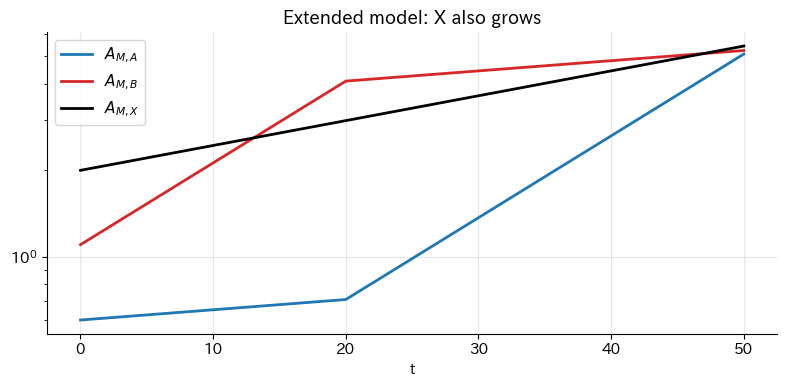

In [42]:
# 会話で示された拡張の形（状態変数に X 自身を加える）
def s_func_ext(t, p):
    return p['s_before'] if t < p['t_switch'] else p['s_after']

def system_ode_extended(t, y, p):
    A_MA, A_MB, A_MX = y
    s = s_func_ext(t, p)
    dA_MA = p['delta'] * A_MA * (s * p['K_bar']) ** p['gamma']          # X からの資本財に依存
    dA_MB = p['delta'] * A_MB * ((1 - s) * p['K_bar']) ** p['gamma']
    dA_MX = p['delta_X'] * A_MX * p['RD_investment']                      # X 自身の R&D
    return [dA_MA, dA_MB, dA_MX]

p_ext = dict(params, delta_X=0.05, RD_investment=0.4)
sol = solve_ivp(system_ode_extended, (0, 50), [0.6, 1.1, 2.0], args=(p_ext,), max_step=0.1,
                t_eval=np.linspace(0, 50, 501))
plt.figure(figsize=(8, 4))
for j, (nm, col) in enumerate([('A', C['home']), ('B', C['foreign']), ('X', 'k')]):
    plt.plot(sol.t, sol.y[j], color=col, lw=2, label=f'$A_{{M,{nm}}}$')
plt.yscale('log'); plt.xlabel('t'); plt.title('Extended model: X also grows'); plt.legend()
plt.tight_layout(); plt.show()

## 12.3 戦略比較 ― 会話で示されたモデルとその検算

JRF は「戦略にコストがかかっていれば、長期的にほんとに有利なのかわかりません。X A B が貿易にちゃんと参加しているモデルで、X の戦略を比較する Python コードとかできませんか？」と続けました。Gemini さんは X が払う費用として、(1) 資本財をより多く買ってくれる B への輸出を制限する機会費用、(2) 効率的な B の成長を止めることによる輸入品の値上がり（交易条件の悪化）、(3) 規制の実施・監視の費用、の三つを挙げ、X の毎期の厚生を
$$
W_X(t) = \underbrace{\mathrm{Rev}_K(t)}_{\text{資本財売上}} + \underbrace{\mathrm{TradeGain}(t)}_{\text{輸入による利得}} - \underbrace{\lambda\max(0, A_{M,B}-A_{\mathrm{thresh}})^2}_{\text{B の台頭の脅威}} - \underbrace{\eta\,(s-0.5)^2}_{\text{規制・歪曲コスト}}
$$
として（$A_{\mathrm{thresh}} = A_A/p^{\ast}$ は自立化の閾値、$\eta$ は規制コストの係数で 11.5 節の $\eta$ とは別）、戦略1（自由貿易 $s = 0.5$）と戦略2（$t_0$ 以降 $s = 0.85$）を割引現在価値（NPV）で比べるコードを示しました。

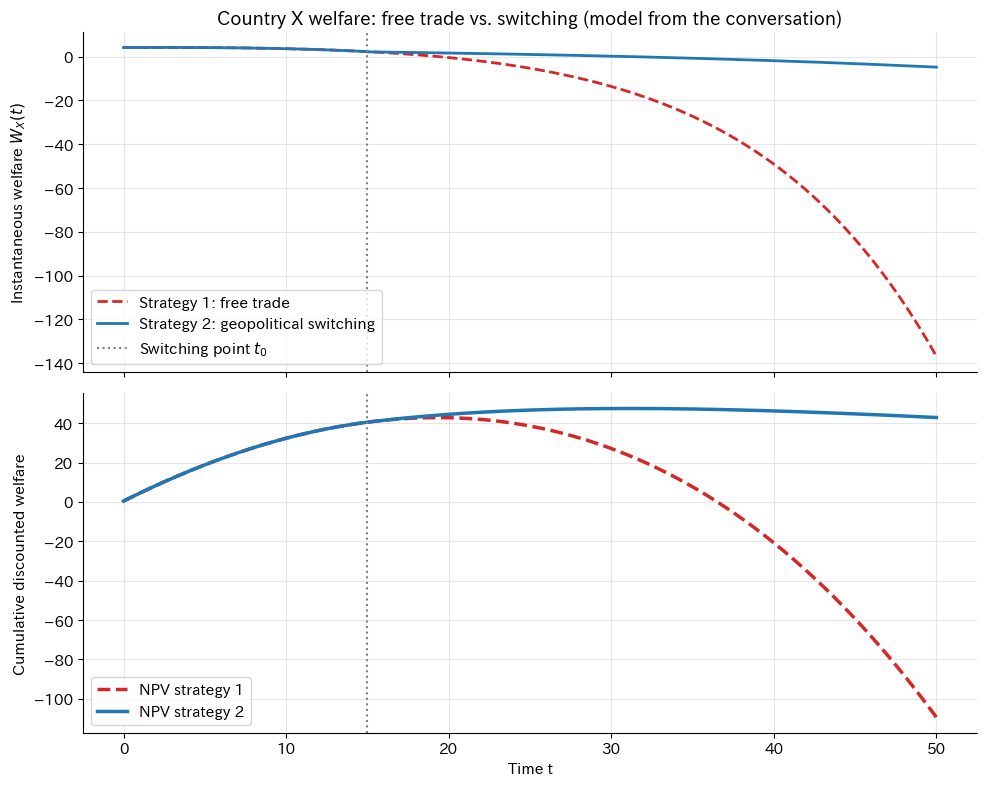

NPV の大小が入れ替わる時刻: [14.93 15.63]
資本財売上 Rev_K の値（戦略1）: [3.]  （戦略2）: [3.]
t=0 での B の技術 1.00（閾値 1.0）


In [43]:
# 会話で示されたコード（3国間貿易・地政学的戦略費用対効果モデル）
gparams = {
    'A_A': 1.0, 'p_star': 1.0, 'K_bar': 2.0, 'P_K': 1.5, 'delta': 0.08, 'gamma': 1.0,
    'L_M': 1.0, 't_switch': 15.0, 'r': 0.05, 'lambda_threat': 3.5, 'eta_cost': 0.8, 'omega_trade': 1.2}
A_thr_g = gparams['A_A'] / gparams['p_star']

def s_strategy_1(t):
    return 0.5

def s_strategy_2(t, t_switch):
    return 0.5 if t < t_switch else 0.85

def system_ode_g(t, y, strategy_type, p):
    A_MA, A_MB = y
    s = s_strategy_1(t) if strategy_type == 1 else s_strategy_2(t, p['t_switch'])
    K_A, K_B = s * p['K_bar'], (1.0 - s) * p['K_bar']
    return [p['delta'] * A_MA * p['L_M'] * (K_A / p['K_bar']) ** p['gamma'],
            p['delta'] * A_MB * p['L_M'] * (K_B / p['K_bar']) ** p['gamma']]

def evaluate_welfare(t_vec, sol, strategy_type, p):
    A_MA, A_MB = sol.y
    s_vec = np.array([s_strategy_1(t) if strategy_type == 1 else s_strategy_2(t, p['t_switch'])
                      for t in t_vec])
    K_A, K_B = s_vec * p['K_bar'], (1.0 - s_vec) * p['K_bar']
    rev_K = p['P_K'] * (K_A + K_B)
    trade_gain = p['omega_trade'] * np.log(1.0 + A_MA + A_MB)
    threat = p['lambda_threat'] * np.maximum(0.0, A_MB - A_thr_g) ** 2
    enforce_cost = p['eta_cost'] * (s_vec - 0.5) ** 2
    W_X = rev_K + trade_gain - threat - enforce_cost
    npv = np.cumsum(W_X * np.exp(-p['r'] * t_vec) * (t_vec[1] - t_vec[0]))
    return W_X, npv, dict(rev=rev_K, trade=trade_gain, threat=threat, enforce=enforce_cost)

t_eval = np.linspace(0.0, 50.0, 500)
y0 = [0.6, 1.0]
sol1 = solve_ivp(system_ode_g, (0, 50), y0, args=(1, gparams), t_eval=t_eval, max_step=0.1)
sol2 = solve_ivp(system_ode_g, (0, 50), y0, args=(2, gparams), t_eval=t_eval, max_step=0.1)
W_X1, npv1, parts1 = evaluate_welfare(t_eval, sol1, 1, gparams)
W_X2, npv2, parts2 = evaluate_welfare(t_eval, sol2, 2, gparams)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax1.plot(t_eval, W_X1, '--', color=C['foreign'], lw=2, label='Strategy 1: free trade')
ax1.plot(t_eval, W_X2, color=C['home'], lw=2, label='Strategy 2: geopolitical switching')
ax1.axvline(gparams['t_switch'], color=C['gray'], ls=':', label='Switching point $t_0$')
ax1.set_ylabel('Instantaneous welfare $W_X(t)$'); ax1.legend(loc='lower left')
ax1.set_title('Country X welfare: free trade vs. switching (model from the conversation)', fontweight='bold')
ax2.plot(t_eval, npv1, '--', color=C['foreign'], lw=2.5, label='NPV strategy 1')
ax2.plot(t_eval, npv2, color=C['home'], lw=2.5, label='NPV strategy 2')
ax2.axvline(gparams['t_switch'], color=C['gray'], ls=':')
ax2.set_xlabel('Time t'); ax2.set_ylabel('Cumulative discounted welfare'); ax2.legend(loc='lower left')
plt.tight_layout(); plt.show()

cross = t_eval[np.where(np.diff(np.sign(npv2 - npv1)) != 0)[0]]
print('NPV の大小が入れ替わる時刻:', np.round(cross, 2))
print('資本財売上 Rev_K の値（戦略1）:', np.unique(parts1['rev']), ' （戦略2）:', np.unique(parts2['rev']))
print(f"t=0 での B の技術 {sol1.y[1][0]:.2f}（閾値 {A_thr_g}）")

### 検算と批判

会話では「NPV の曲線が $t \approx 32$ で戦略1を追い抜く」と説明されましたが、実際に計算すると、戦略2は切り替えの直後（$t \approx 15$）から上回ります。B が最初から閾値ちょうど（$A_{M,B}(0) = 1.0$）にいるので、自由貿易のもとでは脅威コストが最初から増え始めるからです。

それ以上に重要なのは、**このモデルでは資本財の売上 $\mathrm{Rev}_K = P_K (K_A + K_B) = P_K \bar K$ が戦略によらず一定**だという点です（上の出力）。Gemini さんが説明で挙げた「より多く買ってくれる国 B への輸出を制限することによる売上の減少」という機会費用は、式に入っていません。戦略の費用は規制コスト $\eta(s-0.5)^2$ と、輸入利得の小さな差だけです。これでは「戦略にコストがかかっていても有利か」という JRF の問いには、まだ答えられていません。

さらに JRF は次の点を指摘しました。

> X の成長を考えないと B だけでなく A も成長するため、やがて厚生が下がっていくことになりますよね…。すると、自由貿易をはなからしないという選択肢も出てくる。

B を抑えるために A を育てれば、今度は A が閾値を越えて脅威になる ― Gemini さんの言う**キャッチアップのジレンマ**です。会話のモデルでは脅威が B についてしか数えられていないので、このジレンマが見えません。

## 12.4 改良版モデル

以上を踏まえて、次のように作り直します（あくまで構造を見るための玩具モデルです）。

* **状態**：A, B の X に対する相対技術 $a_i = A_{M,i}/A_{M,X}$。X は率 $g_X$ で成長する。
$$
\dot a_i = a_i\Big[\delta\,\sigma_i^{\gamma}\big(1 - a_i/\bar a\big) - g_X\Big]
$$
$\sigma_i$ は X の資本財供給のうち $i$ に向かう割合（禁輸なら 0）、$\delta, \gamma$ は第11章と同じ学習の係数、$\bar a$ は相対技術の上限。供給がなければ相対技術は率 $g_X$ で低下する。
* **X の毎期の利得**（X の規模で基準化）：
  * 資本財の売上 $\pi_0 \sum_i \sigma_i^{\eta} a_i^{\varepsilon}$（$\pi_0$ は規模の係数、$\eta, \varepsilon$ は 0 と 1 の間の指数）。$\eta < 1$ なので一国に偏らせると売上が減る（**機会費用**）。技術の高い顧客ほど多く高く買う。
  * 消費財の輸入利得 $\omega \ln(1 + a_A + a_B)$（$\omega$ はその重み。第6章の相対賃金 $\omega$ とは別）。相手が効率的になるほど安く輸入できる（交易条件）。貿易をしなければ 0。
  * 規制コスト $c_E \times$（制限している相手国の数）。$c_E$ は 1 か国あたりの規制の費用。
  * 脅威 $\lambda \sum_i \theta_i \max(0, a_i - a_{\mathrm{thr}})^2$（$a_{\mathrm{thr}}$ は X が脅威を感じ始める相対技術の水準）。$\theta_i$ は相手国 $i$ の脅威の重みで、**同盟国なら小さい**。
* **戦略**：

| 記号 | 戦略 | $t \ge t_0$ での $(\sigma_A, \sigma_B)$ |
|---|---|---|
| FT | 自由貿易 | (0.5, 0.5) |
| SW | 会話のスイッチング | (0.85, 0.15) |
| CB | B の完全封じ込め（フレンド・ショアリング） | (1, 0) |
| RO | ローテーション（遅れている側に厚く供給） | 遅れている側に 0.85 |
| AU | はなから貿易しない（$t=0$ から） | (0, 0)、輸入利得もなし |

NPV は $\lambda$ について線形 ― $\mathrm{NPV}_j(\lambda) = B_j - \lambda T_j$ ― なので、動学を一度解けば、どんな $\lambda$ と割引率 $r$ についても最適な戦略がすぐ求まります。

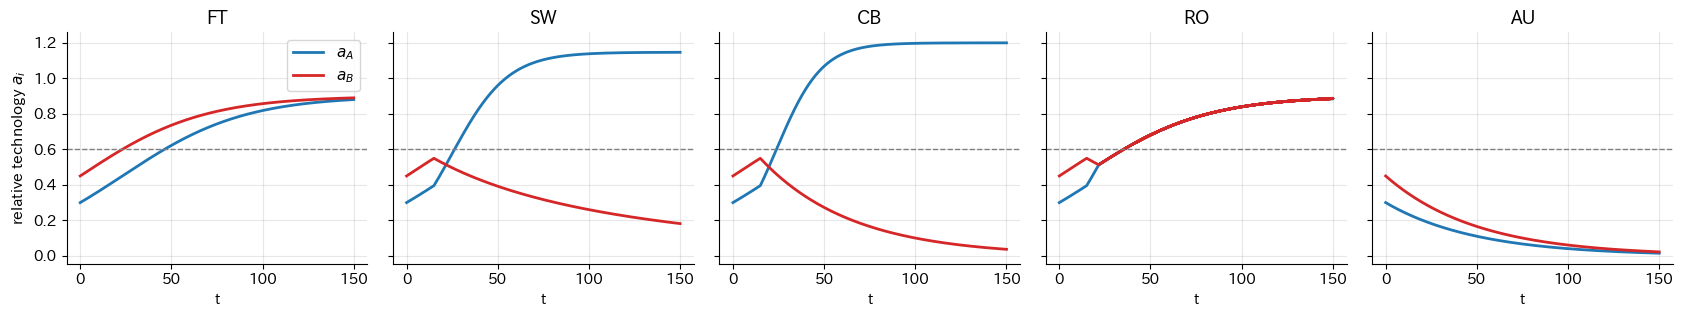

In [44]:
TOY = dict(delta=0.10, gamma=1.0, gX=0.02, acap=1.5, thr=0.6, pi0=1.0, eta=0.5, eps=0.5,
           omega=1.0, cE=0.15, t0=15.0, T=150.0)
A0_TOY = (0.3, 0.45)
STRATS = ['FT', 'SW', 'CB', 'RO', 'AU']

def toy_sigma(strat, t, a, P=TOY):
    if strat == 'AU':
        return (0.0, 0.0)
    if t < P['t0'] or strat == 'FT':
        return (0.5, 0.5)
    if strat == 'SW':
        return (0.85, 0.15)
    if strat == 'CB':
        return (1.0, 0.0)
    if strat == 'RO':
        return (0.85, 0.15) if a[0] <= a[1] else (0.15, 0.85)

def toy_run(strat, P=TOY, n=3001):
    t = np.linspace(0, P['T'], n); dt = t[1] - t[0]
    a = np.array(A0_TOY, float); A = np.zeros((n, 2)); S = np.zeros((n, 2))
    for k in range(n):
        s = np.array(toy_sigma(strat, t[k], a, P)); A[k], S[k] = a, s
        a = a + dt * a * (P['delta'] * s ** P['gamma'] * (1 - a / P['acap']) - P['gX'])
    return t, A, S

def toy_components(strat, thetaA, P=TOY):
    """返り値: t, 便益の流列 b(t)（脅威を除く）, 脅威の流列 h(t)（λ を掛ける前）, 相対技術 A"""
    t, A, S = toy_run(strat, P)
    rev = P['pi0'] * np.sum(S ** P['eta'] * A ** P['eps'], axis=1)
    trade = 0.0 * t if strat == 'AU' else P['omega'] * np.log(1 + A.sum(axis=1))
    if strat == 'AU':
        restricted = np.full_like(t, 2.0)
    elif strat == 'FT':
        restricted = np.zeros_like(t)
    else:
        restricted = (t >= P['t0']).astype(float)
    benefit = rev + trade - P['cE'] * restricted
    threat = thetaA * np.maximum(0, A[:, 0] - P['thr']) ** 2 + np.maximum(0, A[:, 1] - P['thr']) ** 2
    return t, benefit, threat, A

fig, axes = plt.subplots(1, 5, figsize=(17, 3.3), sharey=True)
for ax, st in zip(axes, STRATS):
    t, b, h, A = toy_components(st, 1.0)
    ax.plot(t, A[:, 0], color=C['home'], lw=2, label='$a_A$')
    ax.plot(t, A[:, 1], color=C['foreign'], lw=2, label='$a_B$')
    ax.axhline(TOY['thr'], color=C['gray'], ls='--', lw=1); ax.set_title(st); ax.set_xlabel('t')
axes[0].set_ylabel('relative technology $a_i$'); axes[0].legend()
plt.tight_layout(); plt.show()

* **FT**：A も B も X に追いつき、ともに閾値（破線）を越える。
* **SW・CB**：B は抑えられるが、A は資本財を独占して閾値を大きく越える（キャッチアップのジレンマ）。
* **RO**：遅れた側に厚く供給するので、両国が交互に伸び、結局どちらも閾値を越える（ここでの単純なローテーションは封じ込めにならない）。
* **AU**：両国とも X から相対的に遅れ続ける。脅威はないが、売上も輸入利得もない。

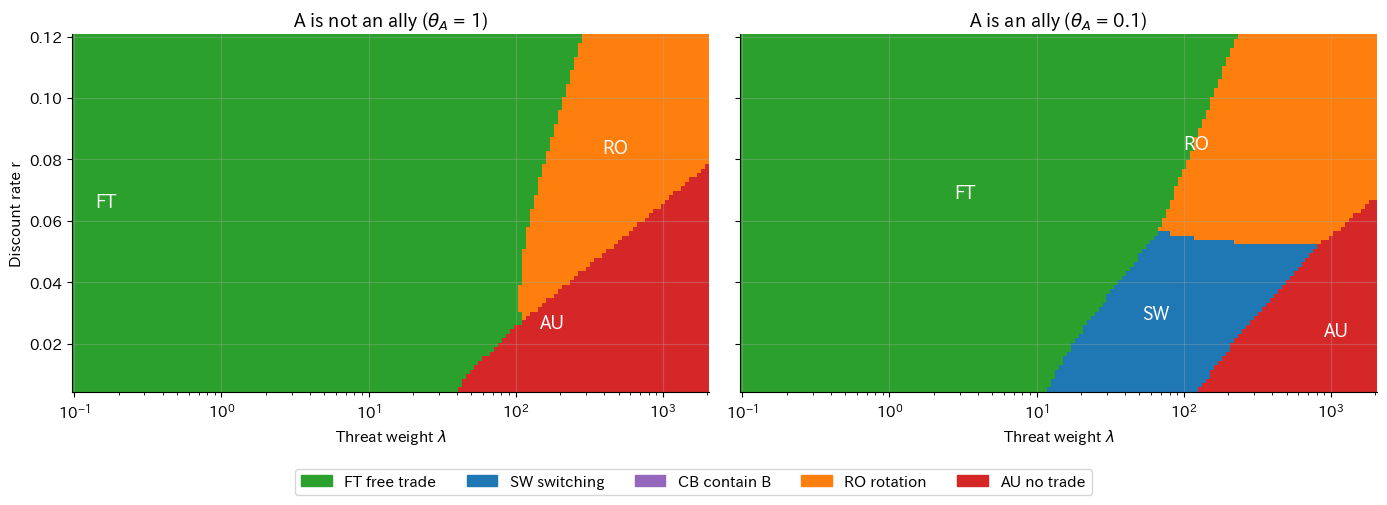

In [45]:
def best_strategy_map(thetaA, lams, rs, P=TOY):
    comps = {st: toy_components(st, thetaA, P) for st in STRATS}
    Bv = {st: np.array([trapezoid(np.exp(-r * c[0]) * c[1], c[0]) for r in rs]) for st, c in comps.items()}
    Tv = {st: np.array([trapezoid(np.exp(-r * c[0]) * c[2], c[0]) for r in rs]) for st, c in comps.items()}
    best = np.zeros((len(rs), len(lams)), int)
    for i in range(len(rs)):
        vals = np.array([[Bv[st][i] - lam * Tv[st][i] for st in STRATS] for lam in lams])
        best[i] = vals.argmax(axis=1)
    return best

from matplotlib.colors import ListedColormap
lams = np.logspace(-1, 3.3, 160)
rs = np.linspace(0.005, 0.12, 80)
cmap = ListedColormap([C['third'], C['home'], C['purple'], C['orange'], C['foreign']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, thetaA, title in [(axes[0], 1.0, r'A is not an ally ($\theta_A$ = 1)'),
                          (axes[1], 0.1, r'A is an ally ($\theta_A$ = 0.1)')]:
    best = best_strategy_map(thetaA, lams, rs)
    ax.pcolormesh(lams, rs, best, cmap=cmap, vmin=-0.5, vmax=4.5, shading='auto')
    ax.set_xscale('log'); ax.set_xlabel(r'Threat weight $\lambda$'); ax.set_title(title)
    for k, st in enumerate(STRATS):
        cells = np.argwhere(best == k)
        if len(cells):
            ii, jj = cells[len(cells) // 2]
            ax.text(lams[jj], rs[ii], st, ha='center', va='center', fontsize=13, fontweight='bold', color='white')
axes[0].set_ylabel('Discount rate r')
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(k)) for k in range(5)]
fig.legend(handles, ['FT free trade', 'SW switching', 'CB contain B', 'RO rotation', 'AU no trade'],
           loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

この玩具モデルから読み取れる構造は次のとおりです。

1. **$\lambda$ が小さければ自由貿易（FT）、極端に大きければ「はなから貿易しない」（AU）。** 中間の領域で何が最適かは、A が同盟国かどうかで決定的に変わります。
2. **A が同盟国でない（$\theta_A = 1$）なら、スイッチングは最適にならない。** B を抑えても A が脅威になるからです（キャッチアップのジレンマ）。割引率が高い（近視眼的な）ときにだけ、時間稼ぎとしてのローテーション（RO）が選ばれます。
3. **A が同盟国（$\theta_A$ が小さい）なら、中間の $\lambda$ でスイッチング（SW）が最適になる。** 会話で示された「損して得取れ」の構造は、**同盟という制度があって初めて**成り立つのです。
4. **割引率が高いと自由貿易の領域が広がる。** 脅威は遠い将来に来るので、近視眼的な国ほど目先の貿易利得を取ります。

（完全封じ込め CB は、この設定では売上の機会費用が大きすぎて、どの領域でも最適になりませんでした。パラメータを変えれば現れます。）

最後に、「$\lambda$ が閾値を越えるかどうかで最適戦略が切り替わり、自由貿易が最適な $\lambda$ の集合は下に閉じた区間になる」という性質は、NPV が $\lambda$ について線形であることから一般的に言えます。Lean で示しておきます。

In [46]:
%%writefile lean_src/ch12_strategy.lean
/-! ## 第12章 供給国 X の戦略選択の構造 -/
namespace StrategyChoice

/-- 戦略 `i` の割引現在価値が「脅威の重み `lam`」について線形 `B i - lam * T i` で書けるとき、
  スイッチング（戦略 s）が自由貿易（戦略 f）より良くなるのは `lam` が閾値を超えるとき、かつそのときに限る。 -/
theorem switching_threshold (Bf Bs Tf Ts lam : ℝ) (hT : Ts < Tf) :
    Bf - lam * Tf < Bs - lam * Ts ↔ (Bf - Bs) / (Tf - Ts) < lam := by
  have hpos : 0 < Tf - Ts := sub_pos.2 hT
  rw [div_lt_iff₀ hpos]
  constructor <;> intro h <;> nlinarith

/-- 脅威にさらされやすい戦略（`Tf > Ts`）が `lam` で最適なら、それより小さい `lam'` でも最適。
  すなわち「自由貿易が最適な `lam` の集合」は下に閉じた区間になる。 -/
theorem free_trade_region_downward (Bf Bs Tf Ts lam lam' : ℝ) (hT : Ts ≤ Tf)
    (hlam : lam' ≤ lam) (hopt : Bs - lam * Ts ≤ Bf - lam * Tf) :
    Bs - lam' * Ts ≤ Bf - lam' * Tf := by
  nlinarith [mul_le_mul_of_nonneg_right hlam (sub_nonneg.2 hT)]

end StrategyChoice

Overwriting lean_src/ch12_strategy.lean


## 12.5 なぜ現実には自由貿易が選ばれたのか ― 核抑止と $\lambda$

JRF はさらに問いました。

> 自由貿易をはなからしないという選択肢も出てくる。しかし、現実は自由貿易をした。それは lambda が低いと判断したから…核があるから…なのでしょうか。

Gemini さんは、この見方を支持して次のような歴史的説明を示しました（要約）。

* **核以前**（〜第二次大戦）：他国の経済・技術成長は直ちに軍事力の増強を意味し、$\lambda$ は事実上無限大。ブロック経済、植民地の囲い込み、技術の差し止めが主流だった。
* **核以後**：相互確証破壊（MAD）により、他国が経済的に追いついても自国が占領・滅亡させられる確率はほぼゼロになり、$\lambda$ に上限がはめられた。
* **同盟による無害化**：X（米国）は A（戦後の日本・西ドイツ・韓国など）を、安全保障の依存（核の傘）と金融・決済網（ドル）の中に組み込み、$\lambda_A \approx 0$ とした。1980 年代の日米貿易摩擦（1985 年のプラザ合意、1986 年の日米半導体協定）でも、この枠組みは機能した。
* **資本の論理**：資本輸出によって海外から利子・配当・使用料を回流させることは、X 内部の資本家・利子生活者の構造を維持するためにも必要だった。
* **現代の破綻**：B（中国）を世界貿易体制に引き入れた（2001 年の WTO 加盟）関与政策は、B も成長すれば西側の制度に組み込まれるという想定に立っていたが、B は核と独自の軍事力を保ったまま閾値を越え、独自の経済圏を作り、レアアースなどのチョークポイントを握り返した。$\lambda_B$ の過小評価が明らかになり、デカップリングやフレンド・ショアリングへの回帰が起きた。

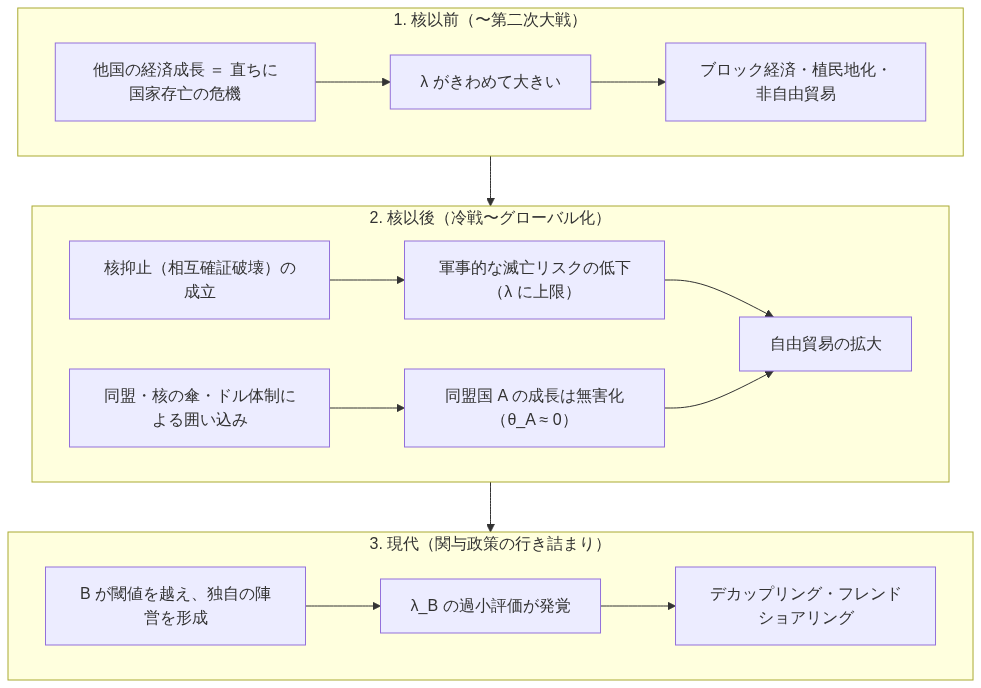

In [47]:
show_mermaid("""
graph TD
  subgraph P1 ["1. 核以前（〜第二次大戦）"]
    War1["他国の経済成長 ＝ 直ちに国家存亡の危機"] --> LambdaHigh["λ がきわめて大きい"]
    LambdaHigh --> Policy1["ブロック経済・植民地化・非自由貿易"]
  end
  subgraph P2 ["2. 核以後（冷戦〜グローバル化）"]
    Nuke["核抑止（相互確証破壊）の成立"] --> LambdaLow["軍事的な滅亡リスクの低下（λ に上限）"]
    Inst["同盟・核の傘・ドル体制による囲い込み"] --> ASafe["同盟国 A の成長は無害化（θ_A ≈ 0）"]
    LambdaLow --> Trade1["自由貿易の拡大"]
    ASafe --> Trade1
  end
  subgraph P3 ["3. 現代（関与政策の行き詰まり）"]
    Rise["B が閾値を越え、独自の陣営を形成"] --> Miss["λ_B の過小評価が発覚"]
    Miss --> Policy2["デカップリング・フレンドショアリング"]
  end
  P1 --> P2 --> P3
""")

（会話で示された mermaid の図は、ノードの文字列に括弧を含んでいたため、そのままでは描画できませんでした。ラベルを引用符で囲んで修正しています。）

この説明は、**検証された歴史学的結論ではなく、モデルの言葉で書かれた一つの仮説**として読むべきです。ただし、国際政治学には、この仮説と整合する理論と証拠があります。

* **相対的利得の問題**：グリエコ（Grieco 1988）は、国家は絶対的な利得だけでなく相手との相対的な利得を気にするので、協力が難しくなると論じた。パウエル（Powell 1991）は、相対的利得への関心の強さは**武力行使のコスト**に依存し、武力行使が高くつく世界ほど相対的利得への関心は弱まり、協力が容易になることをモデルで示した。核兵器は武力行使のコストを極端に高めるので、これは「核があるから $\lambda$ が低い」という JRF の推測の、理論的な裏付けといえます。核兵器が国際政治にもたらした変化については、ジャーヴィス（Jervis 1989）も参照。
* **同盟と貿易**：ゴワとマンスフィールド（Gowa & Mansfield 1993; Gowa 1994）は、貿易の利得が相手国の軍事力を強める「安全保障の外部性」があるため、国家は同盟国とより多く貿易することを示した。上の玩具モデルの $\theta_A$ はまさにこれです。
* **冷戦期は「選択的な」自由貿易だった**：西側内部では GATT のもとで自由化が進む一方、東側に対しては COCOM による輸出統制が行われた。つまり冷戦期の現実は「すべての相手に $\lambda$ が低かった」というより、「同盟国には $\theta \approx 0$、敵対国には高い $\theta$」という**封じ込め型（CB に近い）の大規模な実例**だったとも言えます。冷戦後に全方位の自由貿易（FT）へ移り、2010 年代後半以降に再び封じ込め型へ戻りつつある ― 玩具モデルの言葉では、このように整理できるかもしれません。

## 12.6 この章から JRF のメモへ

(M2) の「設備の生産によって相手の減耗をコントロールできる」力は、**それを行使する国にとっても費用がかかります**。売上の機会費用、輸入の利得の喪失、規制のコスト、そしてキャッチアップのジレンマです。その力を行使することが合理的かどうかは、脅威の評価 $\lambda$、割引率、そして**同盟という制度**によって決まります。比較優位の理論だけでは、どの国が何に特化するかは最終的には決まりません。**誰が誰に資本財を供給するかという力の配置**が、比較優位そのものを作り変えるのです。

---
# 13. 通貨高・資本取引と比較優位

JRF の 2011 年のメモの結論はこうでした。

> だから、「比較優位」のモデルを資本取引がからむような「通貨高」の議論などにつなげるのは、かなり慎重にやらないと間違う。

Gemini さんはこれを、「比較優位は実物取引（モノとモノの交換）かつ貿易収支均衡を前提にした静的な理論であり、資本収支（対外投資の利子・配当、国際的な資金流入）で通貨高が維持される局面にそのまま当てはめると、『製造業に比較劣位があるから通貨高で工場が潰れて輸入に頼るのが効率的だ』という論理のすり替えが起きる。実態は対外資産の収益で輸入をまかなう利子生活者化（オランダ病的な状態）である」と整理しました。

この章では、この主張を三つのモデルで裏付けます。

## 13.1 リカード自身の警告 ― 資本が動けば比較優位は消える

2.3 節で見たように、リカードは「資本が国境を越えて動くなら、ワインも毛織物もポルトガルで作られ、イングランドの資本と労働はポルトガルへ移るのが、イングランドの資本家と両国の消費者にとって有利だろう」と書いていました。比較優位論は、**資本が国際的に動かない**ことを前提にしていたのです。

これを最も簡単なモデルにします。

* リカードの技術（イングランド：毛織物 100 人、ワイン 120 人／ポルトガル：毛織物 90 人、ワイン 80 人）。
* 古典派の想定どおり、資本とは労働者に前払いする**賃金基金**であり、実質賃金は両国で同じ生存水準 $\bar w$。
* 資本家は、利潤率の高い国に資本を置く。

交易条件 $p$（毛織物のワイン建て価格）が両国の自給価格の帯 $[8/9, 6/5]$ にあるかぎり、労働者 1 人が 1 年に生む価値（ワイン建て）は、イングランド（毛織物 $1/100$ 単位）が $p/100 \le 0.012$、ポルトガル（ワイン $1/80$ 単位）が $0.0125$ で、**ポルトガルのほうがつねに大きい**（Lean の `portugal_more_productive`）。同じ賃金なら、ポルトガルで雇うほうが利潤が大きいのです。

 immobile capital: emp_E = 200, emp_P = 100, unemp_E = 20, unemp_P = 70, english_capital_abroad = 0
   mobile capital: emp_E = 130, emp_P = 170, unemp_E = 90, unemp_P = 0, english_capital_abroad = 70


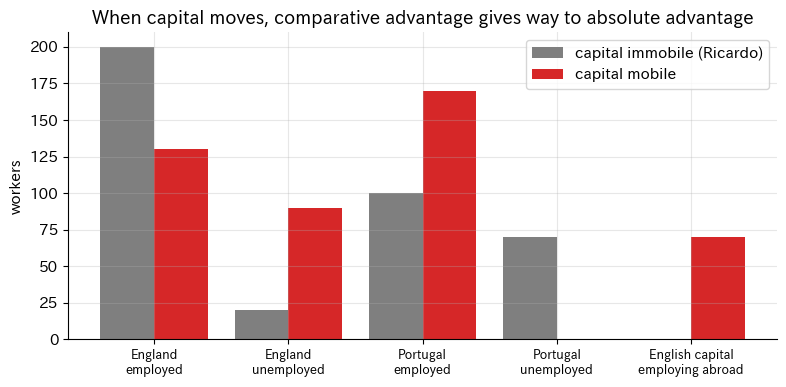

In [48]:
def capital_mobility(K_E, K_P, L_E=220, L_P=170, wbar=1.0, mobile=False):
    """賃金基金 K を前払いして労働者を雇う。mobile=True なら資本はまずポルトガルへ（利潤率が高い）。
    返り値: 各国の雇用・失業、イングランドの資本家がポルトガルで得る雇用（＝海外で利潤を得る資本）"""
    if not mobile:
        nE, nP = min(L_E, K_E / wbar), min(L_P, K_P / wbar)
        abroad = 0.0
    else:
        K = K_E + K_P
        nP = min(L_P, K / wbar)                  # まずポルトガルの労働を雇い尽くす
        nE = min(L_E, (K - nP * wbar) / wbar)    # 残りがイングランドへ
        abroad = max(0.0, nP * wbar - K_P) / wbar  # イングランド資本がポルトガルで雇う人数
    return dict(emp_E=nE, emp_P=nP, unemp_E=L_E - nE, unemp_P=L_P - nP, english_capital_abroad=abroad)

K_E, K_P = 200.0, 100.0          # 資本（賃金基金）が両国の労働を雇い尽くすには足りない世界
rows = {'immobile capital': capital_mobility(K_E, K_P), 'mobile capital': capital_mobility(K_E, K_P, mobile=True)}
for k, v in rows.items():
    print(f"{k:>17}: " + ', '.join(f'{a} = {b:.0f}' for a, b in v.items()))

fig, ax = plt.subplots(figsize=(8, 4))
labels = ['England\nemployed', 'England\nunemployed', 'Portugal\nemployed', 'Portugal\nunemployed', 'English capital\nemploying abroad']
keys = ['emp_E', 'unemp_E', 'emp_P', 'unemp_P', 'english_capital_abroad']
x = np.arange(len(keys))
ax.bar(x - 0.2, [rows['immobile capital'][k] for k in keys], 0.4, color=C['gray'], label='capital immobile (Ricardo)')
ax.bar(x + 0.2, [rows['mobile capital'][k] for k in keys], 0.4, color=C['foreign'], label='capital mobile')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9); ax.set_ylabel('workers'); ax.legend()
ax.set_title('When capital moves, comparative advantage gives way to absolute advantage')
plt.tight_layout(); plt.show()

資本が動かないとき、各国の資本はそれぞれ自国の労働者を雇い、両国が比較優位に従って特化します。資本が動くと、資本はまずポルトガルの労働を雇い尽くし、残りだけがイングランドに残ります。その結果、

* **イングランドの労働者の失業が増える**（ポルトガルへ移住しない限り）。
* **イングランドの資本家は、ポルトガルで利潤を得る**。彼らは本国では働かず、外国からの利潤で暮らす ― まさに**利子生活者**（不在資本家）です。

JRF の (M1)「リカードの比較優位における『失業者』は『利子生活者』という意味に近い」と (M3)「資本取引がからむ議論につなげるのは慎重に」は、ここで一つにつながります。**資本が動く世界では、比較優位ではなく絶対優位が生産の場所を決め、優位をもたない国には「失業者」と「海外からの利潤で暮らす者」が同時に生まれる。** そしてリカードは、まさにこの帰結を避けるものとして、資本の国際的な不動性（と、人々の祖国への愛着）を挙げていたのです。

## 13.2 経常収支の恒等式 ― 利子生活者国は貿易赤字になる

国際収支の恒等式（資本移転などを省略した簡略形）は
$$
\text{経常収支 } CA = \text{貿易収支 } TB + \text{第一次所得収支 } PI
$$
です。$PI$ は海外資産からの利子・配当などです。経常収支が均衡（$CA = 0$）していても、$PI > 0$ なら必ず $TB < 0$（貿易赤字）になります。対外純資産 $NFA$ の利回りを $i$ とすれば $-TB = i \cdot NFA$ です。

これは恒等式にすぎませんが、比較優位の議論にとっては重要です。比較優位のモデルは**貿易収支の均衡**（輸出＝輸入）を前提にしています。海外からの利子で輸入をまかなう国では、輸出が輸入より少なくて済むので、その分だけ輸出産業は小さくてよく、**それを可能にする水準まで通貨（賃金）が高くなります**。

In [49]:
%%writefile lean_src/ch13_currency.lean
/-! ## 第13章 経常収支の恒等式と「利子生活者国」 -/
namespace BalanceOfPayments

/-- 経常収支 = 貿易収支 + 第一次所得収支（簡略化）。経常収支が均衡していても、
  海外からの利子・配当（第一次所得）が正なら、貿易収支は必ず赤字になる。 -/
theorem rentier_trade_deficit (CA TB PI : ℝ) (hid : CA = TB + PI) (hCA : CA = 0)
    (hPI : 0 < PI) : TB < 0 := by
  linarith

/-- 対外純資産 `NFA` の利回り `i` が正で、経常収支が均衡するなら、貿易赤字の大きさは `i * NFA`。 -/
theorem deficit_equals_interest (TB i NFA : ℝ) (hid : 0 = TB + i * NFA) : -TB = i * NFA := by
  linarith

end BalanceOfPayments

namespace CapitalMobility

/-- リカードの数値で、交易条件 `p`（毛織物 1 単位のワイン建て価格）が両国の自給価格の帯
  `8/9 ≤ p ≤ 6/5` にあるかぎり、労働者 1 人が 1 年に生む価値（ワイン建て）は
  ポルトガル（ワイン 1/80）のほうがイングランド（毛織物 1/100）より大きい。
  実質賃金が同じなら、資本はポルトガルで高い利潤を得るので、資本が自由に動けばポルトガルへ向かう。 -/
theorem portugal_more_productive (p : ℝ) (hp : p ≤ 6 / 5) : p * (1 / 100) < 1 / 80 := by
  linarith

end CapitalMobility

Overwriting lean_src/ch13_currency.lean


## 13.3 DFS モデルに利子収入を入れる ― 「通貨高による空洞化」の正体

第6章の DFS モデルに、二つの要素を加えます（Dornbusch, Fischer & Samuelson 1977 の第 III 節の拡張に沿ったもの）。

1. **輸送費**（氷塊型：財を 1 単位届けるには $g > 1$ 単位を送る必要がある）。これにより、どちらの国でも作られ、貿易されない財（**非貿易財**）の範囲が生まれる。
2. **所得移転** $T$：外国から自国へ、毎期 $T$ の利子・配当が支払われる（自国は対外純資産をもつ利子生活者国）。

自国の賃金 $w$、外国の賃金 $w^{\ast} = 1$、$\omega = w/w^{\ast}$ とすると：

* 自国が**輸出する**財：$A(z) \ge \omega g$ を満たす $z \le z_x(\omega)$
* 自国が**自国向けに作る**財：$A(z) \ge \omega/g$ を満たす $z \le z_h(\omega)$（$z_h > z_x$）
* 自国の所得は $\omega L + T$、外国の所得は $L^{\ast} - T$。支出割合は一様（$b(z) = 1$）。

自国の労働所得は、自国の財への世界の支出に等しい：
$$
\omega L = z_h(\omega)\,(\omega L + T) + z_x(\omega)\,(L^{\ast} - T).
$$

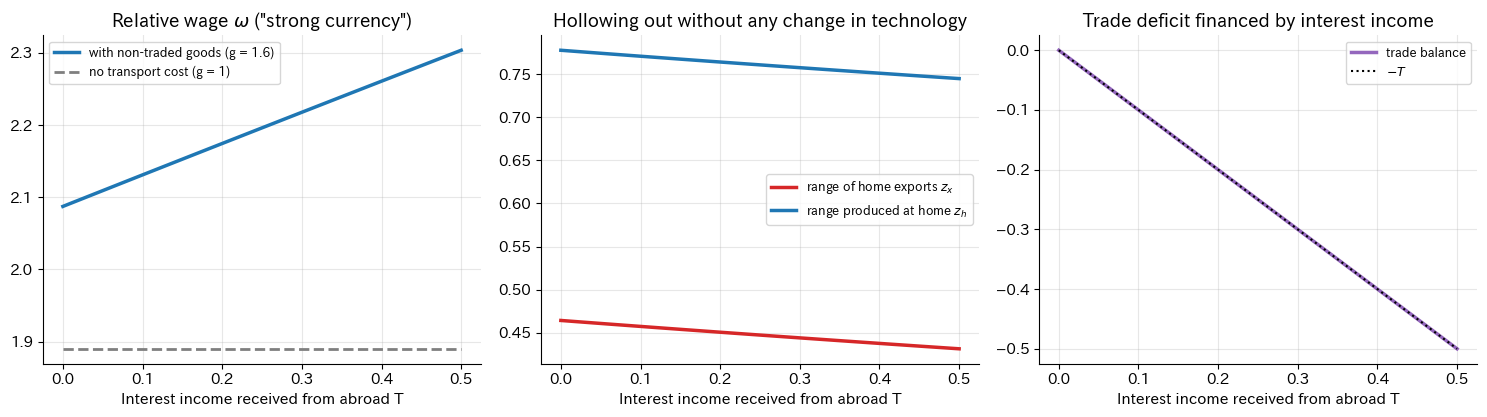

T = 0.00: ω = 2.087, 輸出財の範囲 z_x = 0.464, 自国生産の範囲 z_h = 0.778, 貿易収支 = -0.000
T = 0.25: ω = 2.196, 輸出財の範囲 z_x = 0.447, 自国生産の範囲 z_h = 0.761, 貿易収支 = -0.250
T = 0.50: ω = 2.304, 輸出財の範囲 z_x = 0.431, 自国生産の範囲 z_h = 0.745, 貿易収支 = -0.500


In [50]:
A0_dfs, kappa_dfs = 3.0, 3.0
A_dfs = lambda z: A0_dfs * np.exp(-kappa_dfs * (z - 0.5))
A_inv = lambda x: 0.5 - np.log(x / A0_dfs) / kappa_dfs

def dfs_transfer(T, g=1.6, L=1.0, Ls=1.0):
    zx = lambda om: float(np.clip(A_inv(om * g), 0, 1))     # 輸出される自国財の上限
    zh = lambda om: float(np.clip(A_inv(om / g), 0, 1))     # 自国で作られる財の上限
    f = lambda om: om * L - (zh(om) * (om * L + T) + zx(om) * (Ls - T))
    om = brentq(f, 1e-3, 1e3)
    exports = zx(om) * (Ls - T)                  # 外国が自国財に払う額（外国賃金建て）
    imports = (1 - zh(om)) * (om * L + T)         # 自国が外国財に払う額
    return dict(omega=om, z_export=zx(om), z_home=zh(om), trade_balance=exports - imports)

Ts = np.linspace(0, 0.5, 51)
res_g = [dfs_transfer(T) for T in Ts]
res_1 = [dfs_transfer(T, g=1.0) for T in Ts]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(Ts, [r['omega'] for r in res_g], color=C['home'], lw=2.5, label='with non-traded goods (g = 1.6)')
axes[0].plot(Ts, [r['omega'] for r in res_1], color=C['gray'], lw=2, ls='--', label='no transport cost (g = 1)')
axes[0].set_title(r'Relative wage $\omega$ ("strong currency")'); axes[0].legend(fontsize=9)
axes[1].plot(Ts, [r['z_export'] for r in res_g], color=C['foreign'], lw=2.5, label='range of home exports $z_x$')
axes[1].plot(Ts, [r['z_home'] for r in res_g], color=C['home'], lw=2.5, label='range produced at home $z_h$')
axes[1].set_title('Hollowing out without any change in technology'); axes[1].legend(fontsize=9)
axes[2].plot(Ts, [r['trade_balance'] for r in res_g], color=C['purple'], lw=2.5, label='trade balance')
axes[2].plot(Ts, -Ts, color='k', ls=':', label='$-T$')
axes[2].set_title('Trade deficit financed by interest income'); axes[2].legend(fontsize=9)
for ax in axes:
    ax.set_xlabel('Interest income received from abroad T')
plt.tight_layout(); plt.show()
for T in [0.0, 0.25, 0.5]:
    r = dfs_transfer(T)
    print(f"T = {T:4.2f}: ω = {r['omega']:.3f}, 輸出財の範囲 z_x = {r['z_export']:.3f}, 自国生産の範囲 z_h = {r['z_home']:.3f}, 貿易収支 = {r['trade_balance']:+.3f}")

結果は明瞭です。

1. **海外からの利子収入 $T$ が増えると、自国の相対賃金 $\omega$（通貨で測った労働の価格）が上がり、輸出される財の範囲 $z_x$ と自国で作られる財の範囲 $z_h$ が縮む。** 技術（$A(z)$）はまったく変わっていないのに、です。
2. 貿易収支はちょうど $-T$ の赤字になり、利子収入が輸入をまかないます（13.2 節の恒等式）。
3. 輸送費がなく非貿易財がない場合（$g = 1$、点線）には、所得移転は相対賃金を変えません。これはケインズとオリーンが 1929 年に戦わせた**トランスファー問題**（ドイツの賠償支払いが交易条件を悪化させるか）の古典的な結論で、両国の嗜好が同じなら移転は相対価格に影響しない、というものです。**通貨高と空洞化が起きるのは、非貿易財（サービス、住宅、地元の労働など）があるからです。** 利子生活者の所得は、その一部が国内の非貿易財に向けられ、国内の労働を非貿易部門に引き寄せ、賃金を押し上げ、輸出産業を締め出すのです。

この空洞化を「その産業は比較劣位にあったのだから、淘汰されるのが効率的だ」と説明するのは誤りです。**比較優位（技術）は何も変わっていません。変わったのは所得の源泉（労働か、利子か）です。** これが (M3) の警告の、最もはっきりした数学的な内容です。

## 13.4 「通貨高」の三つの源泉

2011 年版のウィキペディアには、「変動相場制では、比較優位な産業が輸出で得た外貨を自国通貨に替えるので自国通貨高が進み、比較劣位の産業は資源を解放する」という説明と、「中央銀行が通貨発行量を異常に絞り込むと、通貨が高騰して産業が空洞化し…金融業と年金生活者だけが自国通貨高で利得を得る」という説明が並んでいました。この二つは、通貨高の**異なる源泉**についての話です。整理すると、通貨（賃金比）が高くなる理由は少なくとも三つあります。

| 源泉 | 例 | 比較優位との関係 |
|---|---|---|
| (a) **貿易財の生産性の上昇** | バラッサ＝サミュエルソン効果（Balassa 1964; Samuelson 1964） | 技術の変化に伴う、比較優位の枠内での調整 |
| (b) **海外からの所得・資本流入** | 対外資産の利子・配当（13.3 節）、資源輸出の収入（オランダ病；Corden & Neary 1982） | 技術と無関係に、輸出産業を締め出す |
| (c) **金融政策・期待** | 金融引き締め、安全資産としての通貨需要 | 短中期的には技術とも所得とも無関係 |

比較優位の論理で「通貨高による産業の淘汰は効率的だ」と言えるのは、(a) の場合だけです。(b) の場合、淘汰は利子生活者の所得の裏面であり、(c) の場合は貨幣的な撹乱です。JRF が 2011 年に書いた「利子生活者がたくさんいるところは通貨も高い」は (b) を、「職がないのは通貨高だからだ」という憤りは (c) を、それぞれ指していると読めます。

## 13.5 この章のまとめ

* リカード自身が、比較優位論は**資本が国際的に動かない**ことを前提にすると明言していた。資本が動けば、生産は絶対優位をもつ国へ移り、優位のない国には失業者と、海外からの利潤で暮らす者が生まれる（13.1）。
* 海外からの利子収入は、恒等式により貿易赤字を伴い（13.2）、非貿易財があれば賃金（通貨）を押し上げて、**技術の変化なしに**輸出産業を縮小させる（13.3）。
* したがって、「通貨高」と「比較優位」を結びつけるには、その通貨高がどの源泉から来ているかを区別しなければならない（13.4）。JRF の (M3) の警告は、理論的に正当です。

---
# 14. まとめ ― 2011年のメモはどこまで言えるか

## 14.1 四つの主張の判定

| 主張 | 判定 | 根拠（本ノート） |
|---|---|---|
| **(M0)** 過去の設備による「優位」は、設備を革新する者に容易にくつがえされる | **モデルの範囲で支持される**。比較優位は技術の関数であり（リカード自身も第7章で認めている）、技術が学習や資本財によって内生的に動くモデルでは、優位は政策（関税）や資本財の供給によって作り変えられる。ただし「容易に」かどうかは、学習の速さ・割引率・経路依存性（先行者の優位はすぐには消えない）しだい。 | 第2.4節、第10章（幼稚産業、バステーブルの基準）、第11章（逆転に時間がかかること、ヒステリシス） |
| **(M1)** リカードの比較優位における「失業者」は「利子生活者」に近い | **適切な解釈として成り立つ**。リカードの数値例で貿易の利益は「浮いた労働」として測られ（定理 3.6・命題 3.7）、その配分は交易条件しだい。モデルが暗黙に仮定する「すべてが分配される」世界では、浮いた労働を抱える者は社会の生産性の果実を働かずに受け取る者、すなわち利子生活者と区別がつかない。通貨の高い国の失業が困窮でないなら、それは労働以外の所得（利子）に支えられている。資本が国際的に動けば、優位のない国には失業者と海外からの利潤で暮らす者が同時に生まれる。 | 第3.6節、第8.1〜8.2節、第8.4節（総生産と純生産）、第13.1節 |
| **(M2)** 設備の革新に優位をもつとは、設備の供給によって相手の減耗をコントロールできることである | **定理として成り立つ**（更新投資を減耗の一定割合以下に絞れば資本は幾何級数的に縮む）。ただしその力の行使には費用があり、完全な禁輸は相手の国産化を促して逆効果になりうる。行使が合理的かどうかは脅威の評価、割引率、同盟の有無で決まる。 | 定理 11.1（Lean: `capital_tendsto_zero`）、第11.5節、第12章 |
| **(M3)** 比較優位のモデルを、資本取引がからむ通貨高の議論につなげるのは慎重に | **理論的に正当**。リカード自身が資本の国際的不動性を前提としていた。利潤率（利子率）は比較優位の向きそのものを変えうる。海外からの利子所得は、非貿易財があれば技術の変化なしに通貨を押し上げ、輸出産業を縮小させる。 | 第2.3節、第9章（比較優位の逆転と定常状態での損失）、第13章 |

## 14.2 何が「証明」され、何が「モデル依存」で、何が「仮説」か

本ノートでは、三つの水準の主張を区別してきました。

1. **Lean で検証された定理**：比較優位の相互性と排他性、貿易の利益（集合の包含）、労働の節約とその配分、為替の帯と比較優位の同値性、相対価格の利潤率に関する単調性と比較優位の逆転の数値例、定常状態での貿易の損失の代数的な核、学習効果による離陸（公理を使わず微分方程式から導いたもの）、自由貿易の罠、減耗のコントロールによる資本の収束、戦略選択の閾値構造、経常収支の恒等式。これらは、**仮定が成り立つかぎり**例外なく正しい。
2. **シミュレーションの結果**：保護が割に合う領域、禁輸の逆説、戦略の最適領域、通貨高による空洞化の大きさなど。これらは**モデルとパラメータに依存**し、定性的な傾向を示すにとどまる。
3. **歴史的な解釈**：核抑止が $\lambda$ を下げたという説明、冷戦期を封じ込め型の自由貿易と見る見方など。これらは**仮説**であり、国際政治学の理論（Powell 1991; Gowa & Mansfield 1993）と整合的ではあるが、検証されたわけではない。

## 14.3 AI との共同作業について

このノートは、人間（JRF）の問題意識と、二つの AI（Gemini さんと Claude）の作業から生まれました。その過程で、次のような誤りが見つかり、修正されています。

* 会話で Gemini さんが示したシミュレーションの数値的な説明（逆転の時刻 $t \approx 36$、NPV の逆転 $t \approx 32$）は、コードを実際に動かすと再現しなかった（第11.3節、第12.3節）。
* 会話のモデルでは、資本財の売上が戦略によらず一定で、説明で挙げられた機会費用が式に入っていなかった（第12.3節）。
* 会話の Lean コードには `sorry`（未完の証明）が残り、実数の割り算を含む定義に `noncomputable` が欠けていた。mermaid の図も、そのままでは描画できない構文だった。
* 「優位国の失業」論の出所を Gemini さんは「後世のサプライサイダー」と推測したが、確認できた直接の出所は 2011 年当時の日本語版ウィキペディアの（出典のない）記述だった（第1.2節）。
* 本ノートの執筆中にも、DFS モデルの比較静学の符号を一度書き誤り、SymPy と数値計算で確かめて訂正した。

**生成 AI の説明は、もっともらしく、しかもしばしば正しい。だからこそ、数値はコードを動かして、論理は証明支援系で、出典は原典で確かめる必要がある。** Lean・Python・原典確認を組み合わせたこのノートの方法は、そのための一つの実践例でもあります。

## 14.4 残された課題

* 資本財が**貿易される**場合の国際価値論（塩沢 2014 の枠組み）で、(M2) の「供給国の力」を定式化すること。
* 第12章の玩具モデルを、各国が戦略的に行動する**動学ゲーム**（B の国産化、A の離反を含む）に拡張すること。
* 第13章の所得移転を、対外資産の**蓄積過程**（貿易黒字の時代に資産を積み、利子生活者国になる）として内生化すること。
* Lean で、陰関数定理を用いた「具体形のない関数からの」比較静学を形式化すること（第7.3節の注）。

---
# 15. 参考文献

書誌情報は可能な範囲で確認しましたが、巻号・頁などの細部は原典でご確認ください。

### 本ノートの出発点

* JRF (2011a)「両者の経済実態が同じで需要に片寄りがあれば比較優位は自然に形成されうるが…」『JRF のひとこと』cocolog:70355275, 2011年10月29日. <http://jrf.cocolog-nifty.com/statuses/2011/10/post-0094.html>
* JRF (2011b)「マメ知識：リカードの比較優位における『失業者』は『利子生活者』という意味に近い。」『JRF のひとこと』cocolog:70551613, 2011年11月14日. <http://jrf.cocolog-nifty.com/statuses/2011/11/post-0ad1.html>
* JRF・Gemini 3.6 Flash (2026)「Gemini と JRF の比較優位論をめぐる会話」2026年10月9日. <https://github.com/JRF-2018/misc_ipynb/blob/master/gemini_conversation-20261009.md>
* ウィキペディア日本語版「比較優位」2011年11月7日版（oldid=39922914）. <https://ja.wikipedia.org/w/index.php?title=%E6%AF%94%E8%BC%83%E5%84%AA%E4%BD%8D&oldid=39922914>

### 古典

* Smith, A. (1776) *An Inquiry into the Nature and Causes of the Wealth of Nations*.
* Hamilton, A. (1791) *Report on the Subject of Manufactures*.
* Torrens, R. (1815) *An Essay on the External Corn Trade*.
* Ricardo, D. (1815) *An Essay on the Influence of a Low Price of Corn on the Profits of Stock*.
* Ricardo, D. (1817; 3rd ed. 1821) *On the Principles of Political Economy and Taxation*. In P. Sraffa (ed.), *The Works and Correspondence of David Ricardo*, Vol. I, Cambridge University Press, 1951. 邦訳：羽鳥卓也・吉澤芳樹訳『経済学および課税の原理』上・下, 岩波文庫, 1987.
* List, F. (1841) *Das nationale System der politischen Ökonomie*. 邦訳：小林昇訳『経済学の国民的体系』岩波書店, 1970.
* Mill, J. S. (1848) *Principles of Political Economy*.
* Marx, K. (1867) *Das Kapital*, Bd. I.
* Bastable, C. F. (1891) *The Commerce of Nations*. Methuen.
* Hobson, J. A. (1902) *Imperialism: A Study*.
* Lenin, V. I. (1917) *Imperialism, the Highest Stage of Capitalism*.
* Heckscher, E. (1919) "The Effect of Foreign Trade on the Distribution of Income", *Ekonomisk Tidskrift* 21.
* Graham, F. D. (1923) "Some Aspects of Protection Further Considered", *Quarterly Journal of Economics* 37(2): 199–227.
* Taussig, F. W. (1927) *International Trade*. Macmillan.
* Keynes, J. M. (1929) "The German Transfer Problem", *Economic Journal* 39(153): 1–7.
* Ohlin, B. (1929) "The Reparation Problem: A Discussion", *Economic Journal* 39(154): 172–178.
* Ohlin, B. (1933) *Interregional and International Trade*. Harvard University Press.
* Keynes, J. M. (1936) *The General Theory of Employment, Interest and Money*. Macmillan.
* Hicks, J. R. (1937) "Mr. Keynes and the 'Classics': A Suggested Interpretation", *Econometrica* 5(2): 147–159.

### 国際貿易理論

* Stolper, W. F. & Samuelson, P. A. (1941) "Protection and Real Wages", *Review of Economic Studies* 9(1): 58–73.
* Hirschman, A. O. (1945) *National Power and the Structure of Foreign Trade*. University of California Press.
* Samuelson, P. A. (1948) "International Trade and the Equalisation of Factor Prices", *Economic Journal* 58(230): 163–184.
* Haberler, G. (1950) "Some Problems in the Pure Theory of International Trade", *Economic Journal* 60(238): 223–240.
* Prebisch, R. (1950) *The Economic Development of Latin America and its Principal Problems*. United Nations.
* Singer, H. W. (1950) "The Distribution of Gains between Investing and Borrowing Countries", *American Economic Review* 40(2): 473–485.
* McKenzie, L. W. (1954) "Specialization and Efficiency in World Production", *Review of Economic Studies* 21(3): 165–180.
* McKenzie, L. W. (1956) "Specialisation in Production and the Production Possibility Locus", *Review of Economic Studies* 23(1): 56–64.
* Kemp, M. C. (1960) "The Mill-Bastable Infant-Industry Dogma", *Journal of Political Economy* 68(1): 65–67.
* Jones, R. W. (1961) "Comparative Advantage and the Theory of Tariffs: A Multi-Country, Multi-Commodity Model", *Review of Economic Studies* 28(3): 161–175.
* Arrow, K. J. (1962) "The Economic Implications of Learning by Doing", *Review of Economic Studies* 29(3): 155–173.
* Balassa, B. (1964) "The Purchasing-Power Parity Doctrine: A Reappraisal", *Journal of Political Economy* 72(6): 584–596.
* Samuelson, P. A. (1964) "Theoretical Notes on Trade Problems", *Review of Economics and Statistics* 46(2): 145–154.
* Samuelson, P. A. (1969) "The Way of an Economist", in P. A. Samuelson (ed.), *International Economic Relations*, Macmillan.
* Emmanuel, A. (1969) *L'échange inégal*. Maspero. 英訳 *Unequal Exchange*, Monthly Review Press, 1972.
* Brecher, R. A. (1974a) "Minimum Wage Rates and the Pure Theory of International Trade", *Quarterly Journal of Economics* 88(1): 98–116.
* Brecher, R. A. (1974b) "Optimal Commercial Policy for a Minimum-Wage Economy", *Journal of International Economics* 4(2): 139–149.
* Dornbusch, R., Fischer, S. & Samuelson, P. A. (1977) "Comparative Advantage, Trade, and Payments in a Ricardian Model with a Continuum of Goods", *American Economic Review* 67(5): 823–839.
* Corden, W. M. & Neary, J. P. (1982) "Booming Sector and De-industrialisation in a Small Open Economy", *Economic Journal* 92(368): 825–848.
* Krugman, P. (1987) "The Narrow Moving Band, the Dutch Disease, and the Competitive Consequences of Mrs. Thatcher", *Journal of Development Economics* 27(1–2): 41–55.
* Lucas, R. E. (1988) "On the Mechanics of Economic Development", *Journal of Monetary Economics* 22(1): 3–42.
* Young, A. (1991) "Learning by Doing and the Dynamic Effects of International Trade", *Quarterly Journal of Economics* 106(2): 369–405.
* Maneschi, A. (1998) *Comparative Advantage in International Trade: A Historical Perspective*. Edward Elgar.
* Redding, S. (1999) "Dynamic Comparative Advantage and the Welfare Effects of Trade", *Oxford Economic Papers* 51(1): 15–39.
* Ruffin, R. J. (2002) "David Ricardo's Discovery of Comparative Advantage", *History of Political Economy* 34(4): 727–748.
* Chang, H.-J. (2002) *Kicking Away the Ladder*. Anthem Press. 邦訳：横川信治監訳『はしごを外せ』日本評論社, 2009.
* Eaton, J. & Kortum, S. (2002) "Technology, Geography, and Trade", *Econometrica* 70(5): 1741–1779.
* Deardorff, A. V. (2005) "How Robust is Comparative Advantage?", *Review of International Economics* 13(5): 1004–1016.
* Melitz, M. J. (2005) "When and How Should Infant Industries Be Protected?", *Journal of International Economics* 66(1): 177–196.
* Shiozawa, Y. (2007) "A New Construction of Ricardian Trade Theory: A Many-country, Many-commodity Case with Intermediate Goods and Choice of Production Techniques", *Evolutionary and Institutional Economics Review* 3(2): 141–187.
* Artuç, E., Chaudhuri, S. & McLaren, J. (2010) "Trade Shocks and Labor Adjustment: A Structural Empirical Approach", *American Economic Review* 100(3): 1008–1045.
* Costinot, A., Donaldson, D. & Komunjer, I. (2012) "What Goods Do Countries Trade? A Quantitative Exploration of Ricardo's Ideas", *Review of Economic Studies* 79(2): 581–608.
* Autor, D. H., Dorn, D. & Hanson, G. H. (2013) "The China Syndrome: Local Labor Market Effects of Import Competition in the United States", *American Economic Review* 103(6): 2121–2168.
* 塩沢由典 (2014)『リカード貿易問題の最終解決 ― 国際価値論の復権』岩波書店.
* Gehrke, C. (2015) "Ricardo's Discovery of Comparative Advantage Revisited: A Critique of Ruffin's Account", *European Journal of the History of Economic Thought* 22(5): 791–817.
* Juhász, R. (2018) "Temporary Protection and Technology Adoption: Evidence from the Napoleonic Blockade", *American Economic Review* 108(11): 3339–3376.
* Krugman, P. R., Obstfeld, M. & Melitz, M. J. *International Economics: Theory and Policy*. Pearson（各版）. 邦訳『クルーグマン国際経済学 理論と政策』丸善出版.

### 資本と価値・分配

* Sraffa, P. (1960) *Production of Commodities by Means of Commodities*. Cambridge University Press. 邦訳：菱山泉・山下博訳『商品による商品の生産』有斐閣, 1962.
* Samuelson, P. A. (1966) "A Summing Up", *Quarterly Journal of Economics* 80(4): 568–583.
* Metcalfe, J. S. & Steedman, I. (1972) "Reswitching and Primary Input Use", *Economic Journal* 82(325): 140–157.
* Metcalfe, J. S. & Steedman, I. (1973) "Heterogeneous Capital and the Heckscher-Ohlin-Samuelson Theory of Trade", in M. Parkin (ed.), *Essays in Modern Economics*, Longman.
* Mainwaring, L. (1974) "A Neo-Ricardian Analysis of International Trade", *Kyklos* 27(3): 537–553.
* Steedman, I. (1979a) *Trade Amongst Growing Economies*. Cambridge University Press.
* Steedman, I. (ed.) (1979b) *Fundamental Issues in Trade Theory*. Macmillan.

### 国際政治経済学

* Grieco, J. M. (1988) "Anarchy and the Limits of Cooperation: A Realist Critique of the Newest Liberal Institutionalism", *International Organization* 42(3): 485–507.
* Jervis, R. (1989) *The Meaning of the Nuclear Revolution*. Cornell University Press.
* Powell, R. (1991) "Absolute and Relative Gains in International Relations Theory", *American Political Science Review* 85(4): 1303–1320.
* Gowa, J. & Mansfield, E. D. (1993) "Power Politics and International Trade", *American Political Science Review* 87(2): 408–420.
* Gowa, J. (1994) *Allies, Adversaries, and International Trade*. Princeton University Press.
* Farrell, H. & Newman, A. L. (2019) "Weaponized Interdependence: How Global Economic Networks Shape State Coercion", *International Security* 44(1): 42–79.

### 比較静学と定性経済学

* Samuelson, P. A. (1947) *Foundations of Economic Analysis*. Harvard University Press.
* Lancaster, K. (1962) "The Scope of Qualitative Economics", *Review of Economic Studies* 29(2): 99–123.
* Bassett, L., Maybee, J. & Quirk, J. (1968) "Qualitative Economics and the Scope of the Correspondence Principle", *Econometrica* 36(3/4): 544–563.
* Klee, V., Ladner, R. & Manber, R. (1984) "Signsolvability Revisited", *Linear Algebra and its Applications* 59: 131–157.

### ソフトウェア

* de Moura, L. & Ullrich, S. (2021) "The Lean 4 Theorem Prover and Programming Language", *CADE-28*, LNCS 12699: 625–635.
* The mathlib Community (2020) "The Lean Mathematical Library", *Proceedings of the 9th ACM SIGPLAN International Conference on Certified Programs and Proofs (CPP 2020)*: 367–381.
* de Moura, L. & Bjørner, N. (2008) "Z3: An Efficient SMT Solver", *TACAS 2008*, LNCS 4963: 337–340.
* Meurer, A. et al. (2017) "SymPy: Symbolic Computing in Python", *PeerJ Computer Science* 3: e103.
* Virtanen, P. et al. (2020) "SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python", *Nature Methods* 17: 261–272.

---
# 付録 A　Lean による一括検証

各章の `%%writefile` で書き出した Lean のソース（`lean_src/ch*.lean`）を連結し、Mathlib を使って一度に検査します。

**手順**

1. Lean のツールチェーン管理ツール `elan` がなければインストールする。
2. Mathlib を使う Lake プロジェクトを用意する。
   * このノートを Lean プロジェクトのルート（`lakefile.lean` に mathlib の `require` があるディレクトリ）で開いている場合は、そのプロジェクトを使う。
   * そうでなければ（Colab など）、`lean_project/` を作り、Mathlib のビルド済みキャッシュ（`.olean`）をダウンロードする。Colab ではこれに 10 分前後かかります。
3. ソースを連結した `RicardoNotes.lean` を `lake env lean` で検査する。

最後に、主要な定理について `#print axioms` を表示し、未完の証明（`sorryAx`）に依存していないことを確かめます。

In [51]:
%%writefile lean_src/ch99_axioms.lean

/-! ## 主要な定理が依存する公理の確認（`sorryAx` が現れなければ未完の証明はない） -/
#print axioms Ricardo.mutual_gains
#print axioms Ricardo.ricardo_saving
#print axioms MoneyRicardo.exchange_band_iff
#print axioms ISLMSystem.dY_dG_pos
#print axioms SraffaRicardo.relPrice_increasing_iff
#print axioms SraffaRicardo.comparative_advantage_reversal
#print axioms InfantIndustryModel.self_sustainability_achievable
#print axioms InfantIndustry.takeoff
#print axioms InfantIndustry.learning_axiom_derived
#print axioms CapitalControl.capital_tendsto_zero
#print axioms StrategyChoice.switching_threshold
#print axioms BalanceOfPayments.rentier_trade_deficit

Overwriting lean_src/ch99_axioms.lean


In [ ]:
%%bash
# 1. elan（Lean のツールチェーン管理）がなければインストールする
if command -v lake >/dev/null 2>&1 || [ -x "$HOME/.elan/bin/lake" ]; then
  echo "elan/lake は既にあります: $(command -v lake || echo $HOME/.elan/bin/lake)"
else
  curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh -o /tmp/elan-init.sh
  bash /tmp/elan-init.sh -y --default-toolchain none
  echo "elan をインストールしました"
fi

In [ ]:
LEAN_TOOLCHAIN = 'leanprover/lean4:v4.34.1'
MATHLIB_REV = 'v4.34.1'

LAKE = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
os.environ['PATH'] = os.path.dirname(LAKE) + os.pathsep + os.environ['PATH']

def find_lean_project():
    """mathlib を require している lakefile のあるディレクトリを探す。なければ lean_project/ を作る。"""
    env = os.environ.get('RICARDO_LEAN_PROJECT')
    if env:
        return os.path.abspath(env)
    for name in ('lakefile.lean', 'lakefile.toml'):
        if os.path.exists(name) and 'mathlib' in open(name, encoding='utf-8').read():
            return os.path.abspath('.')
    proj = os.path.abspath('lean_project')
    os.makedirs(proj, exist_ok=True)
    if not os.path.exists(os.path.join(proj, 'lakefile.lean')):
        with open(os.path.join(proj, 'lakefile.lean'), 'w') as f:
            f.write(textwrap.dedent(f'''\
                import Lake
                open Lake DSL

                package ricardo_notes

                require mathlib from git
                  "https://github.com/leanprover-community/mathlib4.git" @ "{MATHLIB_REV}"
                '''))
        with open(os.path.join(proj, 'lean-toolchain'), 'w') as f:
            f.write(LEAN_TOOLCHAIN + '\n')
    return proj

def run(cmd, cwd, timeout=None):
    print('$', ' '.join(cmd), f'  (cwd={cwd})')
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True, timeout=timeout)
    out = (p.stdout + p.stderr).strip()
    if out:
        print(out[-4000:])
    return p.returncode, out

LEAN_PROJECT = find_lean_project()
print('Lean project:', LEAN_PROJECT)
if not os.path.exists(os.path.join(LEAN_PROJECT, '.lake', 'packages', 'mathlib')):
    run([LAKE, 'update'], LEAN_PROJECT)               # mathlib の取得（初回のみ）
    run([LAKE, 'exe', 'cache', 'get'], LEAN_PROJECT)  # ビルド済みキャッシュのダウンロード
else:
    print('mathlib は取得済みです')

In [ ]:
def assemble_lean(out_name='RicardoNotes.lean'):
    files = sorted(glob.glob('lean_src/ch*.lean'))
    text = '\n'.join(open(f, encoding='utf-8').read() for f in files)
    path = os.path.join(LEAN_PROJECT, out_name)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(text)
    print('連結したファイル:', ', '.join(os.path.basename(f) for f in files))
    print(f'→ {path} ({text.count(chr(10))} 行, theorem {text.count("theorem ")} 個)')
    return out_name

def check_lean(use_snapshot=False):
    """連結したファイルを検査する。use_snapshot=True なら Mathlib 読み込み後の状態を保存・再利用する
    （実験的機能 --incr-header-save / --incr-load。2 回目以降の検査が速くなる）。"""
    name = assemble_lean()
    cmd = [LAKE, 'env', 'lean']
    snap = os.path.join(LEAN_PROJECT, '.lake', 'ricardo_header.snap')
    if use_snapshot:
        cmd.append(f'--incr-load={snap}' if os.path.exists(snap) else f'--incr-header-save={snap}')
    code, out = run(cmd + [name], LEAN_PROJECT, timeout=3600)
    has_error = code != 0 or 'error' in out
    has_sorry = 'sorryAx' in out or "declaration uses 'sorry'" in out
    print('\n==> 検査結果:', 'エラーあり' if has_error else 'エラーなし',
          '/', 'sorry あり' if has_sorry else 'sorry なし')
    return not has_error and not has_sorry

import time
t_start = time.time()
ok = check_lean()
print(f'所要時間 {time.time() - t_start:.0f} 秒')

`#print axioms` の出力に現れるのは `propext`, `Classical.choice`, `Quot.sound` という Lean の標準的な公理だけで、`sorryAx` は現れません。すなわち、このノートの Lean の定理はすべて完全に証明されています。

**途中の章だけを検査したいとき**：`check_lean(use_snapshot=True)` とすると、初回は Mathlib を読み込んだ後の状態をスナップショットとして保存し（`--incr-header-save`）、2 回目以降はそれを読み込んで（`--incr-load`）検査を速くします。ヘッダ（`ch00_header.lean`）を変えたときは、`lean_project/.lake/ricardo_header.snap` を削除してください。

---
# 付録 B　記号表

同じ文字が章によって別の意味で使われている場合があります（経済学の慣用に従ったため）。そのときは章を併記しています。

| 記号 | 意味 | 主な章 |
|---|---|---|
| $^{\ast}$（上付き） | 外国の変数 | 3– |
| $L, L^{\ast}$ | 自国・外国の労働量（労働者数） | 3– |
| $a_i, a_i^{\ast}$ | 財 $i$ を 1 単位作るのに要する労働（労働投入係数） | 3, 4 |
| $Q_i, Q_i^{\ast}$ | 財 $i$ の生産量 | 3, 5 |
| $w, w^{\ast}$ | 賃金（労働 1 単位あたり） | 3, 6, 9, 13 |
| $p_i$ | 財 $i$ の価格 | 3, 9 |
| $p = p_1/p_2$ | 財1の相対価格（国際価格）。$p^{e}$ は均衡価格 | 3, 5 |
| $RS, RD$ | 世界の相対供給・相対需要 | 3 |
| $U$ | 効用（消費から得る満足の度合い） | 3, 5 |
| $C_i, C_i^{\ast}$ | 財 $i$ の消費量（第3章） | 3 |
| $\beta$ | 財1への支出割合（コブ＝ダグラス型効用の指数） | 3, 5 |
| $q_i$, $c_i$ | 消費量（消費可能集合・労働の節約の議論で使う） | 3, 4 |
| $\mathcal{A}, \mathcal{T}_1(p)$ | 自給自足・貿易時の消費可能集合 | 3, 4 |
| $\tau$ | 交易条件（第3章：ワイン 1 単位と交換される毛織物）／関税率（第10章） | 3, 10 |
| $S_E, S_P$ | イングランド・ポルトガルで貿易により浮く労働 | 3, 4 |
| $z$, $a(z), a^{\ast}(z)$ | DFS モデルの財と、その労働投入係数 | 6, 13 |
| $A(z), \omega, \bar z$ | DFS モデルの相対生産性・相対賃金・境界の財 | 6, 13 |
| $b(z), \theta(\bar z), B(\bar z)$ | 支出割合の密度・その累積・需要側の曲線 | 6 |
| $Y, C, I, G, M$ | 国民所得・消費・投資・政府支出・貨幣供給 | 7 |
| $r$ | 利子率（第7章）／利潤率（第9章） | 7, 9 |
| $L(Y,r)$ | 貨幣需要（第7章。労働量 $L$ とは別） | 7 |
| $C_Y, I_r, L_Y, L_r$ | IS-LM の偏導関数（$C_Y$ は限界消費性向） | 7 |
| $D$ | ヤコビアン行列式 | 7 |
| $e$ | 為替レート（小国通貨の大国通貨建て価格） | 8 |
| $u(t), u_0$ | 失業者数、その初期値 | 8 |
| $\kappa$ | 失業者の再吸収率 | 8 |
| $g$ | 貿易による所得の増加率（第8章）／氷塊型輸送費（第13章） | 8, 13 |
| $y$ | 1 人あたり所得 | 8 |
| $\rho$ | 割引率 | 8, 10, 12 |
| $L_A, L_M$ | 農業・工業（製造業）の雇用 | 8, 10 |
| $F(L_A), F'$ | 農業の生産関数、限界生産物 | 8 |
| $\bar A$ | 土地の広さ・肥沃度の定数（第8章）／学習の上限（第10章） | 8, 10 |
| $\alpha$ | 生産関数の指数（第8・11章）／工業品への支出割合（第10章） | 8, 10, 11 |
| $a_M$ | 工業の労働投入係数 | 8 |
| $R$ | 地代（第8章）／最大利潤率（第9章） | 8, 9 |
| $\bar w$ | 実質賃金の下限（生存水準） | 8, 13 |
| $p_K$ | 資本財の価格 | 9 |
| $a_{Ki}, a_{Li}, a_{KK}, a_{LK}$ | スラッファ＝リカード型の投入係数（資本財・労働） | 9 |
| $k(r), \phi(r)$ | $(1+r)p_K/w$、相対価格 $p_1/p_2$ | 9 |
| $v_i, v_K$ | 労働価値（直接・間接に投下された労働） | 9 |
| $Y_A, Y_M$ | 農業・製造業の産出量 | 10 |
| $A_A, A_M(t)$ | 農業・製造業の生産性 | 10, 11 |
| $A_{M0}, L_{\min}$ | 製造業の初期生産性、保護で保証される最低雇用 | 10 |
| $p^{\ast}, p_{\mathrm{aut}}$ | 世界価格（工業品の農産物建て）、自給価格 | 10, 11 |
| $\delta$ | 学習効果の係数 | 10, 11, 12 |
| $V(t), W$ | 時刻 $t$ の効用、厚生（割引現在価値） | 10 |
| $s(t), \bar K$ | X の資本財配分比率・供給能力 | 11, 12 |
| $Y_{M,i}, L_{M,i}, A_{M,i}$ | 国 $i$ の製造業の産出・雇用・生産性 | 11, 12 |
| $\gamma$ | 学習の資本財アクセスへの感応度 | 11, 12 |
| $K_i, I_i, d$ | 資本ストック・設備輸入・減耗率 | 11 |
| $\bar I, K_h, \mu$ | X の設備供給能力、学習の半飽和量、技能の陳腐化率 | 11 |
| $Z_B, \bar Z, \ell_K$ | B の国産資本財の生産性・その上限・国産化に向ける労働 | 11 |
| $\eta$ | 国産化の学習速度（第11章）／規制コストの係数・売上の指数（第12章） | 11, 12 |
| $\theta$ | 減耗に対する更新供給の比率（定理 11.1）／脅威の重み $\theta_i$（第12章） | 11, 12 |
| $W_X, \pi_K, U_X, C_X, \Phi$ | X の厚生・資本財の利潤・効用・消費・脅威の不効用 | 12 |
| $\lambda$ | 脅威の重み | 12 |
| $a_i = A_{M,i}/A_{M,X}$, $\bar a$ | X に対する相対技術、その上限 | 12 |
| $\sigma_i$ | X の資本財供給のうち国 $i$ に向かう割合 | 12 |
| $g_X$ | X の技術の成長率 | 12 |
| $\pi_0, \varepsilon, \omega, c_E, a_{\mathrm{thr}}$ | 改良版モデルの係数（売上・輸入利得・規制コスト・脅威の閾値） | 12 |
| $CA, TB, PI$ | 経常収支・貿易収支・第一次所得収支 | 13 |
| $NFA, i$ | 対外純資産、その利回り | 13 |
| $T$ | 海外からの所得移転（利子収入） | 13 |
| $z_x, z_h$ | 自国が輸出する財・自国で作る財の範囲の上限 | 13 |

---

*文責：JRF。本ノートは Gemini 3.6 Flash との会話（2026年10月9日）をもとに、Claude Opus 5.5 が補筆・構成した。*